# 08 — Vaginal microbiome parity

**Manuscript:** Investigating the Effect of Parity on Gut, Oral and Vaginal Microbiome of Pregnant Women 

**Purpose:** Computes observed species richness, Shannon diversity, and Pielou's evenness from MetaPhlAn4 relative abundances for the vaginal microbiome. Compares nulliparous (first pregnancy) and primiparous (second pregnancy) samples at TP1 and TP2 using paired tests, reflecting the within-subject design in which both parity groups are drawn from the same women. Beta diversity is assessed using Bray-Curtis, Jaccard, and robust Aitchison distances, tested by PERMANOVA with permutations restricted within participant to account for repeated sampling. Within-subject change from TP1 to TP2 is examined for alpha diversity by comparing the paired difference (TP2 − TP1) between parity groups, and for beta diversity by testing a parity × time point interaction term, which asks whether the compositional trajectory across gestation differs between the first and second pregnancy. Because fewer participants had complete sampling at TP2 (n = 16) than at TP1 (n = 26), TP1 and TP2 analyses are conducted independently, and combined models include only participants with data at both time points.

**Body site:** Vagina

**Design:** Each woman contributes a sample in both pregnancies at both time points (TP1: gestational week 10–20; TP2: week 28–30).Parity is a within-subject factor.

**Produces:** Figure2, Figure3, Table2, Figure5, TableS3, FigureS1, FigureS3

**Programmer:** Anusha Antony, Barbara Nowak, Ragad Hassano

In [383]:
R.Version ()

$platform
[1] "x86_64-conda-linux-gnu"

$arch
[1] "x86_64"

$os
[1] "linux-gnu"

$system
[1] "x86_64, linux-gnu"

$status
[1] ""

$major
[1] "4"

$minor
[1] "5.2"

$year
[1] "2025"

$month
[1] "10"

$day
[1] "31"

$`svn rev`
[1] "88974"

$language
[1] "R"

$version.string
[1] "R version 4.5.2 (2025-10-31)"

$nickname
[1] "[Not] Part in a Rumble"

## 1. Setup

In [16]:
library(tidyverse)
library(dplyr)
library(ggplot2)
library(vegan)
library(cowplot)
library(ggpubr)
library(patchwork)
library(ggrain)
library(maaslin3)
library(magick)

In [17]:
packages <- c(
  "tidyverse",
  "dplyr",
  "ggplot2",
  "vegan",
  "cowplot",
  "ggpubr",
  "patchwork",
  "ggrain",
  "maaslin3",
  "magick"
)

package_versions <- data.frame(
  Package = packages,
  Version = sapply(packages, function(pkg) {
    as.character(packageVersion(pkg))
  })
)

print(package_versions)

            Package Version
tidyverse tidyverse   2.0.0
dplyr         dplyr   1.2.0
ggplot2     ggplot2   4.0.2
vegan         vegan   2.7.3
cowplot     cowplot   1.2.0
ggpubr       ggpubr   0.6.3
patchwork patchwork   1.3.2
ggrain       ggrain   0.1.2
maaslin3   maaslin3   1.2.0
magick       magick   2.9.1


## 2. Load data

In [18]:
base_path <- "/proj/h-mel-phylo/h-mel-phylo/private/anusha"

In [19]:
taxa_tab <- read.table(
  file.path(
    base_path,
    "Consecutive_preg/Anusha_redo_folder_260728/vagina/data/2025-11-11_vaginal_taxa_filtered.tsv"),
  header = TRUE,
  sep = "\t",
  check.names = FALSE,
  quote = '"'
)

head(taxa_tab)
dim(taxa_tab)

,FF00653546,FF00653544,FB02825409,FF03817116,FF01566745,FF02556135,FF03818430,FF01571976,FF06040450,FF06039085,⋯,FF05044395,FF04760422,FF00531801,FF08440403,FF08440398,FF08440427,FF03818480,FF08440674,FF08440393,FF06039070
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Actinobaculum massiliense,0.00000,0,0.00000,0,0.00000,0,0.00000,0,0,0.00000,⋯,0,0.00000,0.00000,0,0.00000,0,0.38593,0.00000,0.00000,0.00000
Aerococcus christensenii,0.00000,0,0.37028,0,0.00000,0,0.00000,0,0,0.00000,⋯,0,0.00000,0.00000,0,0.00000,0,0.00000,0.00000,0.23952,0.00000
Alloscardovia omnicolens,0.00000,0,0.00000,0,0.00000,0,0.00000,0,0,0.00000,⋯,0,0.00197,0.00000,0,1.74307,0,0.00000,0.00509,0.00000,0.71791
Anaerococcus hydrogenalis,0.00697,0,0.00000,0,0.00000,0,0.00000,0,0,0.00000,⋯,0,0.00000,0.00000,0,0.00420,0,0.00319,0.00000,0.00000,0.00000
Anaerococcus lactolyticus,0.01879,0,0.00000,0,0.00000,0,0.00013,0,0,0.00035,⋯,0,0.00000,0.00062,0,0.02457,0,0.00000,0.00166,0.00000,0.00000
Anaerococcus prevotii,0.00000,0,0.00000,0,0.01267,0,0.00000,0,0,0.00000,⋯,0,0.00000,0.00000,0,0.00989,0,0.00000,0.00000,0.00000,0.00000


[1]  65 175

In [20]:
combined_fp_sp_tp1 <- read.csv(file.path(base_path,"Consecutive_preg/Anusha_redo_folder_260728/vagina/data/TP1/meta/2025-11-11_combined_tp1_filt_nulliparous.csv"), header = TRUE)
combined_fp_sp_tp1$Time_point <- "TP1"
head(combined_fp_sp_tp1)
dim(combined_fp_sp_tp1)

,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,First pregnancy,TP1
2,5301,S1f862a6,NA,0,0,0,2018-03-07,P1f862a6,0,32,⋯,NA,NA,NA,31,Spontaneous,very_w28_31,1,0,First pregnancy,TP1
3,5258,S1f95844,NA,0,0,0,2018-04-10,P1f95844,0,30,⋯,NA,NA,NA,40,Spontaneous,NA,NA,0,First pregnancy,TP1
4,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,First pregnancy,TP1
5,5243,S39fe1d7,NA,0,0,0,2018-06-23,P3db7da6,0,29,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,First pregnancy,TP1
6,5383,S7e4a963,NA,0,0,0,2018-02-18,P424fd61,0,37,⋯,NA,NA,NA,38,Induction,NA,NA,0,First pregnancy,TP1


[1]  52 568

In [21]:
counts <- table(combined_fp_sp_tp1$Q1_Personnummer)
all(counts == 2)

[1] TRUE

In [23]:
combined_fp_sp_tp2 <- read.csv(file.path(base_path,"Consecutive_preg/Anusha_redo_folder_260728/vagina/data/TP2/meta/2025-11-11_combined_fp_sp_tp2.csv"), header = TRUE)
combined_fp_sp_tp2$Time_point <- "TP2"
head(combined_fp_sp_tp2 )
dim(combined_fp_sp_tp2) 

,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<lgl>,<lgl>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,First pregnancy,TP2
2,5258,S1f95844,NA,0,0,0,2018-04-10,P1f95844,0,30,⋯,NA,NA,NA,40,Spontaneous,NA,NA,0,First pregnancy,TP2
3,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,First pregnancy,TP2
4,5243,S39fe1d7,NA,0,0,0,2018-06-23,P3db7da6,0,29,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,First pregnancy,TP2
5,5383,S7e4a963,NA,0,0,0,2018-02-18,P424fd61,0,37,⋯,NA,NA,NA,38,Induction,NA,NA,0,First pregnancy,TP2
6,5239,S5fa4a39,NA,0,0,0,2018-08-30,P4de45e7,0,29,⋯,NA,NA,NA,39,Induction,NA,NA,1,First pregnancy,TP2


[1]  32 568

In [24]:
# Convert to character and clean whitespace
combined_fp_sp_tp2$Group <- trimws(as.character(combined_fp_sp_tp2$Group))
combined_fp_sp_tp1$Group <- trimws(as.character(combined_fp_sp_tp1$Group))

In [25]:
# Rename groups for ease of reading plots
combined_fp_sp_tp1$Group <- ifelse(combined_fp_sp_tp1$Group == "First pregnancy", "Nulliparous", 
                                   ifelse(combined_fp_sp_tp1$Group == "Second pregnancy", "Primiparous", NA))


combined_fp_sp_tp2$Group <- ifelse(combined_fp_sp_tp2$Group == "First pregnancy", "Nulliparous", 
                                   ifelse(combined_fp_sp_tp2$Group == "Second pregnancy", "Primiparous", NA))

In [26]:
head(combined_fp_sp_tp1)
head(combined_fp_sp_tp2)

,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP1
2,5301,S1f862a6,NA,0,0,0,2018-03-07,P1f862a6,0,32,⋯,NA,NA,NA,31,Spontaneous,very_w28_31,1,0,Nulliparous,TP1
3,5258,S1f95844,NA,0,0,0,2018-04-10,P1f95844,0,30,⋯,NA,NA,NA,40,Spontaneous,NA,NA,0,Nulliparous,TP1
4,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,Nulliparous,TP1
5,5243,S39fe1d7,NA,0,0,0,2018-06-23,P3db7da6,0,29,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP1
6,5383,S7e4a963,NA,0,0,0,2018-02-18,P424fd61,0,37,⋯,NA,NA,NA,38,Induction,NA,NA,0,Nulliparous,TP1


,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<lgl>,<lgl>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP2
2,5258,S1f95844,NA,0,0,0,2018-04-10,P1f95844,0,30,⋯,NA,NA,NA,40,Spontaneous,NA,NA,0,Nulliparous,TP2
3,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,Nulliparous,TP2
4,5243,S39fe1d7,NA,0,0,0,2018-06-23,P3db7da6,0,29,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP2
5,5383,S7e4a963,NA,0,0,0,2018-02-18,P424fd61,0,37,⋯,NA,NA,NA,38,Induction,NA,NA,0,Nulliparous,TP2
6,5239,S5fa4a39,NA,0,0,0,2018-08-30,P4de45e7,0,29,⋯,NA,NA,NA,39,Induction,NA,NA,1,Nulliparous,TP2


In [27]:
# Convert to character and clean whitespace
combined_fp_sp_tp2$kit2.vaginal_sample.barcode<- as.character(combined_fp_sp_tp2$kit2.vaginal_sample.barcode)
combined_fp_sp_tp1$kit1.vaginal_sample.barcode <- as.character(combined_fp_sp_tp1$kit1.vaginal_sample.barcode)

## 3. Data integrity checks


In [302]:
colSums(taxa_tab)


FF00653546 FF00653544 FB02825409 FF03817116 FF01566745 FF02556135 FF03818430 
       100        100        100        100        100        100        100 
FF01571976 FF06040450 FF06039085 FF06039956 FF06039601 FF06039627 FF06039861 
       100        100        100        100        100        100        100 
FF03817982 FF05043974 FF05044855 FF05044200 FF01570382 FF06032885 FF06040007 
       100        100        100        100        100        100        100 
FF06579566 FF06580410 FF03815366 FF01571067 FF01570828 FF02015345 FF02015010 
       100        100        100        100        100        100        100 
FF00653065 FF00530476 FF02014263 FF02015432 FF02015296 FF03817626 FF05024757 
       100        100        100        100        100        100        100 
FF05024748 FF08440350 FF04761480 FF06040483 FF06033048 FF06580418 FF00657563 
       100        100        100        100        100        100        100 
FF00653167 FF00657544 FF00657476 FF06039868 FF06039595 FF06039831 FF06039830 
       100        100        100        100        100        100        100 
FF05024953 FF05043336 FF04023664 FF02557868 FF02556105 FF02015815 FF06580399 
       100        100        100        100        100        100        100 
FF04761460 FF01570782 FF01570777 FF05025296 FF01572419 FF05025294 FF05043003 
       100        100        100        100        100        100        100 
FF05025300 FF05043036 FF02015546 FF02739091 FB02846091 FF00620268 FF00653071 
       100        100        100        100        100        100        100 
FF00657923 FF02014181 FF03817636 FF02555999 FF00652411 FF00941094 FF02014833 
       100        100        100        100        100        100        100 
FF00651927 FF00530460 FF02556090 FF00619356 FF00531139 FF00530247 FF02740674 
       100        100        100        100        100        100        100 
FF00657534 FF00653507 FF00652106 FF02015011 FF03816378 FF03816924 FF00531215 
       100        100        100        100        100        100        100 
FF00530208 FF00530163 FF02014805 FF00653014 FF00652988 FF00531719 FF01572430 
       100        100        100        100        100        100        100 
FF08440357 FF04761496 FF08440702 FF05044402 FF02740612 FF06039064 FF06743148 
       100        100        100        100        100        100        100 
FF04761509 FF04761505 FF06580438 FF00652209 FF03818217 FF02014450 FF02014344 
       100        100        100        100        100        100        100 
FF05044198 FF00653280 FF04761535 FF02557890 FF03817815 FF03817183 FF03817972 
       100        100        100        100        100        100        100 
FF03816858 FF03818246 FF02557245 FF02015423 FF05024823 FF02015861 FF02013773 
       100        100        100        100        100        100        100 
FF06580149 FF00531053 FF03818104 FF03815388 FF01570606 FF03816408 FF00531062 
       100        100        100        100        100        100        100 
FF01572330 FF06743126 FF06032176 FF00657220 FF00653474 FF00531725 FF00658016 
       100        100        100        100        100        100        100 
FF06039851 FF00657251 FF00531455 FF03816395 FF01572371 FF01572506 FF02014735 
       100        100        100        100        100        100        100 
FF02015041 FF02740077 FF08440262 FF06581586 FF06033016 FF00531275 FF04760553 
       100        100        100        100        100        100        100 
FF03816396 FF00620158 FF06032916 FB02825218 FF06743139 FF00619973 FF00530529 
       100        100        100        100        100        100        100 
FF01570524 FB02846907 FF04761515 FF00657243 FF05044395 FF04760422 FF00531801 
       100        100        100        100        100        100        100 
FF08440403 FF08440398 FF08440427 FF03818480 FF08440674 FF08440393 FF06039070 
       100        100        100        100        100        100        100

In [28]:
# Data structure for Alpha diversity
combined_fp_sp_tp1$Group
fp_bc_tp1 <- combined_fp_sp_tp1 |>
  filter(Group == "Nulliparous") |>
  pull(kit1.vaginal_sample.barcode)

sp_bc_tp1 <- combined_fp_sp_tp1 |>
  filter(Group == "Primiparous") |>
  pull(kit1.vaginal_sample.barcode)

combined_fp_sp_tp2$Group
fp_bc_tp2 <- combined_fp_sp_tp2 |>
  filter(Group == "Nulliparous") |>
  pull(kit2.vaginal_sample.barcode)

sp_bc_tp2 <- combined_fp_sp_tp2 |>
  filter(Group == "Primiparous") |>
  pull(kit2.vaginal_sample.barcode)



[1] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
 [6] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[11] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[16] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[21] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[26] "Nulliparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[31] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[36] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[41] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[46] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[51] "Primiparous" "Primiparous"

[1] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
 [6] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[11] "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous" "Nulliparous"
[16] "Nulliparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[21] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[26] "Primiparous" "Primiparous" "Primiparous" "Primiparous" "Primiparous"
[31] "Primiparous" "Primiparous"

In [29]:
fp_bc_tp2

[1] "FF00531801" "FF02014735" "FF03816858" "FF02015861" "FF00657251"
 [6] "FF02015423" "FF00657220" "FF00531275" "FF02014450" "FF02740077"
[11] "FF02557245" "FF02014344" "FF00619973" "FB02825218" "FF00531062"
[16] "FF02740612"

In [30]:
# Save fp and sp in separate df 
fp_taxa_tp1 <- taxa_tab [, colnames(taxa_tab ) %in% fp_bc_tp1]
dim(fp_taxa_tp1)  

[1] 65 26

In [31]:
sp_taxa_tp1 <- taxa_tab [, colnames(taxa_tab ) %in% sp_bc_tp1]
dim(sp_taxa_tp1)
head(sp_taxa_tp1)

[1] 65 26

,FF01566745,FF06039085,FF06039601,FF06039627,FF03817982,FF05044855,FF06032885,FF06040007,FF06579566,FF01571067,⋯,FF04023664,FF06580399,FF04761460,FF01570782,FF01570777,FF05043003,FF05025300,FF05043036,FF00530247,FF03816924
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Actinobaculum massiliense,0.00000,0.00000,0,0.00000,0.00000,0.00000,0,0,0,0,⋯,0,0.00000,0.09208,0,0,0,0.00000,0.00000,0.00000,0
Aerococcus christensenii,0.00000,0.00000,0,4.20791,0.79648,0.00000,0,0,0,0,⋯,0,0.00000,0.00000,0,0,0,0.00000,2.06919,1.85412,0
Alloscardovia omnicolens,0.00000,0.00000,0,0.00000,0.00000,1.63137,0,0,0,0,⋯,0,0.04067,0.00000,0,0,0,0.00000,0.17180,0.00000,0
Anaerococcus hydrogenalis,0.00000,0.00000,0,0.00000,0.00000,0.00000,0,0,0,0,⋯,0,0.00000,0.00000,0,0,0,0.00000,0.00000,0.00000,0
Anaerococcus lactolyticus,0.00000,0.00035,0,0.00000,0.00000,0.11236,0,0,0,0,⋯,0,0.12813,0.00000,0,0,0,0.01611,0.00000,0.00000,0
Anaerococcus prevotii,0.01267,0.00000,0,0.00000,0.00000,0.00000,0,0,0,0,⋯,0,0.00000,0.00000,0,0,0,0.00000,0.00000,0.00000,0


In [35]:
fp_taxa_tp2 <- taxa_tab [, colnames(taxa_tab ) %in% fp_bc_tp2]
dim(fp_taxa_tp2)  

[1] 65 16

In [36]:
sp_taxa_tp2 <- taxa_tab [, colnames(taxa_tab ) %in% sp_bc_tp2]
dim(sp_taxa_tp2)
head(sp_taxa_tp2)

[1] 65 16

,FF08440357,FF04761496,FF08440702,FF05024823,FF06580149,FF01572330,FF06743126,FF06032176,FF06039851,FF08440262,FF06033016,FF06032916,FF06743139,FF04761515,FF08440398,FF08440427
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Actinobaculum massiliense,0.00000,0.00000,0.00000,0,0,0.00000,0,0.00000,0.00000,0,0.00000,0,0,0.00000,0.00000,0
Aerococcus christensenii,0.00000,0.00000,1.80036,0,0,0.74844,0,0.00000,0.77247,0,1.02387,0,0,0.00606,0.00000,0
Alloscardovia omnicolens,0.00000,0.00000,0.09341,0,0,0.00000,0,0.07117,0.00000,0,0.00000,0,0,0.00000,1.74307,0
Anaerococcus hydrogenalis,0.00000,0.00000,0.00000,0,0,0.00000,0,0.00000,0.00000,0,0.00000,0,0,0.00000,0.00420,0
Anaerococcus lactolyticus,0.00000,0.00566,0.00000,0,0,0.00000,0,0.00043,0.00237,0,0.00154,0,0,0.00000,0.02457,0
Anaerococcus prevotii,0.00849,0.00000,0.00000,0,0,0.00000,0,0.00000,0.00000,0,0.00000,0,0,0.00000,0.00989,0


## 4. Alpha diversity

### 4.1 Calculate alpha diversity metrics

#### Shannon diversity

In [32]:
fp_shan_tp1 <- apply(fp_taxa_tp1, 2, diversity, index = "shannon")
head(fp_shan_tp1)

FF00653546 FB02825409 FF02015345 FF00653065 FF02014263 FF02015432 
0.13195913 1.29491833 0.79838981 0.08743932 0.00411877 0.78158728

In [33]:
sp_shan_tp1 <- apply(sp_taxa_tp1, 2, diversity, index = "shannon")
head(sp_shan_tp1)

FF01566745  FF06039085  FF06039601  FF06039627  FF03817982  FF05044855 
0.711353879 0.020082949 0.004803629 1.017153045 0.593648388 1.096887824

In [37]:
fp_shan_tp2 <- apply(fp_taxa_tp2, 2, diversity, index = "shannon")
head(fp_shan_tp2)

FF02740612 FF02014450 FF02014344 FF03816858 FF02557245 FF02015423 
0.76653316 0.03229818 0.66269445 0.15667443 0.47500754 0.17692788

In [38]:
sp_shan_tp2 <- apply(sp_taxa_tp2, 2, diversity, index = "shannon")
head(sp_shan_tp2)

FF08440357 FF04761496 FF08440702 FF05024823 FF06580149 FF01572330 
0.06952553 1.31874981 0.73471326 0.69651175 0.17090115 0.69326607

#### Species richness

In [39]:
# 2 for columns, column = sample
fp_sr_tp1 <- apply(fp_taxa_tp1, 2, specnumber)
head(fp_sr_tp1)

FF00653546 FB02825409 FF02015345 FF00653065 FF02014263 FF02015432 
        29         24         17          8          3         37

In [40]:
sp_sr_tp1 <- apply(sp_taxa_tp1, 2, specnumber)
head(sp_sr_tp1)

FF01566745 FF06039085 FF06039601 FF06039627 FF03817982 FF05044855 
        10          9          4         16         10         25

In [41]:
fp_sr_tp2 <- apply(fp_taxa_tp2, 2, specnumber)
head(fp_sr_tp2)

FF02740612 FF02014450 FF02014344 FF03816858 FF02557245 FF02015423 
        16         15         11          6          5         11

In [42]:
sp_sr_tp2 <- apply(sp_taxa_tp2, 2, specnumber)
head(sp_sr_tp2)

FF08440357 FF04761496 FF08440702 FF05024823 FF06580149 FF01572330 
        11         19         22          6          6          7

#### Evenness

In [69]:
# Fp
fp_even_tp1 <- fp_shan_tp1/log(fp_sr_tp1)
fp_even_tp1 

FF00653546  FB02825409  FF02015345  FF00653065  FF02014263  FF02015432 
0.039188457 0.407456387 0.281796573 0.042049425 0.003749066 0.216451135 
 FF00657563  FF00653167  FF02557868  FF02015815  FB02846091  FF00620268 
0.348404573 0.319005803 0.064695081 0.353133594 0.010233084 0.337812833 
 FF00653071  FF00657923  FF02014181  FF03817636  FF00652411  FF02014833 
0.016540171 0.458159257 0.184918063 0.048897852 0.471386613 0.006177844 
 FF00651927  FF00619356  FF00657534  FF00653507  FF00652106  FF00530208 
0.024837969 0.032325828 0.274752601 0.252190897 0.084307739 0.176607298 
 FF02014805  FF00653014 
0.067237639 0.003253998

In [70]:
# sp
sp_even_tp1 <- sp_shan_tp1/log(sp_sr_tp1)
sp_even_tp1 

FF01566745   FF06039085   FF06039601   FF06039627   FF03817982   FF05044855 
0.3089370644 0.0091401440 0.0034650856 0.3668604134 0.2578182192 0.3407673622 
  FF06032885   FF06040007   FF06579566   FF01571067   FF05024757   FF05024748 
0.0046787015 0.3016854711 0.0398296598 0.0208289931 0.3703838301 0.3061023853 
  FF06039595   FF06039831   FF06039830   FF05024953   FF04023664   FF06580399 
0.0203684724 0.3674129519 0.0034451088 0.2587042387 0.3198703918 0.1294151721 
  FF04761460   FF01570782   FF01570777   FF05043003   FF05025300   FF05043036 
0.1759134560 0.0008310368 0.0257109414 0.0336976265 0.1459239970 0.3076012703 
  FF00530247   FF03816924 
0.2418278509 0.2675369447

In [71]:
# Fp
fp_even_tp2 <- fp_shan_tp2/log(fp_sr_tp2)
fp_even_tp2 

FF02740612  FF02014450  FF02014344  FF03816858  FF02557245  FF02015423 
0.276468396 0.011926729 0.276365053 0.087441666 0.295138776 0.073784659 
 FF02015861  FF00531062  FF00657220  FF00657251  FF02014735  FF02740077 
0.443272585 0.271662914 0.339567216 0.540287240 0.021483002 0.055303194 
 FF00531275  FB02825218  FF00619973  FF00531801 
0.014998233 0.463047088 0.392962566 0.009708788

In [72]:
sp_even_tp2 <- sp_shan_tp2/log(sp_sr_tp2)
sp_even_tp2 

FF08440357 FF04761496 FF08440702 FF05024823 FF06580149 FF01572330 FF06743126 
0.02899440 0.44787812 0.23769109 0.38873061 0.09538175 0.35626829 0.35627039 
FF06032176 FF06039851 FF08440262 FF06033016 FF06032916 FF06743139 FF04761515 
0.26648732 0.25198557 0.17898466 0.33761930 0.01934787 0.53809932 0.12114356 
FF08440398 FF08440427 
0.18400547 0.13039997

### 4.2 Compare nulliparous vs primiparous at TP1 (paired)

In [321]:
summary(fp_shan_tp1)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.003575 0.058047 0.390539 0.517719 0.794189 1.618736 

In [322]:
summary(sp_shan_tp1)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.000913 0.032967 0.568702 0.460059 0.710027 1.192220 

In [47]:
df_shannon_tp1 <-  data.frame(Shannon = c(fp_shan_tp1, sp_shan_tp1), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_shan_tp1), length(sp_shan_tp1))))
head(df_shannon_tp1)
class(df_shannon_tp1$Shannon)

,Shannon,Group
,<dbl>,<chr>
FF00653546,0.13195913,Nulliparous
FB02825409,1.29491833,Nulliparous
FF02015345,0.79838981,Nulliparous
FF00653065,0.08743932,Nulliparous
FF02014263,0.00411877,Nulliparous
FF02015432,0.78158728,Nulliparous


[1] "numeric"

In [48]:
dim(df_shannon_tp1 )

[1] 52  2

In [49]:
df_shannon_tp1_1 <- df_shannon_tp1 |>
  rownames_to_column(var = "Sample_ID")
head(df_shannon_tp1_1)

,Sample_ID,Shannon,Group
,<chr>,<dbl>,<chr>
1,FF00653546,0.13195913,Nulliparous
2,FB02825409,1.29491833,Nulliparous
3,FF02015345,0.79838981,Nulliparous
4,FF00653065,0.08743932,Nulliparous
5,FF02014263,0.00411877,Nulliparous
6,FF02015432,0.78158728,Nulliparous


In [50]:
df_shannon_tp1_1 <- df_shannon_tp1_1 |>
  left_join(
    combined_fp_sp_tp1 |>
      select(
        kit1.vaginal_sample.barcode,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit1.vaginal_sample.barcode")
  )
head(df_shannon_tp1_1)

,Sample_ID,Shannon,Group,Q1_Personnummer
,<chr>,<dbl>,<chr>,<chr>
1,FF00653546,0.13195913,Nulliparous,P1f95844
2,FB02825409,1.29491833,Nulliparous,P3db7da6
3,FF02015345,0.79838981,Nulliparous,Pf573f67
4,FF00653065,0.08743932,Nulliparous,P92b4604
5,FF02014263,0.00411877,Nulliparous,P159f9c8
6,FF02015432,0.78158728,Nulliparous,Pbe289c8


In [51]:
shannon_wide_tp1 <- df_shannon_tp1_1 |>
  select(Q1_Personnummer, Group, Shannon) |>
  pivot_wider(
    names_from = Group,
    values_from = Shannon
    )
shannon_wide_tp1 |> head()

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<dbl>,<dbl>
P1f95844,0.13195913,0.39400740
P3db7da6,1.29491833,0.59364839
Pf573f67,0.79838981,0.03352297
P92b4604,0.08743932,0.92454435
P159f9c8,0.00411877,0.02008295
Pbe289c8,0.78158728,0.54375596


In [37]:
#Normally distributed or not?
shannon_wide_tp1$difference <- shannon_wide_tp1$Primiparous - shannon_wide_tp1$Nulliparous
shapiro.test(shannon_wide_tp1$difference)

#p > 0.05 -> paired differences don't significantly deviate from normal -> paired t-test


	Shapiro-Wilk normality test

data:  shannon_wide_tp1$difference
W = 0.86954, p-value = 0.003488


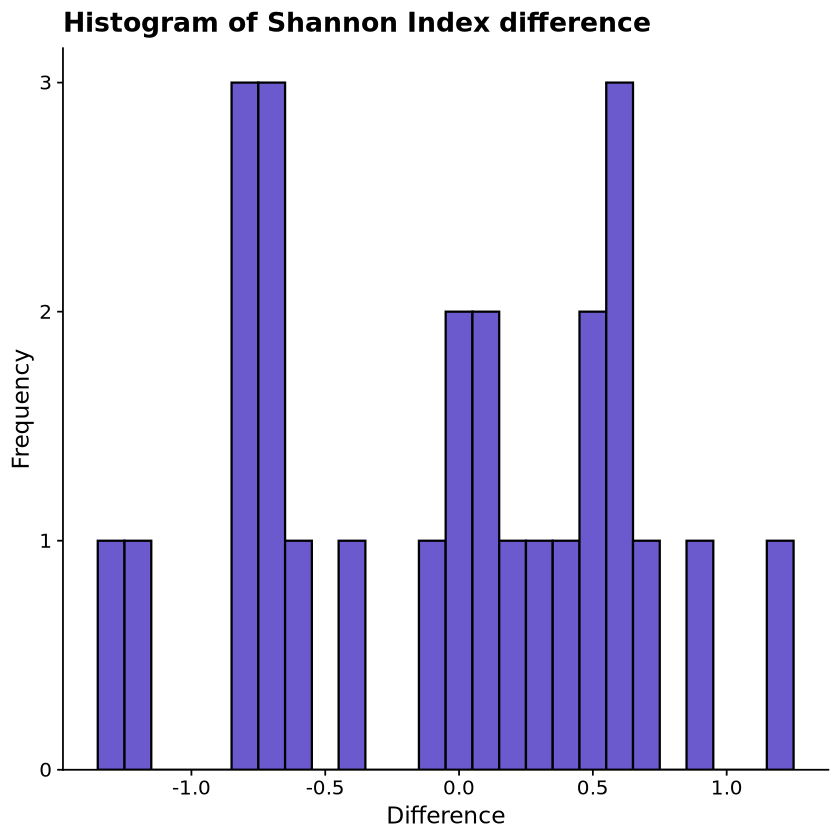

In [40]:
# View the distribution
shannon_wide_tp1 |> ggplot(aes(x = difference)) + 
  geom_histogram(binwidth = 0.1, position = "identity", fill = "slateblue", col = "black") + 
  labs(
    title = "Histogram of Shannon Index difference",
    x = "Difference",
    y = "Frequency"
  ) + 
  scale_y_continuous(
    # Don't expand y scale at the lower end
    expand = expansion(mult = c(0, 0.05))
  ) +
  theme_half_open()

In [328]:
# Paired Wilcoxon signed-rank test
result_shan_tp1 <- wilcox.test(
  shannon_wide_tp1$Nulliparous,
  shannon_wide_tp1$Primiparous,
  paired = TRUE,
  conf.int = TRUE)

result_shan_tp1

# Extract p-value
shan_tp1_p <- result_shan_tp1$p.value
shan_tp1_p


	Wilcoxon signed rank exact test

data:  shannon_wide_tp1$Nulliparous and shannon_wide_tp1$Primiparous
V = 220, p-value = 0.2687
alternative hypothesis: true location shift is not equal to 0
95 percent confidence interval:
 -0.0350029  0.2198246
sample estimates:
(pseudo)median 
    0.03729629 


[1] 0.2687066

In [329]:
summary(fp_sr_tp1)
summary(sp_sr_tp1)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   3.00    7.00   11.50   16.62   28.25   38.00 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   3.00    5.25   10.00   11.23   15.75   25.00 

In [52]:
# New df including richness
df_richness_tp1 <-  data.frame(Species_richness = c(fp_sr_tp1, sp_sr_tp1), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_sr_tp1), length(sp_sr_tp1))))
head(df_richness_tp1)

,Species_richness,Group
,<int>,<chr>
FF00653546,29,Nulliparous
FB02825409,24,Nulliparous
FF02015345,17,Nulliparous
FF00653065,8,Nulliparous
FF02014263,3,Nulliparous
FF02015432,37,Nulliparous


In [53]:
# Calculate difference for Shapiro test
df_richness_tp1_1 <- df_richness_tp1 |>
  rownames_to_column(var = "Sample_ID")
head(df_richness_tp1_1)

,Sample_ID,Species_richness,Group
,<chr>,<int>,<chr>
1,FF00653546,29,Nulliparous
2,FB02825409,24,Nulliparous
3,FF02015345,17,Nulliparous
4,FF00653065,8,Nulliparous
5,FF02014263,3,Nulliparous
6,FF02015432,37,Nulliparous


In [54]:
# Extract personal numbers for barcodes and add new column with pn to df_richness_1
df_richness_tp1_1 <- df_richness_tp1_1 |>
  left_join(
    combined_fp_sp_tp1 |>
      select(
        kit1.vaginal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit1.vaginal_sample.barcode")
  )
head(df_richness_tp1_1 )

,Sample_ID,Species_richness,Group,Q1_Personnummer
,<chr>,<int>,<chr>,<chr>
1,FF00653546,29,Nulliparous,P1f95844
2,FB02825409,24,Nulliparous,P3db7da6
3,FF02015345,17,Nulliparous,Pf573f67
4,FF00653065,8,Nulliparous,P92b4604
5,FF02014263,3,Nulliparous,P159f9c8
6,FF02015432,37,Nulliparous,Pbe289c8


In [333]:
# Test data distribution
richness_wide_tp1$difference <- richness_wide_tp1$Primiparous - richness_wide_tp1$Nulliparous
shapiro.test(richness_wide_tp1$difference)


	Shapiro-Wilk normality test

data:  richness_wide_tp1$difference
W = 0.98671, p-value = 0.9763


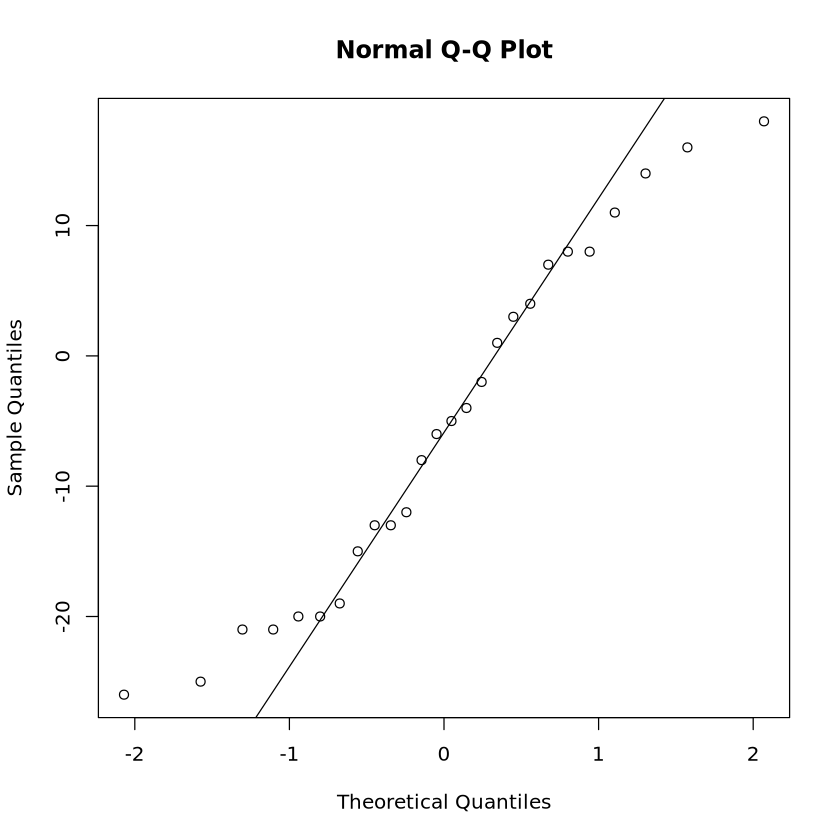

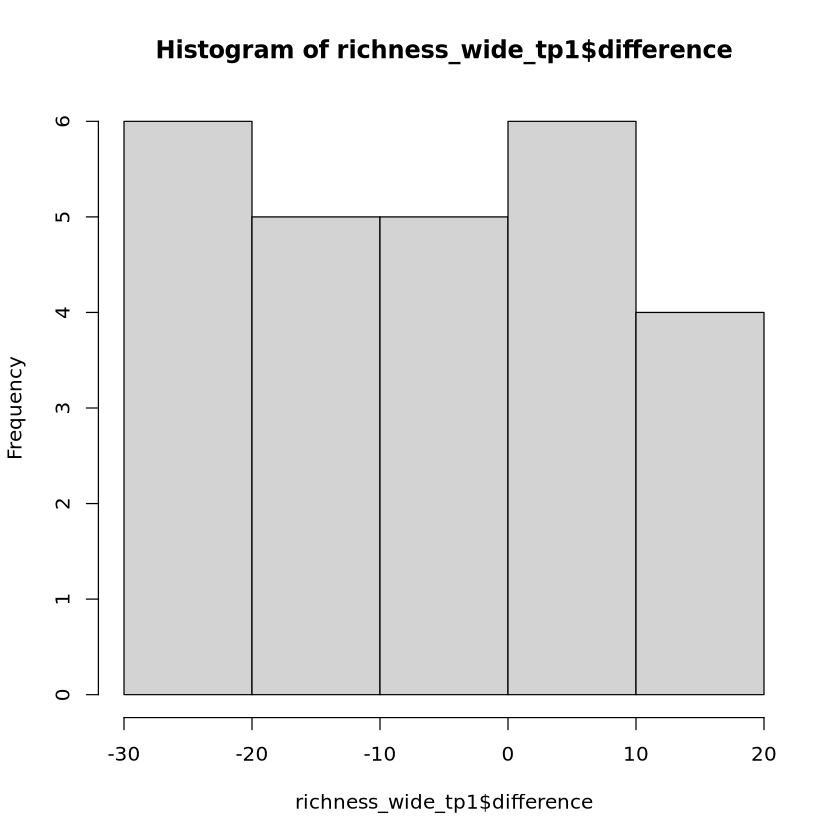

In [50]:
# Data distribution visualization
qqnorm(richness_wide_tp1$difference ); qqline(richness_wide_tp1$difference )
hist(richness_wide_tp1$difference )

In [48]:
head(shannon_wide_tp1)

Q1_Personnummer,Nulliparous,Primiparous,difference
<chr>,<dbl>,<dbl>,<dbl>
P1f95844,0.13195913,0.39400740,0.26204827
P3db7da6,1.29491833,0.59364839,-0.70126994
Pf573f67,0.79838981,0.03352297,-0.76486684
P92b4604,0.08743932,0.92454435,0.83710503
P159f9c8,0.00411877,0.02008295,0.01596418
Pbe289c8,0.78158728,0.54375596,-0.23783132


In [334]:
result_rich_tp1 <- t.test(
  richness_wide_tp1$Nulliparous,
  richness_wide_tp1$Primiparous,
  paired = TRUE)
result_rich_tp1


	Paired t-test

data:  richness_wide_tp1$Nulliparous and richness_wide_tp1$Primiparous
t = 2.7089, df = 25, p-value = 0.01201
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 1.290842 9.478388
sample estimates:
mean difference 
       5.384615 


In [335]:
rich_tp1_p <- result_rich_tp1$p.value
rich_tp1_p

[1] 0.01200676

In [336]:
summary(fp_even_tp1)
summary(sp_even_tp1)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.003254 0.034041 0.130458 0.174060 0.309704 0.471387 

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.000831 0.022049 0.208871 0.178029 0.307227 0.370384 

In [55]:
df_evenness_tp1 <-  data.frame(Evenness = c(fp_even_tp1, sp_even_tp1), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_even_tp1), length(sp_even_tp1))))
head(df_evenness_tp1)
class(df_evenness_tp1$Evenness)

,Evenness,Group
,<dbl>,<chr>
FF00653546,0.039188457,Nulliparous
FB02825409,0.407456387,Nulliparous
FF02015345,0.281796573,Nulliparous
FF00653065,0.042049425,Nulliparous
FF02014263,0.003749066,Nulliparous
FF02015432,0.216451135,Nulliparous


[1] "numeric"

In [56]:
df_evenness_tp1 <- df_evenness_tp1 |>
  rownames_to_column(var = "Sample_ID")
head(df_evenness_tp1)

,Sample_ID,Evenness,Group
,<chr>,<dbl>,<chr>
1,FF00653546,0.039188457,Nulliparous
2,FB02825409,0.407456387,Nulliparous
3,FF02015345,0.281796573,Nulliparous
4,FF00653065,0.042049425,Nulliparous
5,FF02014263,0.003749066,Nulliparous
6,FF02015432,0.216451135,Nulliparous


In [57]:
# Extract personal numbers for barcodes and add new column with pn
df_evenness_tp1 <- df_evenness_tp1|>
  left_join(
    combined_fp_sp_tp1 |>
      select(
        kit1.vaginal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit1.vaginal_sample.barcode")
  )
head(df_evenness_tp1)

,Sample_ID,Evenness,Group,Q1_Personnummer
,<chr>,<dbl>,<chr>,<chr>
1,FF00653546,0.039188457,Nulliparous,P1f95844
2,FB02825409,0.407456387,Nulliparous,P3db7da6
3,FF02015345,0.281796573,Nulliparous,Pf573f67
4,FF00653065,0.042049425,Nulliparous,P92b4604
5,FF02014263,0.003749066,Nulliparous,P159f9c8
6,FF02015432,0.216451135,Nulliparous,Pbe289c8


In [58]:
evenness_wide_tp1 <- df_evenness_tp1 |>
  select(Q1_Personnummer, Group, Evenness) |>
  pivot_wider(
    names_from = Group,
    values_from = Evenness
  )
head(evenness_wide_tp1)

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<dbl>,<dbl>
P1f95844,0.039188457,0.129415172
P3db7da6,0.407456387,0.257818219
Pf573f67,0.281796573,0.020828993
P92b4604,0.042049425,0.319870392
P159f9c8,0.003749066,0.009140144
Pbe289c8,0.216451135,0.175913456


In [341]:
evenness_wide_tp1$difference <- evenness_wide_tp1$Primiparous - evenness_wide_tp1$Nulliparous
shapiro.test(evenness_wide_tp1$difference)


	Shapiro-Wilk normality test

data:  evenness_wide_tp1$difference
W = 0.92642, p-value = 0.06371


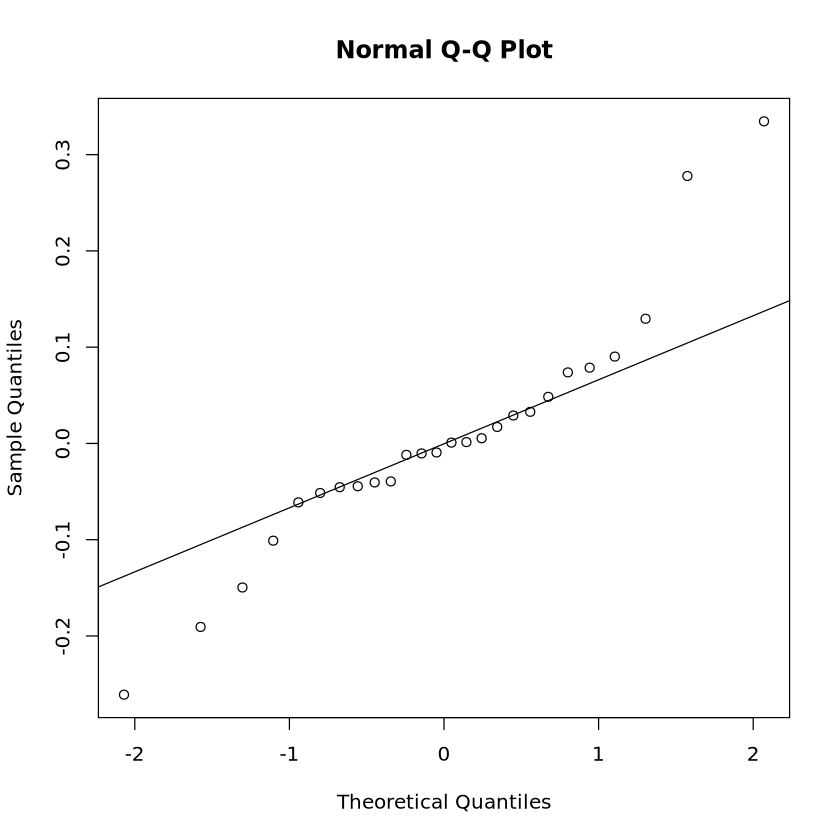

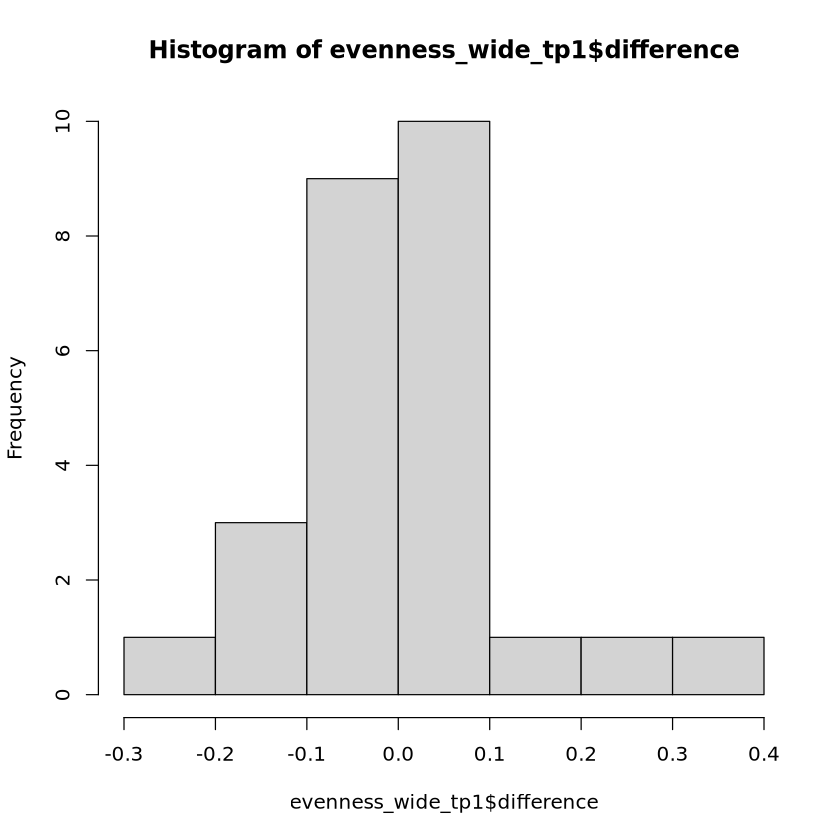

In [57]:
qqnorm(evenness_wide_tp1$difference); qqline(evenness_wide_tp1$difference)
hist(evenness_wide_tp1$difference)

In [342]:
result_evenness <- t.test(
  evenness_wide_tp1$Nulliparous,
  evenness_wide_tp1$Primiparous,
  paired = TRUE)

result_evenness


	Paired t-test

data:  evenness_wide_tp1$Nulliparous and evenness_wide_tp1$Primiparous
t = -0.16395, df = 25, p-value = 0.8711
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -0.05382314  0.04588568
sample estimates:
mean difference 
   -0.003968731 


In [343]:
even_tp1_p <- result_evenness$p.value
even_tp1_p

[1] 0.8710868

### 4.3 Compare nulliparous vs primiparous at TP2 (paired)

In [344]:
summary(fp_shan_tp2)
summary(sp_shan_tp2)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.02133 0.12299 0.56885 0.62131 0.97515 1.81931 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.02682 0.34428 0.62002 0.57932 0.76530 1.31875 

In [62]:
# Save shannon index into one df
df_shannon_tp2 <- data.frame(Shannon = c(fp_shan_tp2, sp_shan_tp2), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_shan_tp2), length(sp_shan_tp2))))
head(df_shannon_tp2)

,Shannon,Group
,<dbl>,<chr>
FF02740612,0.76653316,Nulliparous
FF02014450,0.03229818,Nulliparous
FF02014344,0.66269445,Nulliparous
FF03816858,0.15667443,Nulliparous
FF02557245,0.47500754,Nulliparous
FF02015423,0.17692788,Nulliparous


In [63]:
df_shannon_tp2_1 <- df_shannon_tp2 |>
  rownames_to_column(var = "Sample_ID")
df_shannon_tp2_1 |> head()

,Sample_ID,Shannon,Group
,<chr>,<dbl>,<chr>
1,FF02740612,0.76653316,Nulliparous
2,FF02014450,0.03229818,Nulliparous
3,FF02014344,0.66269445,Nulliparous
4,FF03816858,0.15667443,Nulliparous
5,FF02557245,0.47500754,Nulliparous
6,FF02015423,0.17692788,Nulliparous


In [64]:
# Extract personal numbers for barcodes and add new column with pn 
df_shannon_tp2_1 <- df_shannon_tp2_1|>
  left_join(
    combined_fp_sp_tp2 |>
      select(
        kit2.vaginal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit2.vaginal_sample.barcode")
  )
head(df_shannon_tp2_1)

,Sample_ID,Shannon,Group,Q1_Personnummer
,<chr>,<dbl>,<chr>,<chr>
1,FF02740612,0.76653316,Nulliparous,Pdab1897
2,FF02014450,0.03229818,Nulliparous,P719b21e
3,FF02014344,0.66269445,Nulliparous,P9cdfd5a
4,FF03816858,0.15667443,Nulliparous,P3cac7b0
5,FF02557245,0.47500754,Nulliparous,P97574f9
6,FF02015423,0.17692788,Nulliparous,P4de45e7


In [348]:
shannon_wide_tp2 <- df_shannon_tp2_1 |>
  select(Q1_Personnummer
, Group, Shannon) |>
  pivot_wider(
    names_from = Group,
    values_from = Shannon
    )
shannon_wide_tp2 |> head()

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<dbl>,<dbl>
Pdab1897,0.76653316,0.69651175
P719b21e,0.03229818,0.85778958
P9cdfd5a,0.66269445,0.59116253
P3cac7b0,0.15667443,0.02682185
P97574f9,0.47500754,0.37445989
P4de45e7,0.17692788,1.31874981


In [349]:
# Calculate the difference between groups and perform distribution test 
shannon_wide_tp2$difference <- shannon_wide_tp2$Primiparous - shannon_wide_tp2$Nulliparous
shapiro.test(shannon_wide_tp2$difference)


	Shapiro-Wilk normality test

data:  shannon_wide_tp2$difference
W = 0.96283, p-value = 0.7132


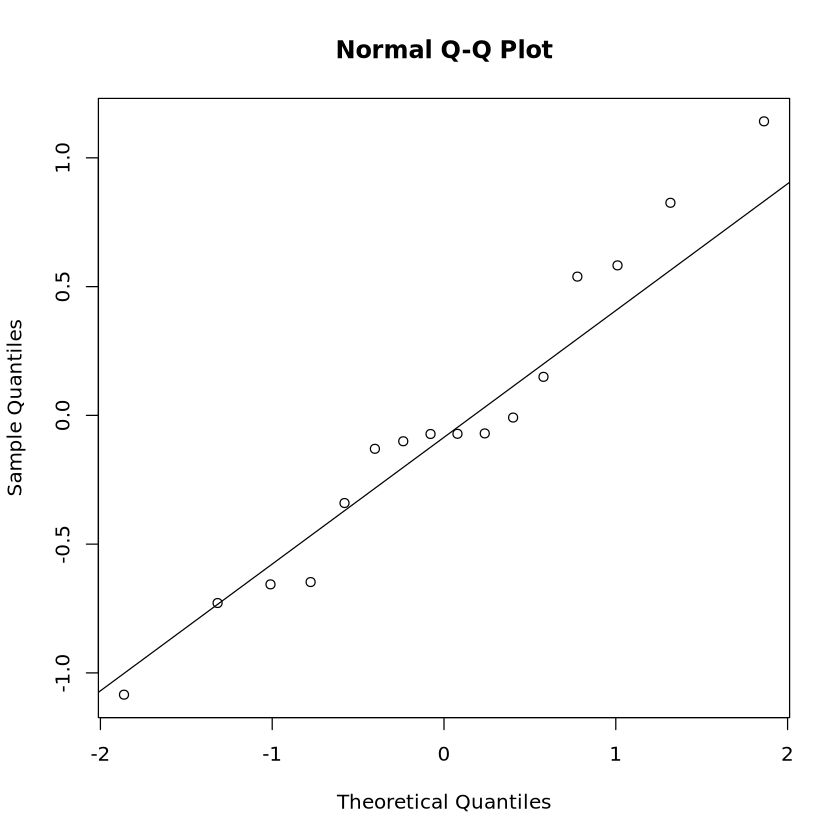

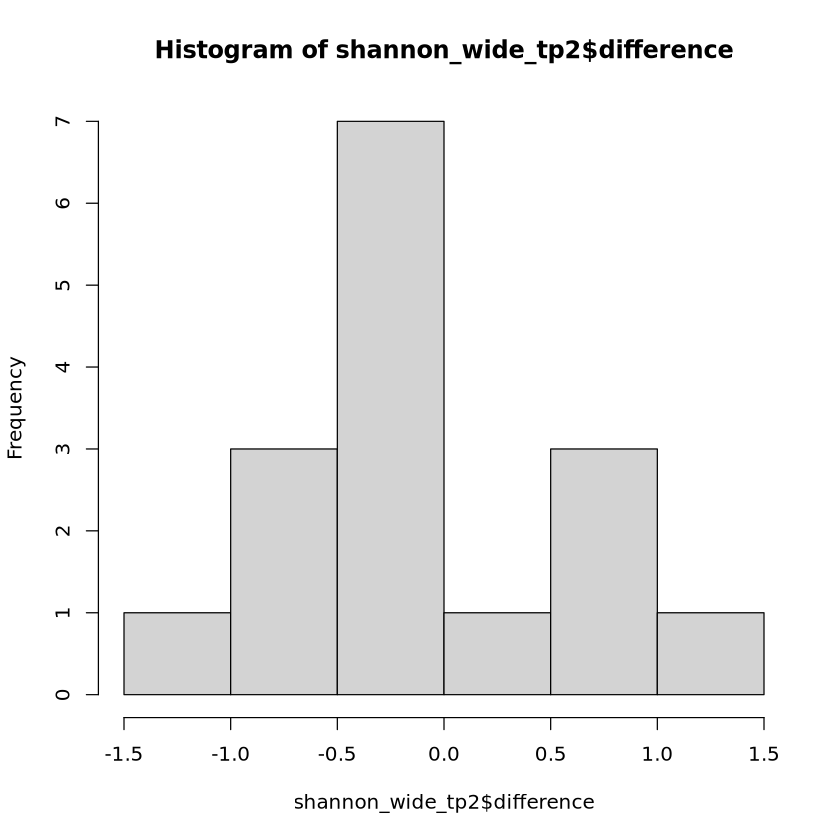

In [350]:
qqnorm(shannon_wide_tp2$difference); qqline(shannon_wide_tp2$difference)
hist(shannon_wide_tp2$difference)

In [351]:
result_shan_tp2 <- t.test(
  shannon_wide_tp2$Nulliparous,
  shannon_wide_tp2$Primiparous,
  paired = TRUE,
)

result_shan_tp2

shan_tp2_p <- result_shan_tp2$p.value
shan_tp2_p


	Paired t-test

data:  shannon_wide_tp2$Nulliparous and shannon_wide_tp2$Primiparous
t = 0.28191, df = 15, p-value = 0.7819
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -0.2754775  0.3594546
sample estimates:
mean difference 
     0.04198858 


[1] 0.7818655

In [128]:
summary(fp_sr_tp2)
summary(sp_sr_tp2)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   5.00    9.75   14.00   16.19   22.75   34.00 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   3.00    6.00   12.00   14.62   22.00   34.00 

In [65]:
df_richness_tp2 <-  data.frame(Species_richness = c(fp_sr_tp2, sp_sr_tp2), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_sr_tp2), length(sp_sr_tp2))))
head(df_richness_tp2)

,Species_richness,Group
,<int>,<chr>
FF02740612,16,Nulliparous
FF02014450,15,Nulliparous
FF02014344,11,Nulliparous
FF03816858,6,Nulliparous
FF02557245,5,Nulliparous
FF02015423,11,Nulliparous


In [66]:
# Calculate difference for Shapiro test
df_richness_tp2_1 <- df_richness_tp2 |>
  rownames_to_column(var = "Sample_ID")
df_richness_tp2_1 |> head()

,Sample_ID,Species_richness,Group
,<chr>,<int>,<chr>
1,FF02740612,16,Nulliparous
2,FF02014450,15,Nulliparous
3,FF02014344,11,Nulliparous
4,FF03816858,6,Nulliparous
5,FF02557245,5,Nulliparous
6,FF02015423,11,Nulliparous


In [67]:
# Extract personal numbers for barcodes and add new column with pn 
df_richness_tp2_1 <- df_richness_tp2_1 |>
  left_join(
    combined_fp_sp_tp2 |>
      select(
        kit2.vaginal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit2.vaginal_sample.barcode")
  )
head(df_richness_tp2_1)

,Sample_ID,Species_richness,Group,Q1_Personnummer
,<chr>,<int>,<chr>,<chr>
1,FF02740612,16,Nulliparous,Pdab1897
2,FF02014450,15,Nulliparous,P719b21e
3,FF02014344,11,Nulliparous,P9cdfd5a
4,FF03816858,6,Nulliparous,P3cac7b0
5,FF02557245,5,Nulliparous,P97574f9
6,FF02015423,11,Nulliparous,P4de45e7


In [355]:
richness_wide_tp2 <- df_richness_tp2_1 |>
  select(Q1_Personnummer, Group, Species_richness) |>
  pivot_wider(
             names_from = Group,
             values_from = Species_richness
           )
richness_wide_tp2 |> head()

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<int>,<int>
Pdab1897,16,6
P719b21e,15,25
P9cdfd5a,11,3
P3cac7b0,6,4
P97574f9,5,22
P4de45e7,11,19


In [356]:
# Test data distribution
richness_wide_tp2$difference <- richness_wide_tp2$Primiparous - richness_wide_tp2$Nulliparous
shapiro.test(richness_wide_tp2$difference)


	Shapiro-Wilk normality test

data:  richness_wide_tp2$difference
W = 0.92457, p-value = 0.1997


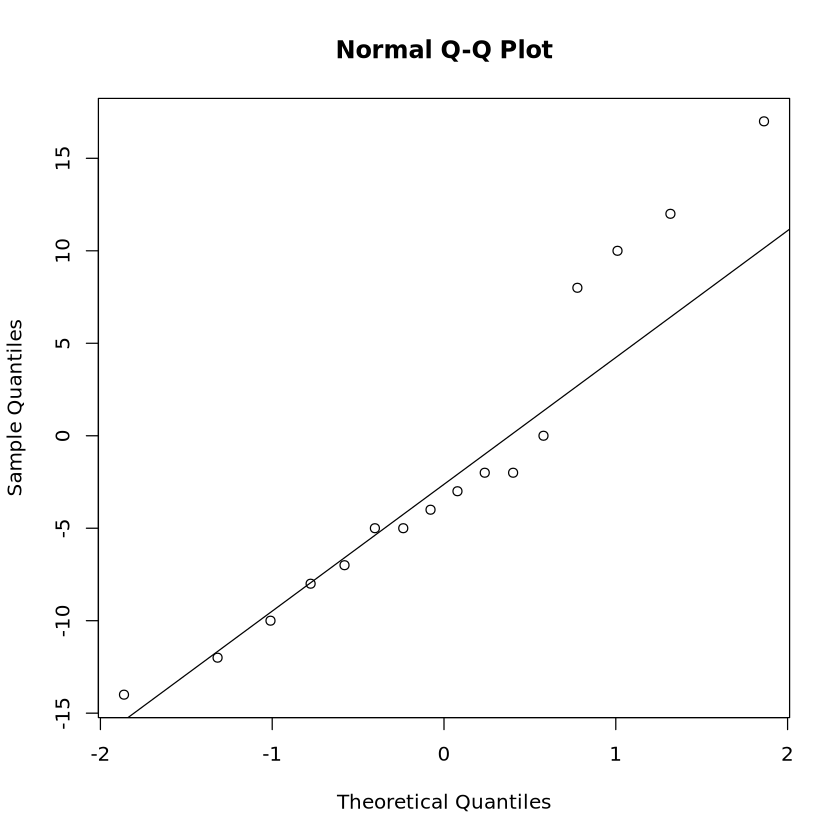

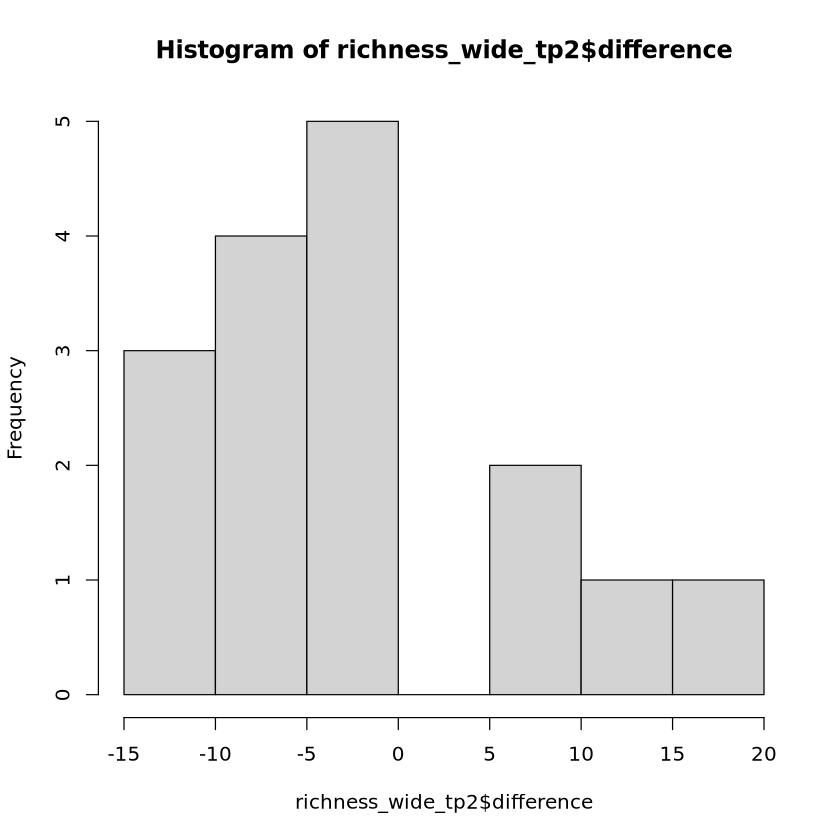

In [73]:
qqnorm(richness_wide_tp2$difference); qqline(richness_wide_tp2$difference)
hist(richness_wide_tp2$difference)

In [357]:
result_rich_tp2 <- t.test(
  richness_wide_tp2$Nulliparous,
  richness_wide_tp2$Primiparous,
  paired = TRUE
)

result_rich_tp2

# Extract p-value
rich_tp2_p <- result_rich_tp2$p.value
rich_tp2_p


	Paired t-test

data:  richness_wide_tp2$Nulliparous and richness_wide_tp2$Primiparous
t = 0.70054, df = 15, p-value = 0.4943
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -3.191512  6.316512
sample estimates:
mean difference 
         1.5625 


[1] 0.4943121

In [75]:
summary(fp_even_tp2)
summary(sp_even_tp2) 

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.009709 0.046848 0.274014 0.223339 0.352916 0.540287 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.01935 0.12809 0.24484 0.24621 0.35627 0.53810 

In [73]:
df_evenness_tp2 <-  data.frame(Evenness = c(fp_even_tp2, sp_even_tp2), Group = rep(c("Nulliparous", "Primiparous"), times = c(length(fp_even_tp2), length(sp_even_tp2))))
head(df_evenness_tp2)
class(df_evenness_tp2$Evenness)

,Evenness,Group
,<dbl>,<chr>
FF02740612,0.27646840,Nulliparous
FF02014450,0.01192673,Nulliparous
FF02014344,0.27636505,Nulliparous
FF03816858,0.08744167,Nulliparous
FF02557245,0.29513878,Nulliparous
FF02015423,0.07378466,Nulliparous


[1] "numeric"

In [74]:
df_evenness_tp2_1 <- df_evenness_tp2 |>
  rownames_to_column(var = "Sample_ID")
head(df_evenness_tp2)

,Evenness,Group
,<dbl>,<chr>
FF02740612,0.27646840,Nulliparous
FF02014450,0.01192673,Nulliparous
FF02014344,0.27636505,Nulliparous
FF03816858,0.08744167,Nulliparous
FF02557245,0.29513878,Nulliparous
FF02015423,0.07378466,Nulliparous


In [75]:
# Extract personal numbers for barcodes and add new column with pn 
df_evenness_tp2_1 <- df_evenness_tp2_1|>
  left_join(
    combined_fp_sp_tp2 |>
      select(
        kit2.vaginal_sample.barcode ,
        Q1_Personnummer
      ),
    by = c("Sample_ID" = "kit2.vaginal_sample.barcode")
  )
head(df_evenness_tp2_1)

,Sample_ID,Evenness,Group,Q1_Personnummer
,<chr>,<dbl>,<chr>,<chr>
1,FF02740612,0.27646840,Nulliparous,Pdab1897
2,FF02014450,0.01192673,Nulliparous,P719b21e
3,FF02014344,0.27636505,Nulliparous,P9cdfd5a
4,FF03816858,0.08744167,Nulliparous,P3cac7b0
5,FF02557245,0.29513878,Nulliparous,P97574f9
6,FF02015423,0.07378466,Nulliparous,P4de45e7


In [361]:
evenness_wide_tp2 <- df_evenness_tp2_1 |>
  select(Q1_Personnummer, Group, Evenness) |>
  pivot_wider(
    names_from = Group,
    values_from = Evenness
  )
head(evenness_wide_tp2)

Q1_Personnummer,Nulliparous,Primiparous
<chr>,<dbl>,<dbl>
Pdab1897,0.27646840,0.38873061
P719b21e,0.01192673,0.26648732
P9cdfd5a,0.27636505,0.53809932
P3cac7b0,0.08744167,0.01934787
P97574f9,0.29513878,0.12114356
P4de45e7,0.07378466,0.44787812


In [139]:
evenness_wide_tp2$difference <- evenness_wide_tp2$Primiparous - evenness_wide_tp2$Nulliparous
shapiro.test(evenness_wide_tp2$difference)


	Shapiro-Wilk normality test

data:  evenness_wide_tp2$difference
W = 0.96395, p-value = 0.7337


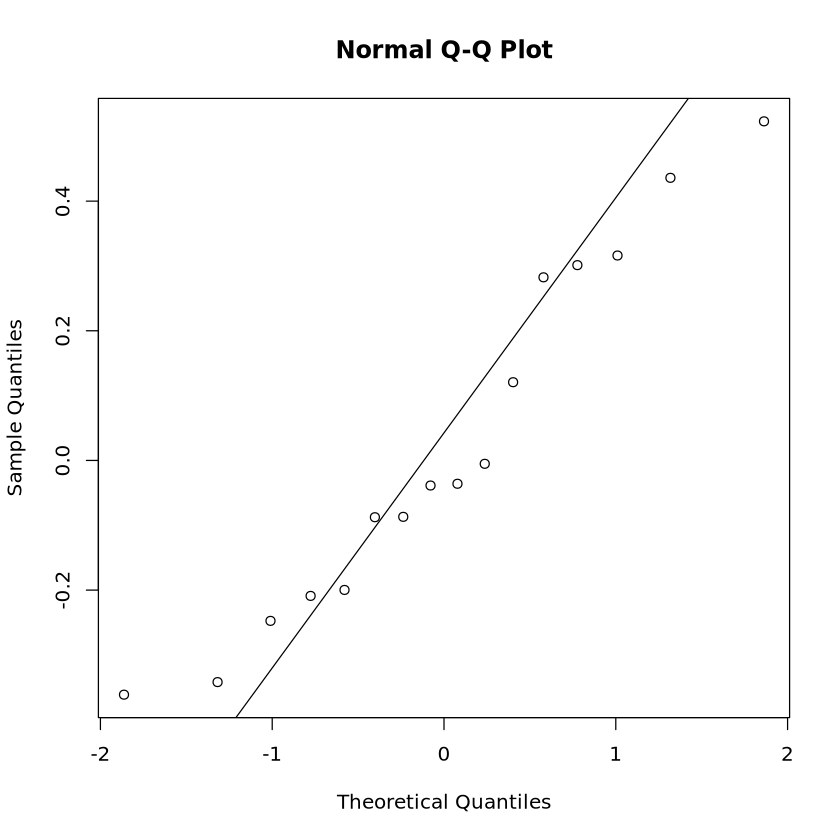

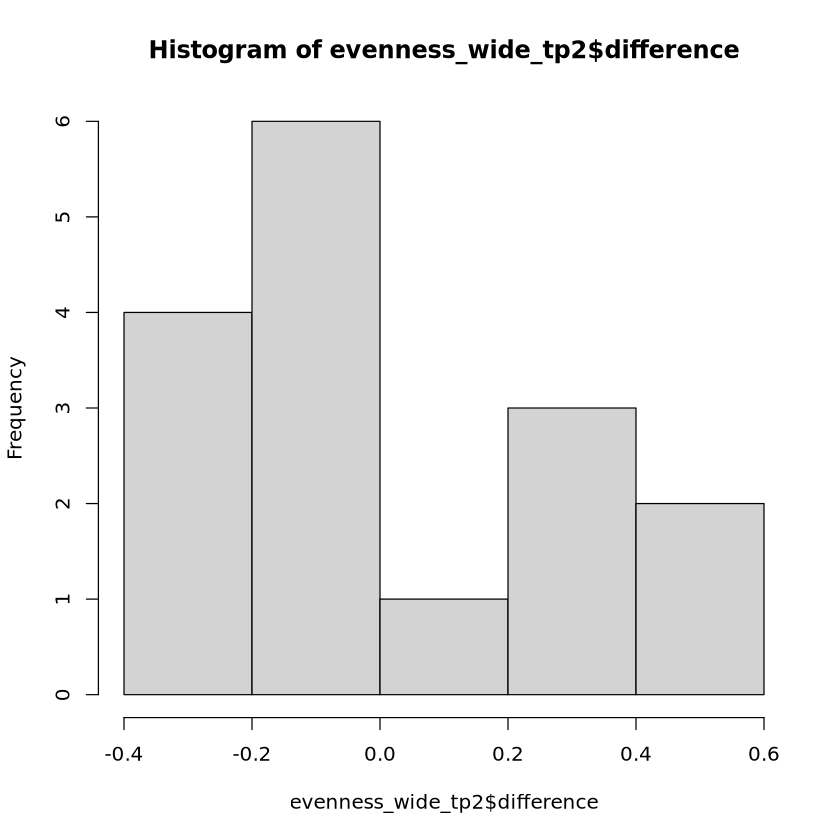

In [88]:
qqnorm(evenness_wide_tp2$difference); qqline(evenness_wide_tp2$difference)
hist(evenness_wide_tp2$difference)

In [362]:
# Paired t-test
result_evenness_tp2 <- t.test(
  evenness_wide_tp2$Nulliparous,
  evenness_wide_tp2$Primiparous,
  paired = TRUE)

result_evenness_tp2

# Extract p-value
evenness_p_tp2 <- result_evenness_tp2$p.value
evenness_p_tp2


	Paired t-test

data:  evenness_wide_tp2$Nulliparous and evenness_wide_tp2$Primiparous
t = -0.41436, df = 15, p-value = 0.6845
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -0.14049211  0.09475841
sample estimates:
mean difference 
    -0.02286685 


[1] 0.6844732

## 5. Delta alpha diversity (within-subject change, TP1→TP2)

For each woman, the change in each alpha diversity metric from TP1 to TP2,
calculated separately for her first and second pregnancy.

In [76]:
df_alpha_tp1 <- df_shannon_tp1_1 %>%
  full_join(df_richness_tp1_1, by = c("Sample_ID", "Group", "Q1_Personnummer")) %>%
  full_join(df_evenness_tp1 ,   by = c("Sample_ID", "Group", "Q1_Personnummer")) %>%
  mutate(Time_point = "TP1")
head(df_alpha_tp1 )

,Sample_ID,Shannon,Group,Q1_Personnummer,Species_richness,Evenness,Time_point
,<chr>,<dbl>,<chr>,<chr>,<int>,<dbl>,<chr>
1,FF00653546,0.13195913,Nulliparous,P1f95844,29,0.039188457,TP1
2,FB02825409,1.29491833,Nulliparous,P3db7da6,24,0.407456387,TP1
3,FF02015345,0.79838981,Nulliparous,Pf573f67,17,0.281796573,TP1
4,FF00653065,0.08743932,Nulliparous,P92b4604,8,0.042049425,TP1
5,FF02014263,0.00411877,Nulliparous,P159f9c8,3,0.003749066,TP1
6,FF02015432,0.78158728,Nulliparous,Pbe289c8,37,0.216451135,TP1


In [77]:
nrow(df_alpha_tp1)          
nrow(df_shannon_tp1_1) 

[1] 52

[1] 52

In [78]:
df_alpha_tp2 <- df_shannon_tp2_1 %>%
  full_join(df_richness_tp2_1, by = c("Sample_ID", "Group", "Q1_Personnummer")) %>%
  full_join(df_evenness_tp2_1,   by = c("Sample_ID", "Group", "Q1_Personnummer")) %>%
  mutate(Time_point = "TP2")

head(df_alpha_tp2)

,Sample_ID,Shannon,Group,Q1_Personnummer,Species_richness,Evenness,Time_point
,<chr>,<dbl>,<chr>,<chr>,<int>,<dbl>,<chr>
1,FF02740612,0.76653316,Nulliparous,Pdab1897,16,0.27646840,TP2
2,FF02014450,0.03229818,Nulliparous,P719b21e,15,0.01192673,TP2
3,FF02014344,0.66269445,Nulliparous,P9cdfd5a,11,0.27636505,TP2
4,FF03816858,0.15667443,Nulliparous,P3cac7b0,6,0.08744167,TP2
5,FF02557245,0.47500754,Nulliparous,P97574f9,5,0.29513878,TP2
6,FF02015423,0.17692788,Nulliparous,P4de45e7,11,0.07378466,TP2


In [79]:
nrow(df_alpha_tp2)          
nrow(df_shannon_tp2_1) 

[1] 32

[1] 32

In [80]:
df_alpha_tp1_1 <- df_alpha_tp1 %>% filter(Q1_Personnummer %in% df_alpha_tp2$Q1_Personnummer)
dim(df_alpha_tp1_1)

[1] 32  7

In [81]:
all_alpha <- bind_rows(df_alpha_tp1_1,df_alpha_tp2) 
#all_alpha 

### 5.1 Calculate delta alpha (TP2 − TP1) per pregnancy

In [82]:
# Reshape so each woman/group has TP1 and TP2 side by side, for all three metrics
alpha_wide <- all_alpha %>%
  pivot_wider(
    id_cols = c(Q1_Personnummer, Group),
    names_from = Time_point,
    values_from = c(Sample_ID, Shannon, Species_richness, Evenness)
  )

head(alpha_wide)

Q1_Personnummer,Group,Sample_ID_TP1,Sample_ID_TP2,Shannon_TP1,Shannon_TP2,Species_richness_TP1,Species_richness_TP2,Evenness_TP1,Evenness_TP2
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>
P1f95844,Nulliparous,FF00653546,FF02014735,0.13195913,0.06640487,29,22,0.039188457,0.021483002
P3db7da6,Nulliparous,FB02825409,FF02015861,1.29491833,1.34955333,24,21,0.407456387,0.443272585
P159f9c8,Nulliparous,FF02014263,FF00531801,0.00411877,0.02133239,3,9,0.003749066,0.009708788
Pbe289c8,Nulliparous,FF02015432,FF00619973,0.78158728,1.26489770,37,25,0.216451135,0.392962566
P9cdfd5a,Nulliparous,FF00653167,FF02014344,0.57158167,0.66269445,6,11,0.319005803,0.276365053
P3cac7b0,Nulliparous,FF02557868,FF03816858,0.08968643,0.15667443,4,6,0.064695081,0.087441666


In [83]:
# Calculate delta (TP2 - TP1) for each metric
alpha_delta <- alpha_wide %>%
  mutate(
    delta_Shannon  = Shannon_TP2  - Shannon_TP1,
    delta_Richness = Species_richness_TP2 - Species_richness_TP1,
    delta_Evenness = Evenness_TP2 - Evenness_TP1
  )

head(alpha_delta)


Q1_Personnummer,Group,Sample_ID_TP1,Sample_ID_TP2,Shannon_TP1,Shannon_TP2,Species_richness_TP1,Species_richness_TP2,Evenness_TP1,Evenness_TP2,delta_Shannon,delta_Richness,delta_Evenness
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
P1f95844,Nulliparous,FF00653546,FF02014735,0.13195913,0.06640487,29,22,0.039188457,0.021483002,-0.06555426,-7,-0.017705456
P3db7da6,Nulliparous,FB02825409,FF02015861,1.29491833,1.34955333,24,21,0.407456387,0.443272585,0.05463500,-3,0.035816198
P159f9c8,Nulliparous,FF02014263,FF00531801,0.00411877,0.02133239,3,9,0.003749066,0.009708788,0.01721362,6,0.005959722
Pbe289c8,Nulliparous,FF02015432,FF00619973,0.78158728,1.26489770,37,25,0.216451135,0.392962566,0.48331043,-12,0.176511432
P9cdfd5a,Nulliparous,FF00653167,FF02014344,0.57158167,0.66269445,6,11,0.319005803,0.276365053,0.09111279,5,-0.042640750
P3cac7b0,Nulliparous,FF02557868,FF03816858,0.08968643,0.15667443,4,6,0.064695081,0.087441666,0.06698801,2,0.022746585


In [84]:
dim(alpha_delta)

[1] 32 13

In [85]:
alpha_delta_N <- alpha_delta %>% filter(Group == "Nulliparous")
dim(alpha_delta_N )
#alpha_delta_N

[1] 16 13

In [86]:
alpha_delta_P <- alpha_delta %>% filter(Group == "Primiparous")
dim(alpha_delta_P )
#alpha_delta_P

[1] 16 13

### 5.2 Compare delta alpha between pregnancies (paired)

Tests whether the amount and direction of diversity change across gestation
differs between the first and second pregnancy.

In [87]:
shan_difference <- alpha_delta_P$delta_Shannon - alpha_delta_N$delta_Shannon
shapiro.test(shan_difference)


	Shapiro-Wilk normality test

data:  shan_difference
W = 0.96219, p-value = 0.7017


In [88]:
delta_shan <- t.test(alpha_delta_N$delta_Shannon, alpha_delta_P$delta_Shannon, paired = TRUE)
delta_shan 
delta_shan_p <- delta_shan$p.value


	Paired t-test

data:  alpha_delta_N$delta_Shannon and alpha_delta_P$delta_Shannon
t = 0.02569, df = 15, p-value = 0.9798
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -0.3127742  0.3204058
sample estimates:
mean difference 
    0.003815821 


In [89]:
rich_difference <- alpha_delta_P$delta_Richness - alpha_delta_N$delta_Richness
shapiro.test(rich_difference)


	Shapiro-Wilk normality test

data:  rich_difference
W = 0.84285, p-value = 0.01071


In [90]:
# Paired Wilcoxon signed-rank test
delta_rich <- wilcox.test(
  alpha_delta_N$delta_Richness,
  alpha_delta_P$delta_Richness,
  paired = TRUE,
  exact = FALSE,
  conf.int = TRUE)

delta_rich

# Extract p-value
delta_rich_p <- delta_rich$p.value
delta_rich_p


	Wilcoxon signed rank test with continuity correction

data:  alpha_delta_N$delta_Richness and alpha_delta_P$delta_Richness
V = 39, p-value = 0.2434
alternative hypothesis: true location shift is not equal to 0
95 percent confidence interval:
 -13.500016   1.499983
sample estimates:
(pseudo)median 
     -4.196585 


[1] 0.2434365

In [377]:
even_difference <- alpha_delta_P$delta_Evenness - alpha_delta_N$delta_Evenness
shapiro.test(even_difference)


	Shapiro-Wilk normality test

data:  even_difference
W = 0.96833, p-value = 0.8109


In [91]:
delta_even <- t.test(alpha_delta_N$delta_Evenness, alpha_delta_P$delta_Evenness, paired = TRUE)
delta_even 
delta_even_p <- delta_even$p.value


	Paired t-test

data:  alpha_delta_N$delta_Evenness and alpha_delta_P$delta_Evenness
t = 0.011742, df = 15, p-value = 0.9908
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -0.1088309  0.1100366
sample estimates:
mean difference 
   0.0006028578 


## 6. Beta diversity 

In [174]:
head(combined_fp_sp_tp1)
head(combined_fp_sp_tp2)

,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP1
2,5301,S1f862a6,NA,0,0,0,2018-03-07,P1f862a6,0,32,⋯,NA,NA,NA,31,Spontaneous,very_w28_31,1,0,Nulliparous,TP1
3,5258,S1f95844,NA,0,0,0,2018-04-10,P1f95844,0,30,⋯,NA,NA,NA,40,Spontaneous,NA,NA,0,Nulliparous,TP1
4,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,Nulliparous,TP1
5,5243,S39fe1d7,NA,0,0,0,2018-06-23,P3db7da6,0,29,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP1
6,5383,S7e4a963,NA,0,0,0,2018-02-18,P424fd61,0,37,⋯,NA,NA,NA,38,Induction,NA,NA,0,Nulliparous,TP1


,X,Studienummer,Correct_PN,Prev_RPL,Prev_IUFD,Prev_miscarriage_numb,Q1_Datum,Q1_Personnummer,Avbruten_graviditet,age_checked,⋯,IUFD,missfall,missfall.IUFD_comments,Gest_w_combined,deliv_start_combined,Type_of_PTB,s_PTB,preeclampsia_epi_analysis,Group,Time_point
,<int>,<chr>,<lgl>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,⋯,<lgl>,<lgl>,<lgl>,<int>,<chr>,<lgl>,<lgl>,<int>,<chr>,<chr>
1,5367,S194e21b,NA,0,0,0,2018-11-16,P159f9c8,0,36,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP2
2,5258,S1f95844,NA,0,0,0,2018-04-10,P1f95844,0,30,⋯,NA,NA,NA,40,Spontaneous,NA,NA,0,Nulliparous,TP2
3,5275,S2b86cc0,NA,0,0,0,2019-05-29,P3cac7b0,0,31,⋯,NA,NA,NA,39,Spontaneous,NA,NA,0,Nulliparous,TP2
4,5243,S39fe1d7,NA,0,0,0,2018-06-23,P3db7da6,0,29,⋯,NA,NA,NA,41,Spontaneous,NA,NA,0,Nulliparous,TP2
5,5383,S7e4a963,NA,0,0,0,2018-02-18,P424fd61,0,37,⋯,NA,NA,NA,38,Induction,NA,NA,0,Nulliparous,TP2
6,5239,S5fa4a39,NA,0,0,0,2018-08-30,P4de45e7,0,29,⋯,NA,NA,NA,39,Induction,NA,NA,1,Nulliparous,TP2


In [175]:
combined_fp_sp_tp1 <- combined_fp_sp_tp1 %>%
  rename(Sample_id = kit1.vaginal_sample.barcode)

combined_fp_sp_tp2<- combined_fp_sp_tp2 %>%
  rename(Sample_id = kit2.vaginal_sample.barcode)

In [176]:
meta_tp1 <- combined_fp_sp_tp1 %>% 
            select(Studienummer,Q1_Personnummer,Sample_id, Group, Time_point)
meta_tp2 <- combined_fp_sp_tp2 %>% 
           select(Studienummer,Q1_Personnummer,Sample_id, Group, Time_point)

In [177]:
rownames(meta_tp1) <- meta_tp1$Sample_id
rownames(meta_tp2) <- meta_tp2$Sample_id

In [178]:
dim(meta_tp1)
dim(meta_tp2)

[1] 52  5

[1] 32  5

In [179]:
head(meta_tp1)

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point
,<chr>,<chr>,<chr>,<chr>,<chr>
FF02014263,S194e21b,P159f9c8,FF02014263,Nulliparous,TP1
FF00653507,S1f862a6,P1f862a6,FF00653507,Nulliparous,TP1
FF00653546,S1f95844,P1f95844,FF00653546,Nulliparous,TP1
FF02557868,S2b86cc0,P3cac7b0,FF02557868,Nulliparous,TP1
FB02825409,S39fe1d7,P3db7da6,FB02825409,Nulliparous,TP1
FF00657534,S7e4a963,P424fd61,FF00657534,Nulliparous,TP1


In [180]:
tp1_taxa <-
  fp_taxa_tp1 %>%
  rownames_to_column("Species") %>%
  full_join(
    sp_taxa_tp1 %>% rownames_to_column("Species"),
    by = "Species"
  ) %>%
  column_to_rownames("Species")

tp1_taxa [is.na(tp1_taxa )] <- 0
dim(tp1_taxa )

[1] 65 52

In [181]:
head(tp1_taxa)

,FF00653546,FB02825409,FF02015345,FF00653065,FF02014263,FF02015432,FF00657563,FF00653167,FF02557868,FF02015815,⋯,FF04023664,FF06580399,FF04761460,FF01570782,FF01570777,FF05043003,FF05025300,FF05043036,FF00530247,FF03816924
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Actinobaculum massiliense,0.00000,0.00000,0.00000,0,0,0.13543,0,0,0,0.00000,⋯,0,0.00000,0.09208,0,0,0,0.00000,0.00000,0.00000,0
Aerococcus christensenii,0.00000,0.37028,0.00000,0,0,0.03476,0,0,0,0.15046,⋯,0,0.00000,0.00000,0,0,0,0.00000,2.06919,1.85412,0
Alloscardovia omnicolens,0.00000,0.00000,0.00000,0,0,0.00000,0,0,0,0.00000,⋯,0,0.04067,0.00000,0,0,0,0.00000,0.17180,0.00000,0
Anaerococcus hydrogenalis,0.00697,0.00000,0.02932,0,0,0.06614,0,0,0,0.00000,⋯,0,0.00000,0.00000,0,0,0,0.00000,0.00000,0.00000,0
Anaerococcus lactolyticus,0.01879,0.00000,0.00897,0,0,0.00000,0,0,0,0.00281,⋯,0,0.12813,0.00000,0,0,0,0.01611,0.00000,0.00000,0
Anaerococcus prevotii,0.00000,0.00000,0.00092,0,0,0.00000,0,0,0,0.00000,⋯,0,0.00000,0.00000,0,0,0,0.00000,0.00000,0.00000,0


In [182]:
tp1_taxa_1 <- as.data.frame(t(tp1_taxa))
class(tp1_taxa_1 )
head(tp1_taxa_1 )

[1] "data.frame"

,Actinobaculum massiliense,Aerococcus christensenii,Alloscardovia omnicolens,Anaerococcus hydrogenalis,Anaerococcus lactolyticus,Anaerococcus prevotii,Anaerococcus sp_Marseille_P3915,Anaerococcus tetradius,Anaerococcus vaginalis,Atopobium deltae,⋯,Staphylococcus epidermidis,Streptococcus anginosus,Streptococcus SGB3665,Tissierellia bacterium_KA00581,Ureaplasma parvum,Varibaculum cambriense,Varibaculum massiliense,Veillonellaceae bacterium_DNF00626,Winkia neuii,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FF00653546,0.00000,0.00000,0,0.00697,0.01879,0.00000,0.00623,0.00000,0.00000,0.01103,⋯,0.00000,0.00000,0,0.00000,0.00000,0.00805,0,0.02838,0,0.09977
FB02825409,0.00000,0.37028,0,0.00000,0.00000,0.00000,0.00000,0.00477,0.00000,0.00000,⋯,0.00000,0.00000,0,0.25771,0.00970,0.00000,0,0.90706,0,0.80965
FF02015345,0.00000,0.00000,0,0.02932,0.00897,0.00092,0.00000,0.00000,0.00000,0.00000,⋯,0.00000,0.01390,0,0.00000,0.00000,0.00000,0,0.01171,0,0.94319
FF00653065,0.00000,0.00000,0,0.00000,0.00000,0.00000,0.06377,0.00000,0.00000,0.00000,⋯,0.00000,0.00000,0,0.00000,1.08325,0.00000,0,0.00000,0,0.00000
FF02014263,0.00000,0.00000,0,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,⋯,0.00000,0.00000,0,0.00000,0.00000,0.00000,0,0.00000,0,0.00000
FF02015432,0.13543,0.03476,0,0.06614,0.00000,0.00000,0.07625,0.51893,0.05359,0.05284,⋯,0.01606,1.03939,0,0.00000,0.00000,0.02508,0,0.35671,0,2.76109


In [183]:
tp2_taxa <-
  fp_taxa_tp2 %>%
  rownames_to_column("Species") %>%
  full_join(
    sp_taxa_tp2 %>% rownames_to_column("Species"),
    by = "Species"
  ) %>%
  column_to_rownames("Species")

tp2_taxa [is.na(tp2_taxa )] <- 0
dim(tp2_taxa )

[1] 65 32

In [184]:
tp2_taxa_1<- as.data.frame(t(tp2_taxa))
class(tp2_taxa_1)
head(tp2_taxa_1)

[1] "data.frame"

,Actinobaculum massiliense,Aerococcus christensenii,Alloscardovia omnicolens,Anaerococcus hydrogenalis,Anaerococcus lactolyticus,Anaerococcus prevotii,Anaerococcus sp_Marseille_P3915,Anaerococcus tetradius,Anaerococcus vaginalis,Atopobium deltae,⋯,Staphylococcus epidermidis,Streptococcus anginosus,Streptococcus SGB3665,Tissierellia bacterium_KA00581,Ureaplasma parvum,Varibaculum cambriense,Varibaculum massiliense,Veillonellaceae bacterium_DNF00626,Winkia neuii,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FF02740612,0,0,0,0,0.05158,0.00686,0,0.00000,0,0.000,⋯,0,0.00101,0.00000,0,0.00000,0,0.00000,0.00000,0.00172,0.03108
FF02014450,0,0,0,0,0.00000,0.00000,0,0.00000,0,0.007,⋯,0,0.00000,0.01484,0,0.00000,0,0.00000,0.02097,0.00000,0.03626
FF02014344,0,0,0,0,0.00000,0.00000,0,0.00000,0,0.000,⋯,0,0.00000,0.02369,0,0.00000,0,0.00000,0.24073,0.00000,0.00000
FF03816858,0,0,0,0,0.00000,0.00000,0,0.00000,0,0.000,⋯,0,0.00000,0.00000,0,0.00000,0,0.00000,0.00000,0.00000,0.00000
FF02557245,0,0,0,0,0.00000,0.00000,0,0.00000,0,0.000,⋯,0,0.00000,0.00000,0,0.61766,0,0.00000,0.00000,0.00000,0.00000
FF02015423,0,0,0,0,0.00000,0.00000,0,0.03465,0,0.000,⋯,0,0.29239,0.00000,0,0.00000,0,0.00437,0.00000,0.00000,0.15873


In [185]:
ordered_taxa_tp1 <- tp1_taxa_1[rownames(meta_tp1), ]
head(ordered_taxa_tp1)

,Actinobaculum massiliense,Aerococcus christensenii,Alloscardovia omnicolens,Anaerococcus hydrogenalis,Anaerococcus lactolyticus,Anaerococcus prevotii,Anaerococcus sp_Marseille_P3915,Anaerococcus tetradius,Anaerococcus vaginalis,Atopobium deltae,⋯,Staphylococcus epidermidis,Streptococcus anginosus,Streptococcus SGB3665,Tissierellia bacterium_KA00581,Ureaplasma parvum,Varibaculum cambriense,Varibaculum massiliense,Veillonellaceae bacterium_DNF00626,Winkia neuii,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FF02014263,0,0.00000,0.00000,0.00000,0.00000,0,0.00000,0.00000,0,0.00000,⋯,0,0,0,0.00000,0.0000,0.00000,0,0.00000,0.00000,0.00000
FF00653507,0,1.96578,0.00000,0.00000,0.00000,0,0.00000,0.08090,0,0.02155,⋯,0,0,0,0.00000,0.0000,0.00000,0,0.17824,0.00000,0.12387
FF00653546,0,0.00000,0.00000,0.00697,0.01879,0,0.00623,0.00000,0,0.01103,⋯,0,0,0,0.00000,0.0000,0.00805,0,0.02838,0.00000,0.09977
FF02557868,0,0.00000,0.00000,0.00000,0.00000,0,0.00000,0.00000,0,0.00000,⋯,0,0,0,0.00000,0.0000,0.00000,0,0.00000,0.00000,0.00000
FB02825409,0,0.37028,0.00000,0.00000,0.00000,0,0.00000,0.00477,0,0.00000,⋯,0,0,0,0.25771,0.0097,0.00000,0,0.90706,0.00000,0.80965
FF00657534,0,0.78909,0.00207,0.00000,0.00299,0,0.00000,0.00000,0,0.00631,⋯,0,0,0,0.00000,0.0000,0.00996,0,0.01321,0.00463,0.40690


In [186]:
ordered_taxa_tp2 <- tp2_taxa_1[rownames(meta_tp2), ]
head(ordered_taxa_tp2)

,Actinobaculum massiliense,Aerococcus christensenii,Alloscardovia omnicolens,Anaerococcus hydrogenalis,Anaerococcus lactolyticus,Anaerococcus prevotii,Anaerococcus sp_Marseille_P3915,Anaerococcus tetradius,Anaerococcus vaginalis,Atopobium deltae,⋯,Staphylococcus epidermidis,Streptococcus anginosus,Streptococcus SGB3665,Tissierellia bacterium_KA00581,Ureaplasma parvum,Varibaculum cambriense,Varibaculum massiliense,Veillonellaceae bacterium_DNF00626,Winkia neuii,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FF00531801,0,0.00000,0.00000,0,0.00062,0.00000,0.00000,0.00000,0.0000,0,⋯,0,0.00000,0.00000,0.00000,0.00000,0.000,0.00000,0.00000,0,0.00757
FF02014735,0,0.00000,0.00000,0,0.00000,0.00927,0.01325,0.00000,0.0000,0,⋯,0,0.00000,0.00163,0.00000,0.07169,0.000,0.00000,0.00431,0,0.00746
FF03816858,0,0.00000,0.00000,0,0.00000,0.00000,0.00000,0.00000,0.0000,0,⋯,0,0.00000,0.00000,0.00000,0.00000,0.000,0.00000,0.00000,0,0.00000
FF02015861,0,0.50963,0.00000,0,0.00000,0.00000,0.00000,0.01127,0.0000,0,⋯,0,0.00000,0.00000,0.23507,0.00033,0.000,0.00000,0.21450,0,0.29344
FF00657251,0,0.65759,0.50312,0,0.13764,0.00000,0.00000,0.00000,0.1004,0,⋯,0,0.00000,0.00983,0.00000,0.00000,0.003,0.00000,0.11431,0,6.88743
FF02015423,0,0.00000,0.00000,0,0.00000,0.00000,0.00000,0.03465,0.0000,0,⋯,0,0.29239,0.00000,0.00000,0.00000,0.000,0.00437,0.00000,0,0.15873


In [187]:
all(rownames(ordered_taxa_tp1) == rownames(meta_tp1))
all(rownames(ordered_taxa_tp2) == rownames(meta_tp2))

[1] TRUE

[1] TRUE

### 6.1 Calculate distance matrices

In [188]:
dist_bc_tp1 <- vegdist(ordered_taxa_tp1, method = "bray")
dist_jac_tp1 <- vegdist(ordered_taxa_tp1, method = "jaccard", binary = TRUE)
dist_ait_tp1 <- vegdist(ordered_taxa_tp1, method = "robust.aitchison")

In [189]:
dist_bc_tp2 <- vegdist(ordered_taxa_tp2, method = "bray")
dist_jac_tp2 <- vegdist(ordered_taxa_tp2, method = "jaccard", binary = TRUE)
dist_ait_tp2 <- vegdist(ordered_taxa_tp2, method = "robust.aitchison")

In [190]:
all(labels(dist_bc_tp1) == rownames(meta_tp1))
all(labels(dist_jac_tp1) == rownames(meta_tp1))
all(labels(dist_ait_tp1) == rownames(meta_tp1))

[1] TRUE

[1] TRUE

[1] TRUE

In [191]:
all(labels(dist_bc_tp2) == rownames(meta_tp2))
all(labels(dist_jac_tp2) == rownames(meta_tp2))
all(labels(dist_ait_tp2) == rownames(meta_tp2))

[1] TRUE

[1] TRUE

[1] TRUE

### 6.2. Dispersion check (betadisper)

In [86]:
set.seed(123)
dispersion_J_tp1 <- vegan::betadisper(dist_jac_tp1, meta_tp1$Group)
permutest(dispersion_J_tp1)


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df   Sum Sq    Mean Sq      F N.Perm Pr(>F)
Groups     1 0.000217 0.00021653 0.0713    999  0.794
Residuals 50 0.151901 0.00303803                     

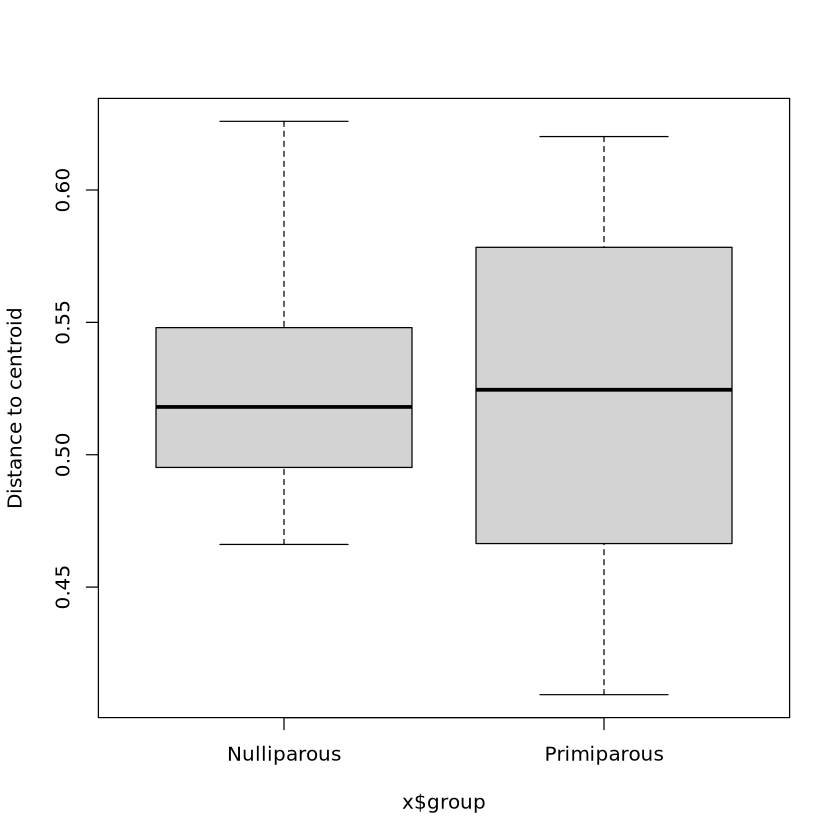

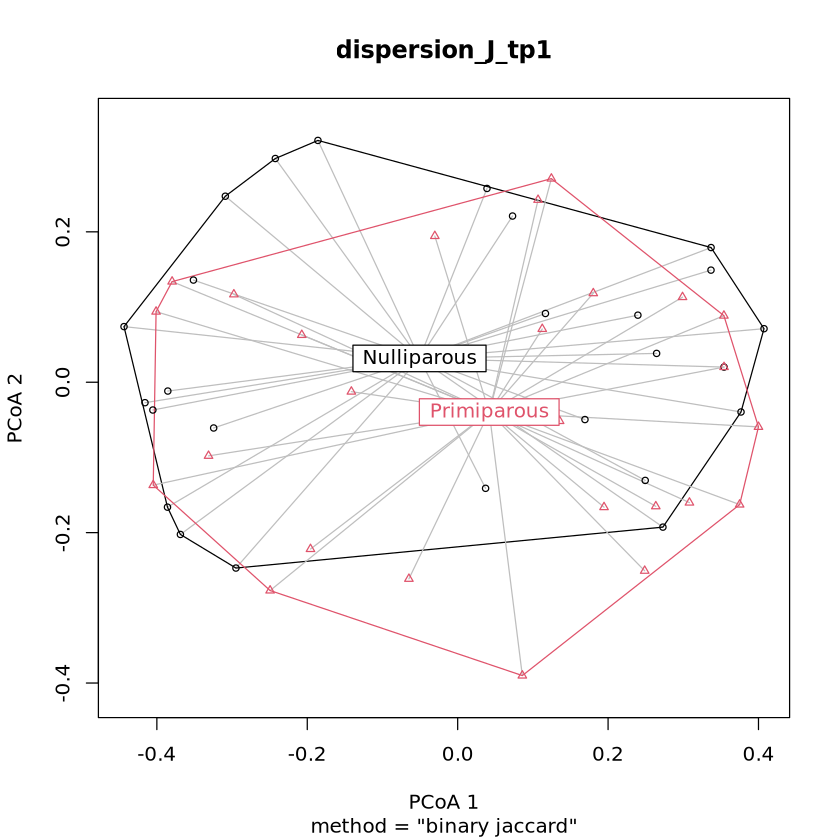

In [62]:
boxplot(dispersion_J_tp1 )
plot(dispersion_J_tp1 )

In [87]:
set.seed(123)
dispersion_tp1_At <- vegan::betadisper(dist_ait_tp1 , meta_tp1$Group)
permutest(dispersion_tp1_At)


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df Sum Sq Mean Sq      F N.Perm Pr(>F)
Groups     1   54.6  54.600 2.2161    999  0.147
Residuals 50 1231.9  24.638                     

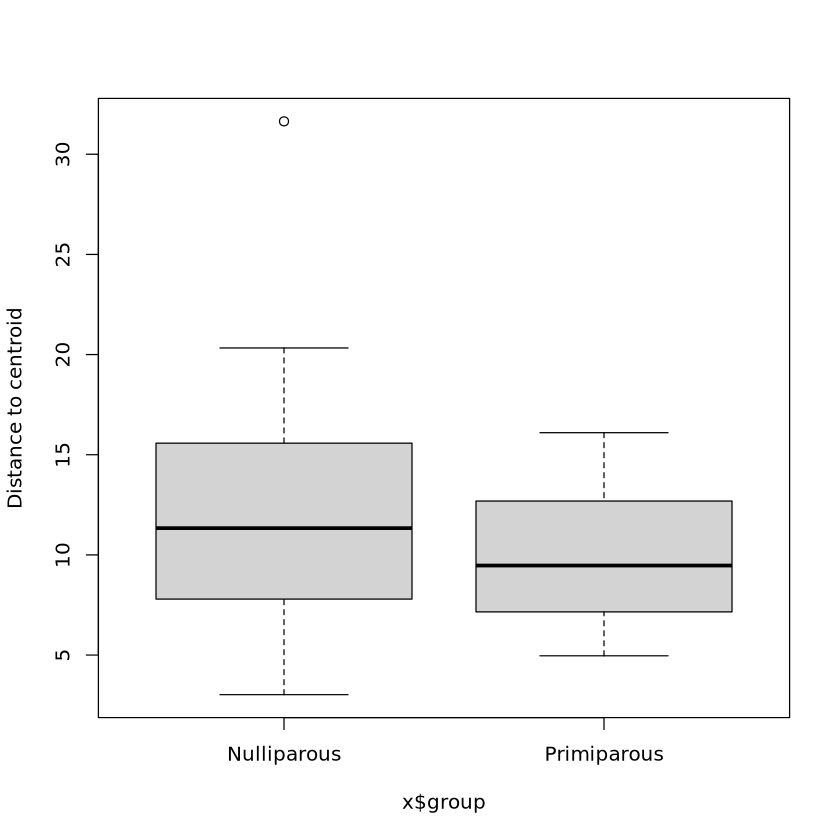

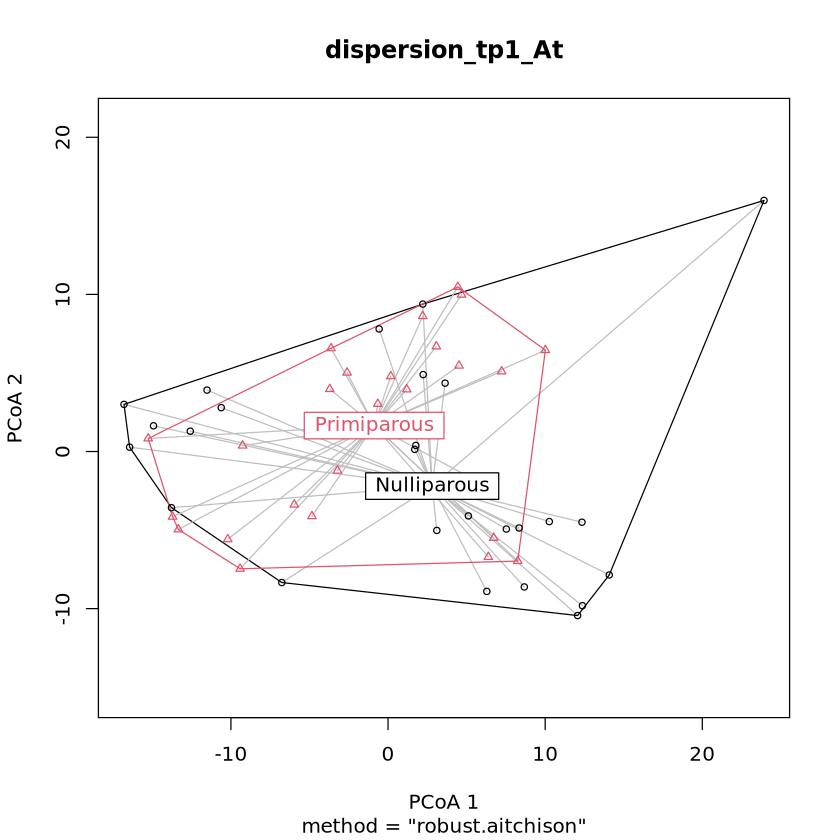

In [136]:
boxplot(dispersion_tp1_At)
plot(dispersion_tp1_At)

In [88]:
set.seed(123)
dispersion_tp1_BC <- vegan::betadisper(dist_bc_tp1, meta_tp1$Group)
permutest(dispersion_tp1_BC )


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df Sum Sq  Mean Sq      F N.Perm Pr(>F)
Groups     1 0.0379 0.037902 0.7909    999  0.355
Residuals 50 2.3963 0.047925                     

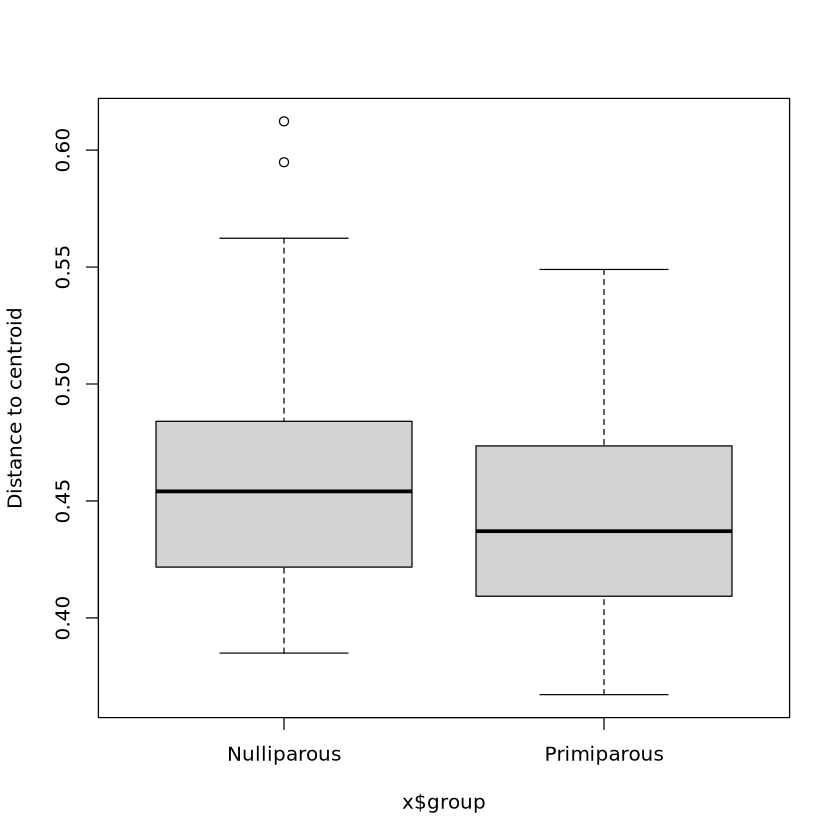

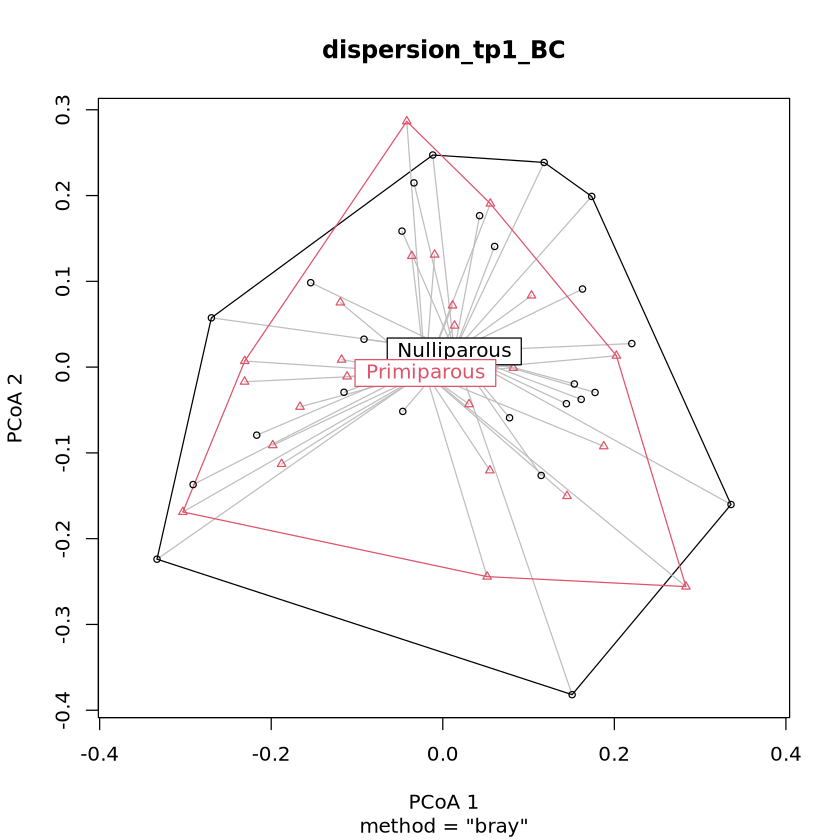

In [167]:
boxplot(dispersion_tp1_BC)
plot(dispersion_tp1_BC)

In [90]:
set.seed(123)
dispersion_J_tp2 <- vegan::betadisper(dist_jac_tp2, meta_tp2$Group)
permutest(dispersion_J_tp2)


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df   Sum Sq   Mean Sq      F N.Perm Pr(>F)  
Groups     1 0.014047 0.0140468 4.8043    999  0.037 *
Residuals 30 0.087715 0.0029238                       
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

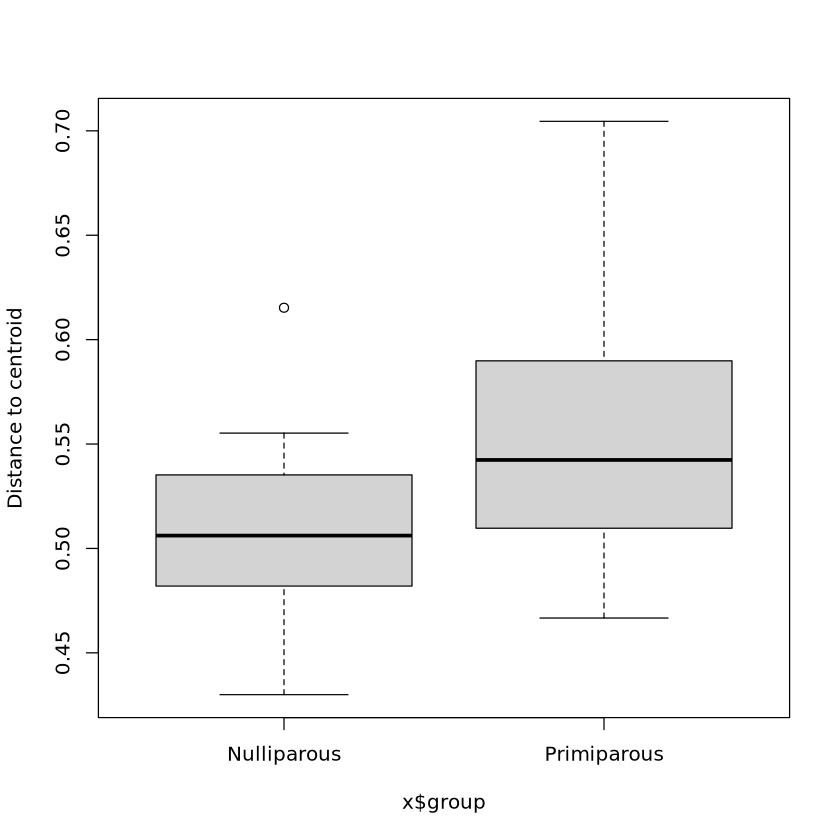

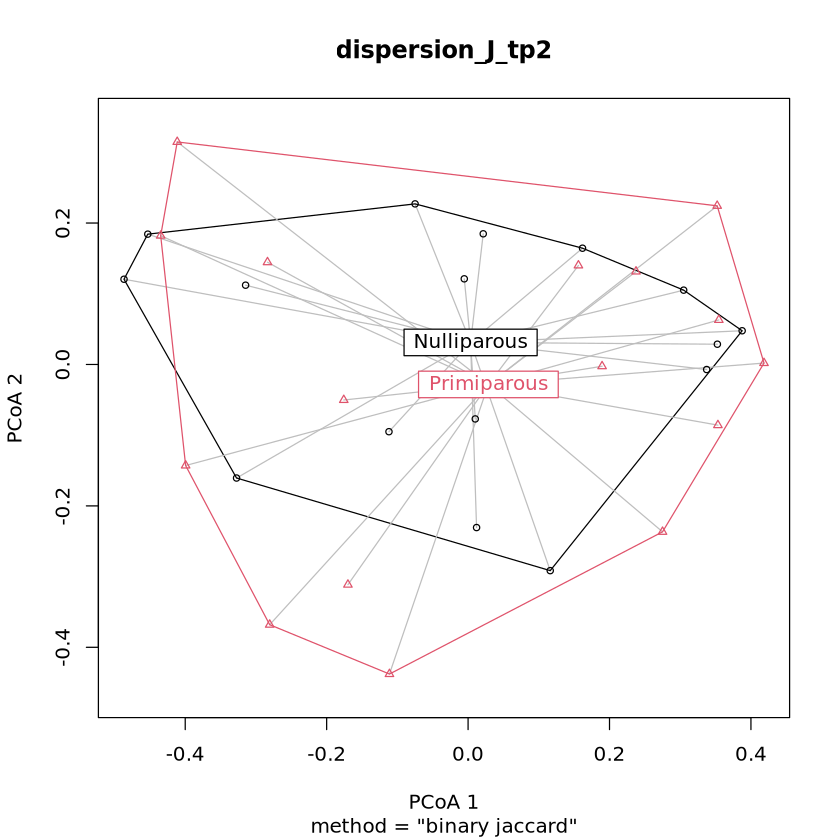

In [66]:
boxplot(dispersion_J_tp2)
plot(dispersion_J_tp2)

In [91]:
set.seed(123)
dispersion_tp2_At <- vegan::betadisper(dist_ait_tp2 , meta_tp2$Group)
permutest(dispersion_tp2_At)


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df Sum Sq Mean Sq     F N.Perm Pr(>F)
Groups     1   0.01  0.0121 8e-04    999  0.979
Residuals 30 460.40 15.3465                    

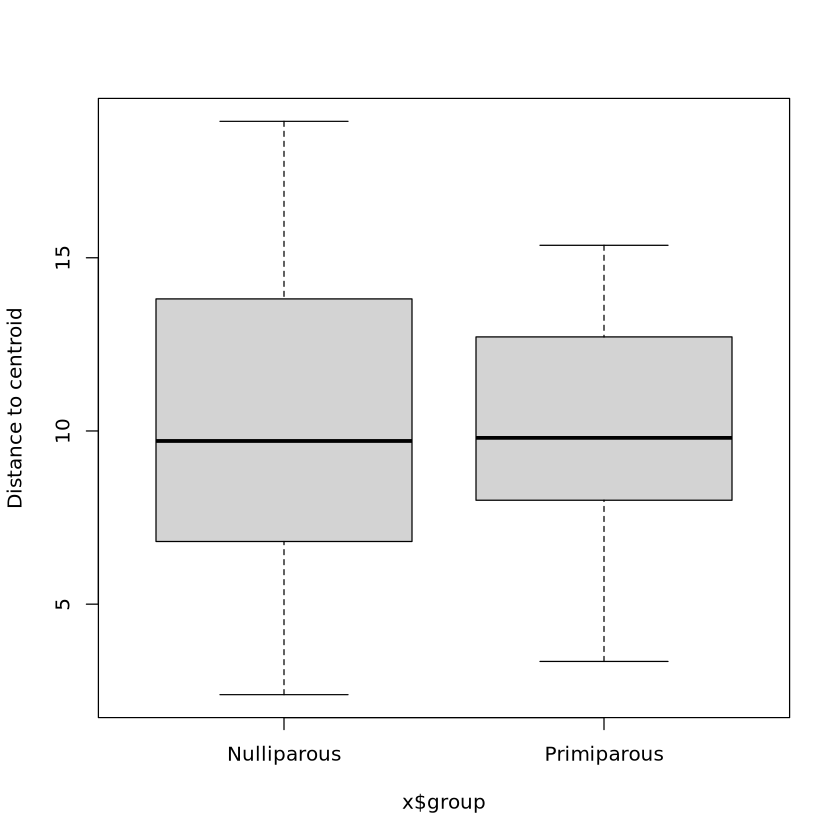

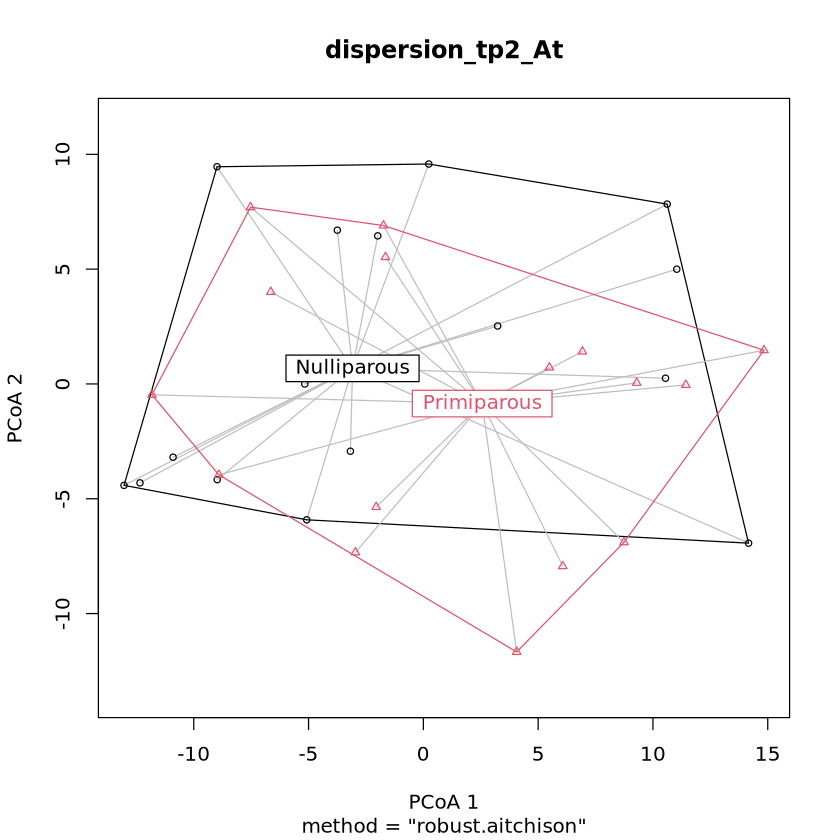

In [139]:
boxplot(dispersion_tp2_At)
plot(dispersion_tp2_At)

In [92]:
set.seed(123)
dispersion_tp2_BC <- vegan::betadisper(dist_bc_tp2, meta_tp2$Group)
permutest(dispersion_tp2_BC )


Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 999

Response: Distances
          Df  Sum Sq  Mean Sq      F N.Perm Pr(>F)
Groups     1 0.00692 0.006925 0.1132    999  0.725
Residuals 30 1.83593 0.061198                     

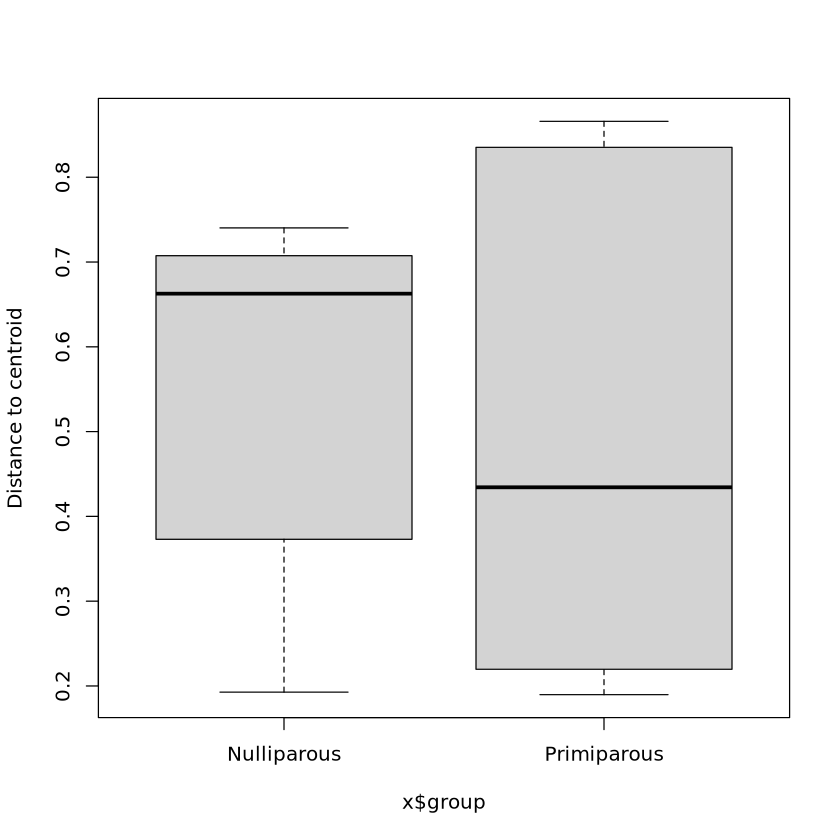

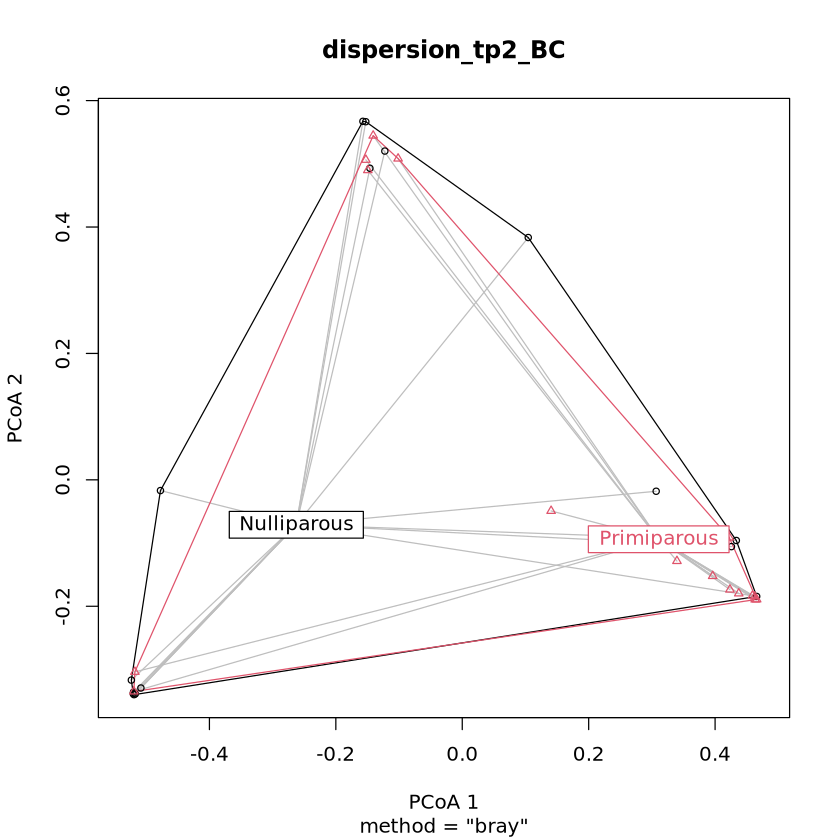

In [141]:
boxplot(dispersion_tp2_BC)
plot(dispersion_tp2_BC)

### 6.3 PERMANOVA — nulliparous vs primiparous at TP1

In [134]:
ctrl_all_tp1 <- how(plots  = Plots(strata = meta_tp1$Q1_Personnummer, type = "none"),
                within = Within(type = "free"), nperm = 999)



In [107]:
set.seed(1234)
tp1_adonis_J <- adonis2(dist_jac_tp1 ~ Q1_Personnummer + Group, data = meta_tp1,
        permutations = ctrl_all_tp1, by = "terms")
tp1_adonis_J 
r2_j_tp1 <- tp1_adonis_J["Group", "R2"]
p_j_tp1  <- tp1_adonis_J["Group", "Pr(>F)"]
r2_j_tp1
p_j_tp1 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,25,9.6838202,0.64872158,2.022422,0.01
Group,1,0.4554958,0.03051378,2.378207,0.01
Residual,25,4.7882283,0.32076464,NA,NA
Total,51,14.9275444,1.00000000,NA,NA


[1] 0.03051378

[1] 0.01

In [108]:
set.seed(1234)
tp1_adonis_AT <- adonis2(dist_ait_tp1  ~ Q1_Personnummer+ Group, data = meta_tp1,
        permutations = ctrl_all_tp1, by = "terms")
tp1_adonis_AT

r2_AT_tp1 <- tp1_adonis_AT["Group", "R2"]
p_AT_tp1  <- tp1_adonis_AT["Group", "Pr(>F)"]
r2_AT_tp1
p_AT_tp1 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,25,5063.7806,0.67779413,2.243203,0.192
Group,1,149.8026,0.02005129,1.659026,0.192
Residual,25,2257.3882,0.30215457,NA,NA
Total,51,7470.9714,1.00000000,NA,NA


[1] 0.02005129

[1] 0.192

In [103]:
table(table(meta_tp1$Q1_Personnummer))


 2 
26 

In [109]:
set.seed(1234)
tp1_adonis_BC <- adonis2(dist_bc_tp1 ~ Q1_Personnummer +Group, data = meta_tp1,
        permutations = ctrl_all_tp1, by = "terms")
tp1_adonis_BC

r2_BC_tp1 <- tp1_adonis_BC["Group", "R2"]
p_BC_tp1  <- tp1_adonis_BC["Group", "Pr(>F)"]
r2_BC_tp1
p_BC_tp1 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,25,12.214196,0.65866492,2.291816,0.006
Group,1,1.000189,0.05393637,4.691772,0.006
Residual,25,5.329484,0.28739871,NA,NA
Total,51,18.543869,1.00000000,NA,NA


[1] 0.05393637

[1] 0.006

### 6.4 PERMANOVA — nulliparous vs primiparous at TP2

In [110]:
ctrl_all_tp2 <- how(plots  = Plots(strata = meta_tp2$Q1_Personnummer, type = "none"),
                within = Within(type = "free"), nperm = 999)



In [138]:
set.seed(1234)
tp2_adonis_J <- adonis2(dist_jac_tp2 ~ Q1_Personnummer +Group, data = meta_tp2,
        permutations = ctrl_all_tp2, by = "terms")
tp2_adonis_J

r2_j_tp2 <- tp2_adonis_J["Group", "R2"]
p_j_tp2  <- tp2_adonis_J["Group", "Pr(>F)"]
r2_j_tp2
p_j_tp2 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,15,5.9220646,0.63720853,1.8535044,0.652
Group,1,0.1766341,0.01900566,0.8292514,0.652
Residual,15,3.1950636,0.34378581,NA,NA
Total,31,9.2937622,1.00000000,NA,NA


[1] 0.01900566

[1] 0.652

In [139]:
set.seed(1234)
tp2_adonis_AT <- adonis2(dist_ait_tp2  ~ Q1_Personnummer +Group, data = meta_tp2,
        permutations = ctrl_all_tp2, by = "terms")
tp2_adonis_AT

r2_AT_tp2 <- tp2_adonis_AT["Group", "R2"]
p_AT_tp2  <- tp2_adonis_AT["Group", "Pr(>F)"]
r2_AT_tp2
p_AT_tp2 


,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,15,2696.9587,0.7210809,2.926530,0.137
Group,1,121.6473,0.0325246,1.980032,0.137
Residual,15,921.5552,0.2463945,NA,NA
Total,31,3740.1611,1.0000000,NA,NA


[1] 0.0325246

[1] 0.137

In [140]:
set.seed(1234)
tp2_adonis_BC <- adonis2(dist_bc_tp2 ~ Q1_Personnummer + Group, data = meta_tp2,
        permutations = ctrl_all_tp2, by = "terms")
tp2_adonis_BC

r2_BC_tp2 <- tp2_adonis_BC["Group", "R2"]
p_BC_tp2  <- tp2_adonis_BC["Group", "Pr(>F)"]
r2_BC_tp2
p_BC_tp2 

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Q1_Personnummer,15,7.480125,0.69746651,3.064657,0.002
Group,1,0.803813,0.07494963,4.939913,0.002
Residual,15,2.440771,0.22758386,NA,NA
Total,31,10.724709,1.00000000,NA,NA


[1] 0.07494963

[1] 0.002

## 7. Compositional trajectory from TP1 to TP2
Is the pattern of compositional change the same or different between the groups?

In [192]:
filt_meta_tp1 <- meta_tp1 %>% filter(Q1_Personnummer %in% meta_tp2$Q1_Personnummer)
dim(filt_meta_tp1 )
head(filt_meta_tp1 )

[1] 32  5

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point
,<chr>,<chr>,<chr>,<chr>,<chr>
FF02014263,S194e21b,P159f9c8,FF02014263,Nulliparous,TP1
FF00653546,S1f95844,P1f95844,FF00653546,Nulliparous,TP1
FF02557868,S2b86cc0,P3cac7b0,FF02557868,Nulliparous,TP1
FB02825409,S39fe1d7,P3db7da6,FB02825409,Nulliparous,TP1
FF00657534,S7e4a963,P424fd61,FF00657534,Nulliparous,TP1
FF02014805,S5fa4a39,P4de45e7,FF02014805,Nulliparous,TP1


In [193]:
taxa_tab_tp1_delta <- tp1_taxa[,colnames(tp1_taxa) %in% rownames(filt_meta_tp1)]
head(taxa_tab_tp1_delta )

,FF00653546,FB02825409,FF02014263,FF02015432,FF00653167,FF02557868,FF02015815,FF00620268,FF02014181,FF00652411,⋯,FF06579566,FF05024757,FF05024748,FF06039831,FF05024953,FF06580399,FF04761460,FF05043003,FF05025300,FF05043036
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Actinobaculum massiliense,0.00000,0.00000,0,0.13543,0,0,0.00000,0.00424,0.00000,0.00000,⋯,0,0.00000,0.00000,0,0.00000,0.00000,0.09208,0,0.00000,0.00000
Aerococcus christensenii,0.00000,0.37028,0,0.03476,0,0,0.15046,3.31375,0.85972,0.31394,⋯,0,0.13339,0.00000,0,0.46603,0.00000,0.00000,0,0.00000,2.06919
Alloscardovia omnicolens,0.00000,0.00000,0,0.00000,0,0,0.00000,0.00000,0.00000,0.00000,⋯,0,0.00000,0.00000,0,0.00000,0.04067,0.00000,0,0.00000,0.17180
Anaerococcus hydrogenalis,0.00697,0.00000,0,0.06614,0,0,0.00000,0.00013,0.00000,0.00000,⋯,0,0.00000,0.00000,0,0.00000,0.00000,0.00000,0,0.00000,0.00000
Anaerococcus lactolyticus,0.01879,0.00000,0,0.00000,0,0,0.00281,0.00524,0.01748,0.00155,⋯,0,0.00000,0.00000,0,0.00035,0.12813,0.00000,0,0.01611,0.00000
Anaerococcus prevotii,0.00000,0.00000,0,0.00000,0,0,0.00000,0.00000,0.00000,0.00000,⋯,0,0.00000,0.11047,0,0.00000,0.00000,0.00000,0,0.00000,0.00000


In [194]:
delta_all_taxa <-
  taxa_tab_tp1_delta %>%
  rownames_to_column("Species") %>%
  full_join(
    tp2_taxa %>% rownames_to_column("Species"),
    by = "Species"
  ) %>%
  column_to_rownames("Species")

delta_all_taxa[is.na(delta_all_taxa)] <- 0
dim(delta_all_taxa)

[1] 65 64

In [195]:
head(delta_all_taxa)

,FF00653546,FB02825409,FF02014263,FF02015432,FF00653167,FF02557868,FF02015815,FF00620268,FF02014181,FF00652411,⋯,FF06743126,FF06032176,FF06039851,FF08440262,FF06033016,FF06032916,FF06743139,FF04761515,FF08440398,FF08440427
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Actinobaculum massiliense,0.00000,0.00000,0,0.13543,0,0,0.00000,0.00424,0.00000,0.00000,⋯,0,0.00000,0.00000,0,0.00000,0,0,0.00000,0.00000,0
Aerococcus christensenii,0.00000,0.37028,0,0.03476,0,0,0.15046,3.31375,0.85972,0.31394,⋯,0,0.00000,0.77247,0,1.02387,0,0,0.00606,0.00000,0
Alloscardovia omnicolens,0.00000,0.00000,0,0.00000,0,0,0.00000,0.00000,0.00000,0.00000,⋯,0,0.07117,0.00000,0,0.00000,0,0,0.00000,1.74307,0
Anaerococcus hydrogenalis,0.00697,0.00000,0,0.06614,0,0,0.00000,0.00013,0.00000,0.00000,⋯,0,0.00000,0.00000,0,0.00000,0,0,0.00000,0.00420,0
Anaerococcus lactolyticus,0.01879,0.00000,0,0.00000,0,0,0.00281,0.00524,0.01748,0.00155,⋯,0,0.00043,0.00237,0,0.00154,0,0,0.00000,0.02457,0
Anaerococcus prevotii,0.00000,0.00000,0,0.00000,0,0,0.00000,0.00000,0.00000,0.00000,⋯,0,0.00000,0.00000,0,0.00000,0,0,0.00000,0.00989,0


In [196]:
delta_all_taxa_1 <- as.data.frame(t(delta_all_taxa))
class(delta_all_taxa_1)
head(delta_all_taxa_1)

[1] "data.frame"

,Actinobaculum massiliense,Aerococcus christensenii,Alloscardovia omnicolens,Anaerococcus hydrogenalis,Anaerococcus lactolyticus,Anaerococcus prevotii,Anaerococcus sp_Marseille_P3915,Anaerococcus tetradius,Anaerococcus vaginalis,Atopobium deltae,⋯,Staphylococcus epidermidis,Streptococcus anginosus,Streptococcus SGB3665,Tissierellia bacterium_KA00581,Ureaplasma parvum,Varibaculum cambriense,Varibaculum massiliense,Veillonellaceae bacterium_DNF00626,Winkia neuii,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FF00653546,0.00000,0.00000,0,0.00697,0.01879,0,0.00623,0.00000,0.00000,0.01103,⋯,0.00000,0.00000,0,0.00000,0.0000,0.00805,0,0.02838,0,9.977000e-02
FB02825409,0.00000,0.37028,0,0.00000,0.00000,0,0.00000,0.00477,0.00000,0.00000,⋯,0.00000,0.00000,0,0.25771,0.0097,0.00000,0,0.90706,0,8.096500e-01
FF02014263,0.00000,0.00000,0,0.00000,0.00000,0,0.00000,0.00000,0.00000,0.00000,⋯,0.00000,0.00000,0,0.00000,0.0000,0.00000,0,0.00000,0,0.000000e+00
FF02015432,0.13543,0.03476,0,0.06614,0.00000,0,0.07625,0.51893,0.05359,0.05284,⋯,0.01606,1.03939,0,0.00000,0.0000,0.02508,0,0.35671,0,2.761090e+00
FF00653167,0.00000,0.00000,0,0.00000,0.00000,0,0.00000,0.00000,0.00000,0.00000,⋯,0.00000,0.00000,0,0.00000,0.0000,0.00000,0,0.00000,0,1.421085e-14
FF02557868,0.00000,0.00000,0,0.00000,0.00000,0,0.00000,0.00000,0.00000,0.00000,⋯,0.00000,0.00000,0,0.00000,0.0000,0.00000,0,0.00000,0,0.000000e+00


In [197]:
delta_meta <- bind_rows(filt_meta_tp1, meta_tp2)
head(delta_meta )

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point
,<chr>,<chr>,<chr>,<chr>,<chr>
FF02014263,S194e21b,P159f9c8,FF02014263,Nulliparous,TP1
FF00653546,S1f95844,P1f95844,FF00653546,Nulliparous,TP1
FF02557868,S2b86cc0,P3cac7b0,FF02557868,Nulliparous,TP1
FB02825409,S39fe1d7,P3db7da6,FB02825409,Nulliparous,TP1
FF00657534,S7e4a963,P424fd61,FF00657534,Nulliparous,TP1
FF02014805,S5fa4a39,P4de45e7,FF02014805,Nulliparous,TP1


In [198]:
delta_all_taxa_2 <- delta_all_taxa_1[rownames(delta_meta), ]
head(delta_all_taxa_2)

,Actinobaculum massiliense,Aerococcus christensenii,Alloscardovia omnicolens,Anaerococcus hydrogenalis,Anaerococcus lactolyticus,Anaerococcus prevotii,Anaerococcus sp_Marseille_P3915,Anaerococcus tetradius,Anaerococcus vaginalis,Atopobium deltae,⋯,Staphylococcus epidermidis,Streptococcus anginosus,Streptococcus SGB3665,Tissierellia bacterium_KA00581,Ureaplasma parvum,Varibaculum cambriense,Varibaculum massiliense,Veillonellaceae bacterium_DNF00626,Winkia neuii,Other_taxa
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FF02014263,0,0.00000,0.00000,0.00000,0.00000,0,0.00000,0.00000,0,0.00000,⋯,0,0,0,0.00000,0.0000,0.00000,0,0.00000,0.00000,0.00000
FF00653546,0,0.00000,0.00000,0.00697,0.01879,0,0.00623,0.00000,0,0.01103,⋯,0,0,0,0.00000,0.0000,0.00805,0,0.02838,0.00000,0.09977
FF02557868,0,0.00000,0.00000,0.00000,0.00000,0,0.00000,0.00000,0,0.00000,⋯,0,0,0,0.00000,0.0000,0.00000,0,0.00000,0.00000,0.00000
FB02825409,0,0.37028,0.00000,0.00000,0.00000,0,0.00000,0.00477,0,0.00000,⋯,0,0,0,0.25771,0.0097,0.00000,0,0.90706,0.00000,0.80965
FF00657534,0,0.78909,0.00207,0.00000,0.00299,0,0.00000,0.00000,0,0.00631,⋯,0,0,0,0.00000,0.0000,0.00996,0,0.01321,0.00463,0.40690
FF02014805,0,0.00000,0.00000,0.00000,0.00000,0,0.00000,0.00000,0,0.00000,⋯,0,0,0,0.00000,0.1139,0.00000,0,0.00000,0.00000,0.00170


In [199]:
all(rownames(delta_all_taxa_2) == rownames(delta_meta))

[1] TRUE

In [200]:
delta_dist_bc <- vegdist(delta_all_taxa_2, method = "bray")
delta_dist_jac <- vegdist(delta_all_taxa_2, method = "jaccard", binary = TRUE)
delta_dist_ait <- vegdist(delta_all_taxa_2, method = "robust.aitchison")

In [201]:
ctrl_all <- how(plots  = Plots(strata = delta_meta$Q1_Personnummer, type = "none"),
                within = Within(type = "free"), nperm = 999)


In [202]:
set.seed(1234)
adonis_within_bc <- adonis2(delta_dist_bc ~ Group * Time_point, data = delta_meta,
        permutations = ctrl_all, by = "terms")
adonis_within_bc 

r2_bc <- adonis_within_bc["Group:Time_point", "R2"]
p_bc  <- adonis_within_bc["Group:Time_point", "Pr(>F)"]
r2_bc 
p_bc

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Group,1,1.25723940,0.05799471,3.7197142,0.001
Time_point,1,0.08946964,0.00412711,0.2647081,0.690
Group:Time_point,1,0.05219819,0.00240783,0.1544355,0.847
Residual,60,20.27961283,0.93547035,NA,NA
Total,63,21.67852006,1.00000000,NA,NA


[1] 0.00240783

[1] 0.847

In [203]:
all(labels(delta_dist_bc) == rownames(delta_meta))
table(delta_meta$Q1_Personnummer, delta_meta$Group, delta_meta$Time_point)

[1] TRUE

, ,  = TP1

          
           Nulliparous Primiparous
  P159f9c8           1           1
  P1f95844           1           1
  P3cac7b0           1           1
  P3db7da6           1           1
  P424fd61           1           1
  P4de45e7           1           1
  P5b98b6c           1           1
  P62ea0b2           1           1
  P719b21e           1           1
  P7ece52e           1           1
  P97574f9           1           1
  P9cdfd5a           1           1
  Pbe289c8           1           1
  Pc77a35c           1           1
  Pca94a0f           1           1
  Pdab1897           1           1

, ,  = TP2

          
           Nulliparous Primiparous
  P159f9c8           1           1
  P1f95844           1           1
  P3cac7b0           1           1
  P3db7da6           1           1
  P424fd61           1           1
  P4de45e7           1           1
  P5b98b6c           1           1
  P62ea0b2           1           1
  P719b21e           1           1
  P7ece5

In [204]:
set.seed(1234)
adonis_within_jac <- adonis2(delta_dist_jac ~ Group * Time_point, data = delta_meta,
        permutations = ctrl_all, by = "terms")
adonis_within_jac 
r2_J <- adonis_within_jac["Group:Time_point", "R2"]
p_J  <- adonis_within_jac["Group:Time_point", "Pr(>F)"]

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Group,1,0.3545909,0.01920509,1.209476,0.034
Time_point,1,0.3242251,0.01756043,1.105902,0.052
Group:Time_point,1,0.1939394,0.01050400,0.661509,0.427
Residual,60,17.5906308,0.95273048,NA,NA
Total,63,18.4633861,1.00000000,NA,NA


In [205]:
set.seed(1234)
adonis_within_At <- adonis2(delta_dist_ait ~ Group * Time_point, data = delta_meta,
        permutations = ctrl_all, by = "terms")
adonis_within_At
r2_AT <- adonis_within_At["Group:Time_point", "R2"]
p_AT  <- adonis_within_At["Group:Time_point", "Pr(>F)"]

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Group,1,157.939405,0.0182355504,1.11663550,0.161
Time_point,1,10.289161,0.0011879779,0.07274462,0.944
Group:Time_point,1,6.309635,0.0007285052,0.04460928,0.978
Residual,60,8486.533274,0.9798479666,NA,NA
Total,63,8661.071476,1.0000000000,NA,NA


## 8. Differential Abundance

In [55]:
read_depth <- read.csv(file.path(base_path, "Consecutive_preg/Anusha_redo_folder_260728/vagina/data/240625_superset_allswemami.csv"))
head(read_depth)

,project_id,sequencer_id,flowcell_id,lane_id,adapter_id,sample_id,extraction_plate_id,dna_concentration,library_concentration,duplication,fragment_size,reads_post_qc,host_proportion,reads_post_hr,not_sequenced
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,010_SweMaMi,R1100600190018,E100033372,1,13,010_extraction10_pos_ext,Extraction10,4.0385,25.7120,0.0226733,422,3835,88.45,443,
2,010_SweMaMi,R1100600190018,E100033372,1,115,010_extraction10_pos_seq,Extraction10,30.0000,7.4192,0.0242305,425,59430144,0.63,59053867,
3,010_SweMaMi,R1100600190018,E100033371,1,125,010_extraction11_pos_ext,Extraction11,-1.0000,7.2408,0.0409590,477,78186865,0.65,77680170,
4,010_SweMaMi,R1100600190018,E100033371,1,115,010_extraction11_pos_seq,Extraction11,30.0000,9.6370,0.0349191,490,54260749,0.63,53918821,
5,010_SweMaMi,R1100600190018,E100033353,1,84,010_extraction12_pos_ext,Extraction12,2.9796,38.5400,0.0192193,484,69340052,0.53,68972932,
6,010_SweMaMi,R1100600190018,E100033353,1,39,010_extraction12_pos_seq,Extraction12,30.0000,6.5941,0.0179227,482,48073669,0.55,47810555,


In [56]:
test_string <- "not_sequenced_010SweMaMi_extra42_FF00652060"
sub(".*(FF\\d+)$", "\\1", test_string)
# should return "FF00652060"

[1] "FF00652060"

In [57]:
read_depth_1 <- read_depth %>%
  mutate(
    Sample_ID    = sub(".*__(\\d+)__.*", "\\1", read_depth$sample_id),
    Extra_Code   = sub(".*(FF\\d+)$", "\\1", read_depth$sample_id)
  )
head(read_depth_1)

,project_id,sequencer_id,flowcell_id,lane_id,adapter_id,sample_id,extraction_plate_id,dna_concentration,library_concentration,duplication,fragment_size,reads_post_qc,host_proportion,reads_post_hr,not_sequenced,Sample_ID,Extra_Code
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
1,010_SweMaMi,R1100600190018,E100033372,1,13,010_extraction10_pos_ext,Extraction10,4.0385,25.7120,0.0226733,422,3835,88.45,443,,010_extraction10_pos_ext,010_extraction10_pos_ext
2,010_SweMaMi,R1100600190018,E100033372,1,115,010_extraction10_pos_seq,Extraction10,30.0000,7.4192,0.0242305,425,59430144,0.63,59053867,,010_extraction10_pos_seq,010_extraction10_pos_seq
3,010_SweMaMi,R1100600190018,E100033371,1,125,010_extraction11_pos_ext,Extraction11,-1.0000,7.2408,0.0409590,477,78186865,0.65,77680170,,010_extraction11_pos_ext,010_extraction11_pos_ext
4,010_SweMaMi,R1100600190018,E100033371,1,115,010_extraction11_pos_seq,Extraction11,30.0000,9.6370,0.0349191,490,54260749,0.63,53918821,,010_extraction11_pos_seq,010_extraction11_pos_seq
5,010_SweMaMi,R1100600190018,E100033353,1,84,010_extraction12_pos_ext,Extraction12,2.9796,38.5400,0.0192193,484,69340052,0.53,68972932,,010_extraction12_pos_ext,010_extraction12_pos_ext
6,010_SweMaMi,R1100600190018,E100033353,1,39,010_extraction12_pos_seq,Extraction12,30.0000,6.5941,0.0179227,482,48073669,0.55,47810555,,010_extraction12_pos_seq,010_extraction12_pos_seq


In [58]:
read_depth_2 <- read_depth_1 %>% filter(Sample_ID %in% rownames(meta_tp1)) %>% 
                                        select(c(Sample_ID, reads_post_hr))

head(read_depth_2)


,Sample_ID,reads_post_hr
,<chr>,<dbl>
1,FB02825409,26357647
2,FB02846091,5214620
3,FF00530208,6225655
4,FF00530247,40370949
5,FF00619356,2600611
6,FF00620268,10991144


In [59]:
read_depth_22 <- read_depth_1 %>% filter(Sample_ID %in% rownames(meta_tp2)) %>% 
                                        select(c(Sample_ID, reads_post_hr))

head(read_depth_22)


,Sample_ID,reads_post_hr
,<chr>,<dbl>
1,FB02825218,1389891
2,FF00531062,24200302
3,FF00531275,8954833
4,FF00531801,8912621
5,FF00619973,976276
6,FF00657220,15801738


In [60]:
read_depth_3 <- read_depth_2 %>% rename(read_depth = reads_post_hr)
head(read_depth_3)
dim(read_depth_3 )
# There are duplicates, since I chose the samples with the highest reads. For duplicates, go for the highest reads.

,Sample_ID,read_depth
,<chr>,<dbl>
1,FB02825409,26357647
2,FB02846091,5214620
3,FF00530208,6225655
4,FF00530247,40370949
5,FF00619356,2600611
6,FF00620268,10991144


[1] 60  2

In [61]:
read_depth_33 <- read_depth_22 %>% rename(read_depth = reads_post_hr)
head(read_depth_33)
dim(read_depth_33 )

,Sample_ID,read_depth
,<chr>,<dbl>
1,FB02825218,1389891
2,FF00531062,24200302
3,FF00531275,8954833
4,FF00531801,8912621
5,FF00619973,976276
6,FF00657220,15801738


[1] 33  2

In [62]:
duplicated(read_depth_33$Sample_ID)

[1] FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE  TRUE FALSE FALSE
[13] FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE
[25] FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE

In [63]:
read_depth_4 <- read_depth_3 %>%
  group_by(Sample_ID) %>%
  slice_max(order_by = read_depth, n = 1, with_ties = FALSE) %>%
  ungroup()
dim(read_depth_4)
head(read_depth_4)

[1] 52  2

Sample_ID,read_depth
<chr>,<dbl>
FB02825409,26357647
FB02846091,5214620
FF00530208,6225655
FF00530247,40370949
FF00619356,2600611
FF00620268,10991144


In [64]:
read_depth_44 <- read_depth_33 %>%
  group_by(Sample_ID) %>%
  slice_max(order_by = read_depth, n = 1, with_ties = FALSE) %>%
  ungroup()
dim(read_depth_44 )
head(read_depth_44 )

[1] 32  2

Sample_ID,read_depth
<chr>,<dbl>
FB02825218,1389891
FF00531062,24200302
FF00531275,8954833
FF00531801,8912621
FF00619973,976276
FF00657220,15801738


In [44]:
meta_tp1_1 <- meta_tp1 %>%
  rownames_to_column(var = "Row.names")
head(meta_tp1_1)

,Row.names,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,FF02014263,S194e21b,P159f9c8,FF02014263,Nulliparous,TP1
2,FF00653507,S1f862a6,P1f862a6,FF00653507,Nulliparous,TP1
3,FF00653546,S1f95844,P1f95844,FF00653546,Nulliparous,TP1
4,FF02557868,S2b86cc0,P3cac7b0,FF02557868,Nulliparous,TP1
5,FB02825409,S39fe1d7,P3db7da6,FB02825409,Nulliparous,TP1
6,FF00657534,S7e4a963,P424fd61,FF00657534,Nulliparous,TP1


In [50]:
update_meta_tp1 <- full_join(
  meta_tp1_1,
  read_depth_4,
  by = c("Row.names" = "Sample_ID")
)
head(update_meta_tp1)

,Row.names,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point,read_depth
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,FF02014263,S194e21b,P159f9c8,FF02014263,Nulliparous,TP1,9039633
2,FF00653507,S1f862a6,P1f862a6,FF00653507,Nulliparous,TP1,28008812
3,FF00653546,S1f95844,P1f95844,FF00653546,Nulliparous,TP1,5754625
4,FF02557868,S2b86cc0,P3cac7b0,FF02557868,Nulliparous,TP1,6051859
5,FB02825409,S39fe1d7,P3db7da6,FB02825409,Nulliparous,TP1,26357647
6,FF00657534,S7e4a963,P424fd61,FF00657534,Nulliparous,TP1,6025272


In [65]:
meta_tp2_1 <- meta_tp2 %>%
  rownames_to_column(var = "Row.names")
head(meta_tp2_1 )

,Row.names,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,FF00531801,S194e21b,P159f9c8,FF00531801,Nulliparous,TP2
2,FF02014735,S1f95844,P1f95844,FF02014735,Nulliparous,TP2
3,FF03816858,S2b86cc0,P3cac7b0,FF03816858,Nulliparous,TP2
4,FF02015861,S39fe1d7,P3db7da6,FF02015861,Nulliparous,TP2
5,FF00657251,S7e4a963,P424fd61,FF00657251,Nulliparous,TP2
6,FF02015423,S5fa4a39,P4de45e7,FF02015423,Nulliparous,TP2


In [66]:
update_meta_tp2 <- full_join(
  meta_tp2_1,
  read_depth_44,
  by = c("Row.names" = "Sample_ID")
)
head(update_meta_tp2)

,Row.names,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point,read_depth
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,FF00531801,S194e21b,P159f9c8,FF00531801,Nulliparous,TP2,8912621
2,FF02014735,S1f95844,P1f95844,FF02014735,Nulliparous,TP2,5097523
3,FF03816858,S2b86cc0,P3cac7b0,FF03816858,Nulliparous,TP2,5435147
4,FF02015861,S39fe1d7,P3db7da6,FF02015861,Nulliparous,TP2,23172795
5,FF00657251,S7e4a963,P424fd61,FF00657251,Nulliparous,TP2,44268312
6,FF02015423,S5fa4a39,P4de45e7,FF02015423,Nulliparous,TP2,1134547


In [53]:
update_meta_tp1 <- update_meta_tp1 %>%
  column_to_rownames(var = "Row.names")
head(update_meta_tp1)

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point,read_depth
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
FF02014263,S194e21b,P159f9c8,FF02014263,Nulliparous,TP1,9039633
FF00653507,S1f862a6,P1f862a6,FF00653507,Nulliparous,TP1,28008812
FF00653546,S1f95844,P1f95844,FF00653546,Nulliparous,TP1,5754625
FF02557868,S2b86cc0,P3cac7b0,FF02557868,Nulliparous,TP1,6051859
FB02825409,S39fe1d7,P3db7da6,FB02825409,Nulliparous,TP1,26357647
FF00657534,S7e4a963,P424fd61,FF00657534,Nulliparous,TP1,6025272


In [67]:
update_meta_tp2 <- update_meta_tp2 %>%
  column_to_rownames(var = "Row.names")
head(update_meta_tp2)

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point,read_depth
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
FF00531801,S194e21b,P159f9c8,FF00531801,Nulliparous,TP2,8912621
FF02014735,S1f95844,P1f95844,FF02014735,Nulliparous,TP2,5097523
FF03816858,S2b86cc0,P3cac7b0,FF03816858,Nulliparous,TP2,5435147
FF02015861,S39fe1d7,P3db7da6,FF02015861,Nulliparous,TP2,23172795
FF00657251,S7e4a963,P424fd61,FF00657251,Nulliparous,TP2,44268312
FF02015423,S5fa4a39,P4de45e7,FF02015423,Nulliparous,TP2,1134547


In [68]:
all(rownames(ordered_taxa_tp1) == rownames(update_meta_tp1 ))
all(rownames(ordered_taxa_tp2) == rownames(update_meta_tp2 ))

[1] TRUE

[1] TRUE

In [69]:
update_meta_tp1$Group <- factor(update_meta_tp1$Group, levels = c("Nulliparous", "Primiparous"))
update_meta_tp2$Group <- factor(update_meta_tp2$Group, levels = c("Nulliparous", "Primiparous"))

In [70]:
DA_TP1 <- file.path(base_path, "Consecutive_preg/Github_version/Vagina/data/DA_TP1")
DA_TP2 <- file.path(base_path, "Consecutive_preg/Github_version/Vagina/data/DA_TP2")

### Model 1

In [71]:
tp1_DA <- maaslin3(
  input_data     = ordered_taxa_tp1,
  input_metadata = update_meta_tp1,
  output         = "DA_TP1",
  
  # Group is your primary variable; read_depth is a required technical covariate
  fixed_effects  = c("Group", "read_depth"), 
  # Q1_Personnummer links the paired samples for each woman
  random_effects = c("Q1_Personnummer"),   
  # Baseline for comparison
  reference      = "Group,Nulliparous",
  # Handling the paired design with only 2 samples per person
  small_random_effects = TRUE,
  # Recommended defaults 
  normalization  = "TSS",
  transform      = "LOG",
  median_comparison_abundance = TRUE
)

2026-10-19 14:47:22.687561 INFO::Writing function arguments to log file
2026-10-19 14:47:22.705079 INFO::Verifying options selected are valid
2026-10-19 14:47:22.706316 INFO::Determining format of input files
2026-10-19 14:47:22.706843 INFO::Input format is data samples as rows and metadata samples as rows
2026-10-19 14:47:22.708681 INFO::Formula for random effects: expr ~ (1 | Q1_Personnummer)
2026-10-19 14:47:22.709392 INFO::Formula for fixed effects: expr ~  Group + read_depth
2026-10-19 14:47:22.710409 INFO::Running selected normalization method: TSS
2026-10-19 14:47:22.712891 INFO::Creating output feature tables folder
2026-10-19 14:47:22.713634 INFO::Writing normalized data to file DA_TP1/features/data_norm.tsv
2026-10-19 14:47:22.716134 INFO::Filter data based on min abundance, min prevalence, and max prevalence
2026-10-19 14:47:22.716643 INFO::Total samples in data: 52
2026-10-19 14:47:22.717079 INFO::Min samples required with min abundance for a feature not to be filtered: 0.0

Warning message:
“the ‘findbars’ function has moved to the reformulas package. Please update your imports, or ask an upstream package maintainter to do so.
This warning is displayed once per session.”


2026-10-19 14:47:26.777324 INFO::Fitting model to feature number 2, Aerococcus christensenii
2026-10-19 14:47:26.813832 INFO::Fitting model to feature number 3, Alloscardovia omnicolens


Feature Alloscardovia omnicolens : simpleWarning in as_lmerModLT(model, devfun): Model may not have converged with 1 eigenvalue close to zero: 1.2e-11




2026-10-19 14:47:26.9283 WARNING::Fitting problem for feature 3 a warning was issued
2026-10-19 14:47:26.945751 INFO::Fitting model to feature number 4, Anaerococcus hydrogenalis
2026-10-19 14:47:26.962846 WARNING::Fitting problem for feature 4 returning NA
2026-10-19 14:47:26.964984 INFO::Fitting model to feature number 5, Anaerococcus lactolyticus


boundary (singular) fit: see help('isSingular')



... (95 outputs left out)

Feature Tissierellia bacterium_KA00581 : simpleWarning in as_lmerModLT(model, devfun): Model may not have converged with 1 eigenvalue close to zero: 7.7e-11




2026-10-19 14:47:55.133987 WARNING::Fitting problem for feature 59 a warning was issued
2026-10-19 14:47:55.14372 INFO::Fitting model to feature number 60, Ureaplasma parvum
2026-10-19 14:47:55.184697 INFO::Fitting model to feature number 61, Varibaculum cambriense
2026-10-19 14:47:55.198858 WARNING::Fitting problem for feature 61 returning NA
2026-10-19 14:47:55.200796 INFO::Fitting model to feature number 62, Varibaculum massiliense
2026-10-19 14:47:55.214783 WARNING::Fitting problem for feature 62 returning NA
2026-10-19 14:47:55.216644 INFO::Fitting model to feature number 63, Veillonellaceae bacterium_DNF00626
2026-10-19 14:47:55.248237 INFO::Fitting model to feature number 64, Winkia neuii
2026-10-19 14:47:55.262753 WARNING::Fitting problem for feature 64 returning NA
2026-10-19 14:47:55.264761 INFO::Fitting model to feature number 65, Other_taxa


boundary (singular) fit: see help('isSingular')



2026-10-19 14:47:55.321195 INFO::Creating fits folder
2026-10-19 14:47:55.322114 INFO::Writing residuals to file DA_TP1/fits/residuals_linear.rds
2026-10-19 14:47:55.323422 INFO::Writing fitted values to file DA_TP1/fits/fitted_linear.rds
2026-10-19 14:47:55.324617 INFO::Writing extracted random effects to file DA_TP1/fits/ranef_linear.rds
2026-10-19 14:47:55.325617 INFO::Writing residuals to file DA_TP1/fits/residuals_logistic.rds
2026-10-19 14:47:55.329062 INFO::Writing fitted values to file DA_TP1/fits/fitted_logistic.rds
2026-10-19 14:47:55.330777 INFO::Writing extracted random effects to file DA_TP1/fits/ranef_logistic.rds
2026-10-19 14:47:55.332773 INFO::Writing all the results to file (ordered 
            by increasing individual q-values): DA_TP1/all_results.tsv
2026-10-19 14:47:55.335206 INFO::Writing the significant results without errors (those which have joint q-values less than or equal to the threshold of 0.100000 ) to file (ordered by increasing individual q-values): DA

### Model 1 interpretation

In [26]:
DA_output_tp1 <- read.table(file.path(base_path, "Consecutive_preg/Anusha_redo_folder_260728/vagina/code/DA_TP1/all_results.tsv"), sep = "\t", header = TRUE)
head(DA_output_tp1)

,feature,metadata,value,name,coef,null_hypothesis,stderr,pval_individual,qval_individual,pval_joint,qval_joint,error,model,N,N_not_zero
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<int>,<int>
1,Gardnerella vaginalis,read_depth,read_depth,read_depth,1.884437,-1.1870263,0.5531704,0.001305946,0.2559654,0.002610186,0.3393242,NA,abundance,52,44
2,Fannyhessea vaginae,read_depth,read_depth,read_depth,2.191319,-1.1870263,0.8210469,0.004731664,0.2894948,0.009440939,0.3826057,NA,abundance,52,26
3,Gardnerella vaginalis,Group,Primiparous,GroupPrimiparous,1.899995,-0.5983528,0.6726475,0.007103715,0.2894948,0.014156968,0.3826057,NA,abundance,52,44
4,Prevotella colorans,read_depth,read_depth,read_depth,1.873512,-1.1870263,0.5676725,0.004525657,0.2894948,0.009030832,0.3826057,NA,abundance,52,15
5,Prevotella timonensis,read_depth,read_depth,read_depth,1.350078,-1.1870263,0.5434049,0.007385072,0.2894948,0.014715605,0.3826057,NA,abundance,52,27
6,Lactobacillus gasseri,Group,Primiparous,GroupPrimiparous,6.765426,-0.5983528,1.1754479,0.009880431,0.2938635,0.019663239,0.3877733,NA,abundance,52,12


In [27]:
sp <- c("Gardnerella vaginalis", "Lactobacillus gasseri","Lactobacillus crispatus", "Lactobacillus iners")

In [28]:
filt_ouput <- DA_output_tp1 %>%
  filter(metadata == "Group") %>%
  filter(feature %in% sp)
filt_ouput

feature,metadata,value,name,coef,null_hypothesis,stderr,pval_individual,qval_individual,pval_joint,qval_joint,error,model,N,N_not_zero
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<int>,<int>
Gardnerella vaginalis,Group,Primiparous,GroupPrimiparous,1.89999518,-0.5983528,0.6726475,0.007103715,0.2894948,0.01415697,0.3826057,NA,abundance,52,44
Lactobacillus gasseri,Group,Primiparous,GroupPrimiparous,6.76542595,-0.5983528,1.1754479,0.009880431,0.2938635,0.01966324,0.3877733,NA,abundance,52,12
Lactobacillus crispatus,Group,Primiparous,GroupPrimiparous,-5.11956541,-0.5983528,1.6882013,0.016464296,0.3176392,0.03265752,0.4172609,NA,abundance,52,42
Lactobacillus iners,Group,Primiparous,GroupPrimiparous,-1.25848611,0.0000000,0.6577041,0.055690032,0.7796604,0.10827868,0.9942428,NA,prevalence,52,40
Lactobacillus iners,Group,Primiparous,GroupPrimiparous,0.49736219,-0.5983528,1.9790783,0.581526695,0.9993415,0.10827868,0.9942428,NA,abundance,52,40
Gardnerella vaginalis,Group,Primiparous,GroupPrimiparous,0.69769862,0.0000000,0.6579530,0.288958996,0.9993415,0.01415697,0.3826057,NA,prevalence,52,44
Lactobacillus crispatus,Group,Primiparous,GroupPrimiparous,-0.33178975,0.0000000,0.5763952,0.564866038,0.9993415,0.03265752,0.4172609,NA,prevalence,52,42
Lactobacillus gasseri,Group,Primiparous,GroupPrimiparous,0.04853427,0.0000000,0.6459439,0.940105726,0.9993415,0.01966324,0.3877733,NA,prevalence,52,12


### Model 2

In [421]:
tp2_DA <- maaslin3(
  input_data     = ordered_taxa_tp2,
  input_metadata = update_meta_tp2,
  output         = "DA_TP2",
  
  # Group is your primary variable; read_depth is a required technical covariate
  fixed_effects  = c("Group", "read_depth"), 
  # Q1_Personnummer links the paired samples for each woman
  random_effects = c("Q1_Personnummer"),   
  # Baseline for comparison
  reference      = "Group,Nulliparous",
  # Handling the paired design with only 2 samples per person
  small_random_effects = TRUE,
  # Recommended defaults 
  normalization  = "TSS",
  transform      = "LOG",
  median_comparison_abundance = TRUE
)

2026-08-11 15:38:43.561061 INFO::Writing function arguments to log file
2026-08-11 15:38:43.567571 INFO::Verifying options selected are valid
2026-08-11 15:38:43.568066 INFO::Determining format of input files
2026-08-11 15:38:43.568513 INFO::Input format is data samples as rows and metadata samples as rows
2026-08-11 15:38:43.569897 INFO::Formula for random effects: expr ~ (1 | Q1_Personnummer)
2026-08-11 15:38:43.570414 INFO::Formula for fixed effects: expr ~  Group + read_depth
2026-08-11 15:38:43.570988 INFO::Running selected normalization method: TSS
2026-08-11 15:38:43.572803 INFO::Writing normalized data to file DA_TP2/features/data_norm.tsv
2026-08-11 15:38:43.578381 INFO::Filter data based on min abundance, min prevalence, and max prevalence
2026-08-11 15:38:43.578866 INFO::Total samples in data: 32
2026-08-11 15:38:43.579298 INFO::Min samples required with min abundance for a feature not to be filtered: 0.000000
2026-08-11 15:38:43.579694 INFO::Max samples allowed with min abu

Feature Alloscardovia omnicolens : simpleWarning in (function (fn, par, lower = rep.int(-Inf, n), upper = rep.int(Inf, : failure to converge in 100000 evaluations




2026-08-11 15:38:47.411121 WARNING::Fitting problem for feature 2 a warning was issued


Feature Alloscardovia omnicolens : simpleWarning in optwrap(optimizer, devfun, getStart(start, rho$pp), lower = rho$lower, : convergence code 4 from Nelder_Mead: failure to converge in 100000 evaluations




2026-08-11 15:38:47.415206 WARNING::Fitting problem for feature 2 a warning was issued


Feature Alloscardovia omnicolens : simpleWarning in as_lmerModLT(model, devfun): Model may not have converged with 1 eigenvalue close to zero: 1.5e-11




... (111 outputs left out)

Feature Varibaculum massiliense : simpleWarning in as_lmerModLT(model, devfun): Model may not have converged with 1 eigenvalue close to zero: -3.2e-12




2026-08-11 15:39:03.213269 WARNING::Fitting problem for feature 51 a warning was issued
2026-08-11 15:39:03.22139 INFO::Fitting model to feature number 52, Veillonellaceae bacterium_DNF00626


boundary (singular) fit: see help('isSingular')



2026-08-11 15:39:03.251042 INFO::Fitting model to feature number 53, Winkia neuii
2026-08-11 15:39:03.264024 WARNING::Fitting problem for feature 53 returning NA
2026-08-11 15:39:03.26576 INFO::Fitting model to feature number 54, Other_taxa
2026-08-11 15:39:03.317142 WARNING::Deleting existing residuals file: DA_TP2/fits/residuals_linear.rds
2026-08-11 15:39:03.318228 INFO::Writing residuals to file DA_TP2/fits/residuals_linear.rds
2026-08-11 15:39:03.319663 WARNING::Deleting existing fitted file: DA_TP2/fits/fitted_linear.rds
2026-08-11 15:39:03.320412 INFO::Writing fitted values to file DA_TP2/fits/fitted_linear.rds
2026-08-11 15:39:03.32168 WARNING::Deleting existing ranef file: DA_TP2/fits/ranef_linear.rds
2026-08-11 15:39:03.322409 INFO::Writing extracted random effects to file DA_TP2/fits/ranef_linear.rds
2026-08-11 15:39:03.323534 WARNING::Deleting existing residuals file: DA_TP2/fits/residuals_logistic.rds
2026-08-11 15:39:03.324272 INFO::Writing residuals to file DA_TP2/fits/r

In [72]:
tp2_DA <- maaslin3(
  input_data     = ordered_taxa_tp2,
  input_metadata = meta_tp2,
  output         = "DA_TP2",
  
  # Group is your primary variable; read_depth is a required technical covariate
  fixed_effects  = c("Group"), 
  # Q1_Personnummer links the paired samples for each woman
  random_effects = c("Q1_Personnummer"),   
  # Baseline for comparison   
  reference      = "Group,Nulliparous",
  # Handling the paired design with only 2 samples per person
  small_random_effects = TRUE,
  # Recommended defaults 
  normalization  = "TSS",
  transform      = "LOG",
  median_comparison_abundance = TRUE
)

2026-10-19 14:50:44.991099 INFO::Writing function arguments to log file
2026-10-19 14:50:44.997447 INFO::Verifying options selected are valid
2026-10-19 14:50:44.997968 INFO::Determining format of input files
2026-10-19 14:50:44.998403 INFO::Input format is data samples as rows and metadata samples as rows
2026-10-19 14:50:44.999789 INFO::Formula for random effects: expr ~ (1 | Q1_Personnummer)
2026-10-19 14:50:45.000294 INFO::Formula for fixed effects: expr ~  Group
2026-10-19 14:50:45.000878 INFO::Running selected normalization method: TSS
2026-10-19 14:50:45.002661 INFO::Creating output feature tables folder
2026-10-19 14:50:45.00341 INFO::Writing normalized data to file DA_TP2/features/data_norm.tsv
2026-10-19 14:50:45.005007 INFO::Filter data based on min abundance, min prevalence, and max prevalence
2026-10-19 14:50:45.00549 INFO::Total samples in data: 32
2026-10-19 14:50:45.005889 INFO::Min samples required with min abundance for a feature not to be filtered: 0.000000
2026-10-1

boundary (singular) fit: see help('isSingular')



2026-10-19 14:50:45.092137 INFO::Fitting model to feature number 3, Anaerococcus lactolyticus
2026-10-19 14:50:45.125744 INFO::Fitting model to feature number 4, Anaerococcus prevotii


Feature Anaerococcus prevotii : simpleWarning: Model failed to converge with 1 negative eigenvalue: -4.5e-07




2026-10-19 14:50:45.227161 WARNING::Fitting problem for feature 4 a warning was issued
2026-10-19 14:50:45.236218 INFO::Fitting model to feature number 5, Anaerococcus sp_Marseille_P3915
2026-10-19 14:50:45.265758 INFO::Fitting model to feature number 6, Anaerococcus tetradius
2026-10-19 14:50:45.294827 INFO::Fitting model to feature number 7, Anaerococcus vaginalis


boundary (singular) fit: see help('isSingular')



... (103 outputs left out)

boundary (singular) fit: see help('isSingular')



2026-10-19 14:51:06.110681 INFO::Fitting model to feature number 51, Varibaculum massiliense
2026-10-19 14:51:06.147368 INFO::Fitting model to feature number 52, Veillonellaceae bacterium_DNF00626


boundary (singular) fit: see help('isSingular')



2026-10-19 14:51:06.188936 INFO::Fitting model to feature number 53, Winkia neuii
2026-10-19 14:51:06.206727 WARNING::Fitting problem for feature 53 returning NA
2026-10-19 14:51:06.209134 INFO::Fitting model to feature number 54, Other_taxa
2026-10-19 14:51:06.271184 INFO::Creating fits folder
2026-10-19 14:51:06.272234 INFO::Writing residuals to file DA_TP2/fits/residuals_linear.rds
2026-10-19 14:51:06.273616 INFO::Writing fitted values to file DA_TP2/fits/fitted_linear.rds
2026-10-19 14:51:06.27479 INFO::Writing extracted random effects to file DA_TP2/fits/ranef_linear.rds
2026-10-19 14:51:06.275931 INFO::Writing residuals to file DA_TP2/fits/residuals_logistic.rds
2026-10-19 14:51:06.278456 INFO::Writing fitted values to file DA_TP2/fits/fitted_logistic.rds
2026-10-19 14:51:06.279992 INFO::Writing extracted random effects to file DA_TP2/fits/ranef_logistic.rds
2026-10-19 14:51:06.282944 INFO::Writing all the results to file (ordered 
            by increasing individual q-values): 

## 9. Figures/plots

In [ ]:
#Main Figure: Important results- TP2 alpha results and delta alpha results.


In [94]:
shared_theme <- theme(
  axis.title.x = element_text(size = 14, color = "black", face = "bold"),
  axis.text.x  = element_text(size = 12, color = "black"),
  axis.title.y = element_text(size = 14, color = "black", face = "bold"),
  axis.text.y  = element_text(size = 12, color = "black"),
  plot.title   = element_text(size = 14, color = "black", face = "bold"),
  legend.title = element_text(size = 14, color = "black", face = "bold"),
  legend.text  = element_text(size = 12, color = "black")
)

### 9.1 Main figures

#### Violin plot

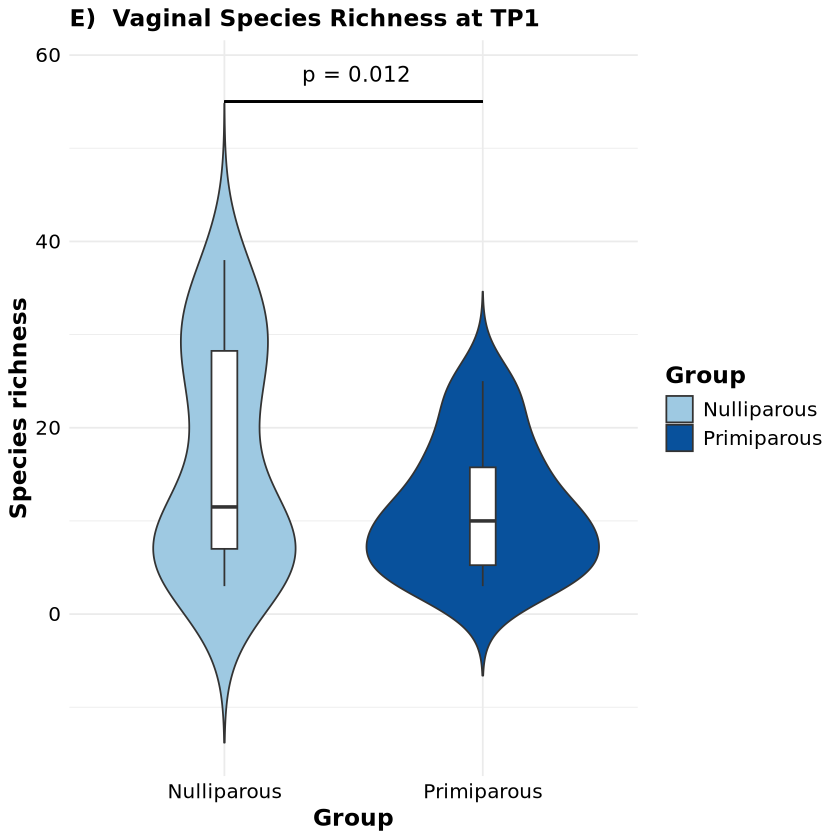

In [380]:
#Richness diversity Violin plot at TP1
my_plot_rich_tp1 <- ggplot(df_richness_tp1, aes(x = Group, y = Species_richness, fill = Group)) +
  geom_violin(trim = FALSE) +
  geom_boxplot(width = 0.1, fill = "white", outlier.shape = NA) +
  scale_fill_manual(values = c("Nulliparous" = "#9EC9E2", "Primiparous" = "#08519C")) +
  labs(title = "E)  Vaginal Species Richness at TP1", x = "Group", y = "Species richness") +
  theme_minimal() +
  shared_theme

my_plot_rich_tp1 <- my_plot_rich_tp1 +
  annotate("text", x = 1.3, y = 58,
           label = paste("p =", round(rich_tp1_p, 3)),
           color = "black", size = 4.5, hjust = 0) +
  geom_segment(aes(x = 1, xend = 2, y = 55, yend = 55),
               color = "black", size = 0.4)

my_plot_rich_tp1


In [381]:
ggsave(file.path(base_path,"Consecutive_preg/Github_version/Vagina/data/tp1_richness.pdf"),
       my_plot_rich_tp1,
       width  = 200,
       height = 150,
       units  = "mm",
       device = cairo_pdf)

#### pcoa plot

In [199]:
plot_pcoa <- function(dist_obj, meta, title = NULL, r2_val = NULL, p_val = NULL) {
  
  pcoa <- cmdscale(dist_obj, k = 2, eig = TRUE)
  var_exp <- round(100 * pcoa$eig[1:2] / sum(pcoa$eig[pcoa$eig > 0]), 1)
  
  plot_df <- data.frame(
    PC1 = pcoa$points[, 1],
    PC2 = pcoa$points[, 2],
    Group = meta$Group
  )
  
  p <- ggplot(plot_df, aes(PC1, PC2, colour = Group)) +
    geom_point(size = 2.5, alpha = 0.85) +
    stat_ellipse(level = 0.95, linewidth = 0.5) +
    scale_colour_manual(values = c(
      Nulliparous = "#9EC9E2",
      Primiparous = "#08519C"
    )) +
    labs(title = title,
        x = paste0("PCoA1 [", var_exp[1], "%]"),
        y = paste0("PCoA2 [", var_exp[2], "%]")) +
        theme_minimal() +
    shared_theme +
    theme(
     plot.title   = element_text(face = "plain"),
      axis.title.x = element_text(face = "plain"),
      axis.title.y = element_text(face = "plain")
    )  
  if (!is.null(r2_val) & !is.null(p_val)) {
    label_text <- paste0("R\u00B2 = ", sprintf("%.3f", r2_val), "\np = ", sprintf("%.3f", p_val))
    
    p <- p + annotate("text", x = Inf, y = Inf,
                      label = label_text,
                      hjust = 1.1, vjust = 1.5,
                      size = 3.5, fontface = "bold", color = "black")
  }
  
  p
}

In [190]:
plot_jac_tp1 <- plot_pcoa (dist_jac_tp1, meta_tp1, "Jaccard dissimilarity",r2_j_tp1,p_j_tp1 )
plot_ait_tp1 <- plot_pcoa (dist_ait_tp1, meta_tp1, "Robust Aitchison distance", r2_AT_tp1, p_AT_tp1)
plot_bc_tp1  <- plot_pcoa (dist_bc_tp1,  meta_tp1, "Bray-Curtis dissimilarity",r2_BC_tp1, p_BC_tp1)

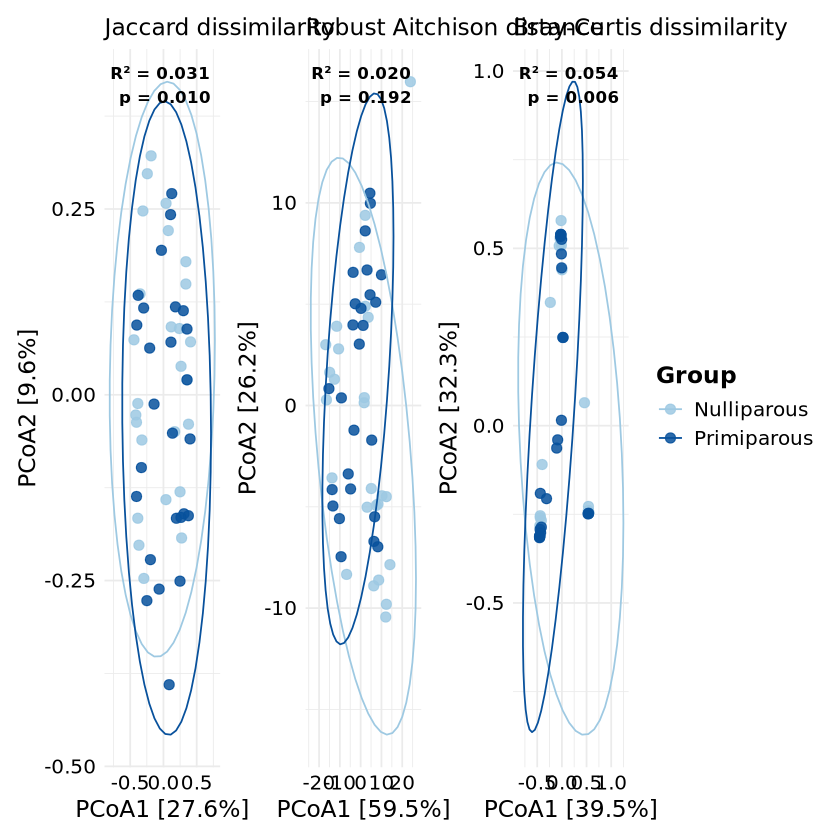

In [191]:
Figure_pcoa_combined_tp1 <- (plot_jac_tp1| plot_ait_tp1 |plot_bc_tp1) +
  plot_layout(guides = "collect") &
  theme(legend.position = "right")

Figure_pcoa_combined_tp1

In [192]:
plot_jac_tp2 <- plot_pcoa (dist_jac_tp2, meta_tp2, "Jaccard dissimilarity",r2_j_tp2,p_j_tp2 )
plot_ait_tp2 <- plot_pcoa (dist_ait_tp2, meta_tp2, "Robust Aitchison distance", r2_AT_tp2, p_AT_tp2)
plot_bc_tp2  <- plot_pcoa (dist_bc_tp2,  meta_tp2, "Bray-Curtis dissimilarity",r2_BC_tp2, p_BC_tp2)

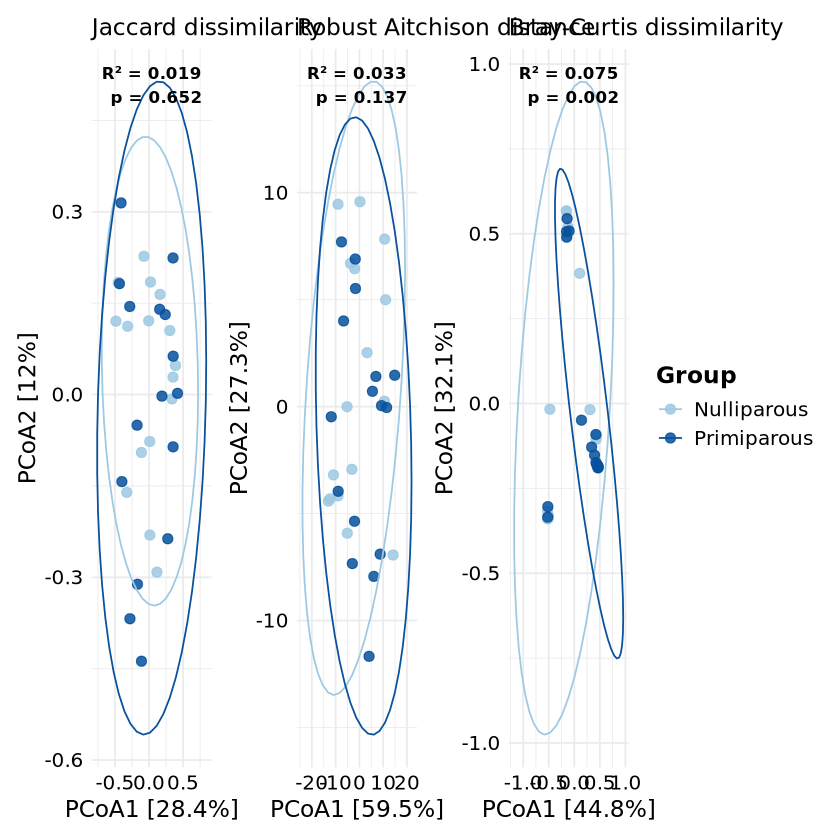

In [193]:
Figure_pcoa_combined_tp2 <- (plot_jac_tp2| plot_ait_tp2 |plot_bc_tp2) +
  plot_layout(guides = "collect") &
  theme(legend.position = "right")

Figure_pcoa_combined_tp2

In [194]:
# Create heading for TP1
row1_heading_pcoa <- ggplot() +
  annotate(
    "text",
    x = 0, y = 0,
    label = "A) Vaginal composition by parity at TP1",
    hjust = 0,
    size = 5,
    fontface = "bold"
  ) +
  theme_void() +
  xlim(0, 1) +
  ylim(-1, 1)

# Create heading for TP2
row2_heading_pcoa <- ggplot() +
  annotate(
    "text",
    x = 0, y = 0,
    label = "B) Vaginal composition by parity at TP2",
    hjust = 0,
    size = 5,
    fontface = "bold"
  ) +
  theme_void() +
  xlim(0, 1) +
  ylim(-1, 1)

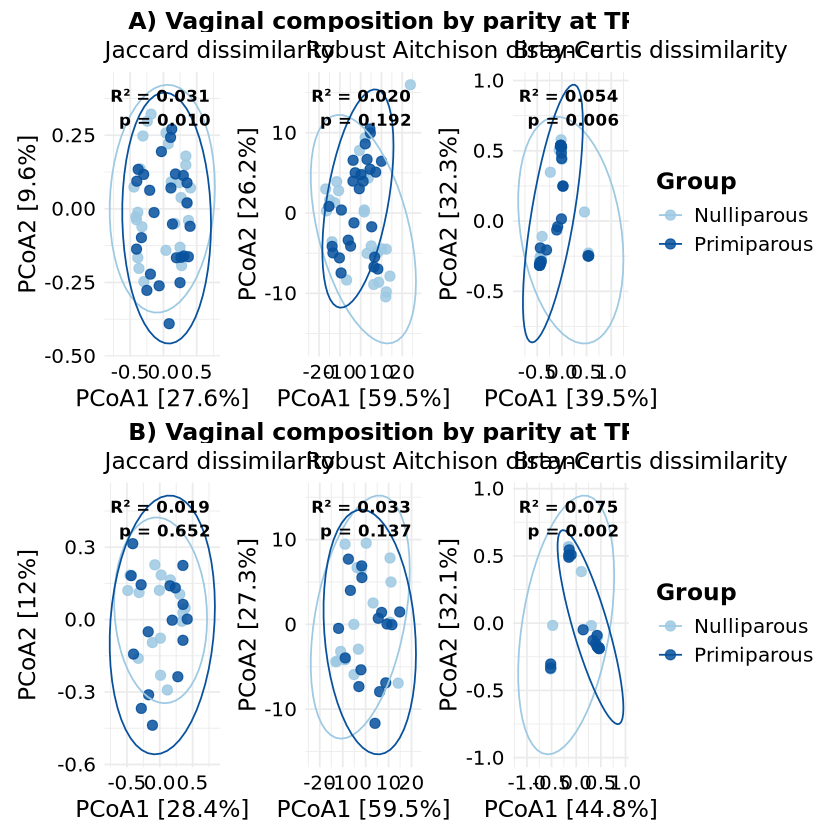

In [195]:
#Combine all plots
Figure_3<-
  (
    row1_heading_pcoa /
    Figure_pcoa_combined_tp1 /
    row2_heading_pcoa /
    Figure_pcoa_combined_tp2
  ) +
  plot_layout(
    heights = c(0.08, 1, 0.08, 1),
    guides = "collect"
  ) &
  theme(legend.position = "right")

Figure_3

In [73]:
# EPS
ggsave(
  file.path(base_path, "Consecutive_preg/Github_version/vagina/data/Figure_3.eps"),
  plot = Figure_3,
  width = 300,
  height = 240,
  units = "mm",
  device = cairo_ps
)

# TIFF
ggsave(
  file.path(base_path, "Consecutive_preg/Github_version/vagina/data/Figure_3.tiff"),
  plot = Figure_3,
  width = 300,
  height = 240,
  units = "mm",
  dpi = 800,
  device = "tiff",
  compression = "lzw"
)

ERROR: [1m[33mError[39m in `ggsave()`:[22m
[1m[22m[33m![39m Cannot find directory [34m/proj/h-mel-phylo/h-mel-phylo/private/anusha/Consecutive_preg/Github_version/vagina/data[39m.
[36mℹ[39m Please supply an existing directory or use `create.dir = TRUE`.


In [197]:
ggsave(
  filename = file.path(
    base_path,
    "Consecutive_preg/Github_version/vagina/data/Figure_3.pdf"
  ),
  plot   = Figure_3,
  width  = 300,
  height = 240,
  units  = "mm",
  device = cairo_pdf
)

#### Maaslin3 output figures

In [29]:
sp <- c("Gardnerella vaginalis", "Lactobacillus gasseri","Lactobacillus crispatus", "Lactobacillus iners")

In [30]:

df_raincloud <- tp1_taxa %>%
  filter(rownames(tp1_taxa) %in% sp )
df_raincloud

,FF00653546,FB02825409,FF02015345,FF00653065,FF02014263,FF02015432,FF00657563,FF00653167,FF02557868,FF02015815,⋯,FF04023664,FF06580399,FF04761460,FF01570782,FF01570777,FF05043003,FF05025300,FF05043036,FF00530247,FF03816924
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Gardnerella vaginalis,0.10261,65.01676,0.00000,0.07743,0.01565,2.68918,0.81406,0.00350,0.00000,68.15267,⋯,0.66084,0.11786,84.69319,0.00000,0.33784,1.01543,8.00918,76.48466,84.41986,31.26001
Lactobacillus crispatus,98.22154,0.00040,68.66689,0.01344,99.95610,0.09782,0.05233,0.00000,98.47172,0.00103,⋯,0.16900,0.00000,0.00000,0.00689,99.59399,98.67820,0.10675,0.00000,0.00503,0.01990
Lactobacillus gasseri,0.00000,0.00000,0.00000,0.05156,0.00000,0.00000,0.00000,0.01968,0.00000,0.00000,⋯,21.45223,1.87162,0.00000,0.00000,0.00000,0.04450,91.68335,0.00000,0.00000,0.00000
Lactobacillus iners,0.03729,2.09442,26.41681,98.58725,0.02825,85.64532,39.09981,25.11866,0.01080,3.56968,⋯,0.09539,93.00983,0.00000,99.99159,0.00000,0.00037,0.00000,0.00000,0.00027,0.00000


In [31]:
df_raincloud_t <- as.data.frame(t(df_raincloud))
head(df_raincloud_t)

,Gardnerella vaginalis,Lactobacillus crispatus,Lactobacillus gasseri,Lactobacillus iners
,<dbl>,<dbl>,<dbl>,<dbl>
FF00653546,0.10261,98.22154,0.00000,0.03729
FB02825409,65.01676,0.00040,0.00000,2.09442
FF02015345,0.00000,68.66689,0.00000,26.41681
FF00653065,0.07743,0.01344,0.05156,98.58725
FF02014263,0.01565,99.95610,0.00000,0.02825
FF02015432,2.68918,0.09782,0.00000,85.64532


In [32]:
head(meta_tp1)

,Studienummer,Q1_Personnummer,Sample_id,Group,Time_point
,<chr>,<chr>,<chr>,<chr>,<chr>
FF02014263,S194e21b,P159f9c8,FF02014263,Nulliparous,TP1
FF00653507,S1f862a6,P1f862a6,FF00653507,Nulliparous,TP1
FF00653546,S1f95844,P1f95844,FF00653546,Nulliparous,TP1
FF02557868,S2b86cc0,P3cac7b0,FF02557868,Nulliparous,TP1
FB02825409,S39fe1d7,P3db7da6,FB02825409,Nulliparous,TP1
FF00657534,S7e4a963,P424fd61,FF00657534,Nulliparous,TP1


In [33]:
raincloud_taxa <- df_raincloud_t[rownames(meta_tp1), ]
head(raincloud_taxa )


,Gardnerella vaginalis,Lactobacillus crispatus,Lactobacillus gasseri,Lactobacillus iners
,<dbl>,<dbl>,<dbl>,<dbl>
FF02014263,0.01565,99.95610,0,0.02825
FF00653507,82.45861,0.00000,0,0.00295
FF00653546,0.10261,98.22154,0,0.03729
FF02557868,0.00000,98.47172,0,0.01080
FB02825409,65.01676,0.00040,0,2.09442
FF00657534,22.25648,0.01391,0,71.16436


In [34]:
table(meta_tp1$Group)


Nulliparous Primiparous 
         26          26 

In [35]:
# 3. Extract metadata columns
meta_rain <- as.data.frame(meta_tp1) %>%
  rownames_to_column(var = "sample_id") %>%
  select(sample_id, Q1_Personnummer, Group)
head(meta_rain)

,sample_id,Q1_Personnummer,Group
,<chr>,<chr>,<chr>
1,FF02014263,P159f9c8,Nulliparous
2,FF00653507,P1f862a6,Nulliparous
3,FF00653546,P1f95844,Nulliparous
4,FF02557868,P3cac7b0,Nulliparous
5,FB02825409,P3db7da6,Nulliparous
6,FF00657534,P424fd61,Nulliparous


In [36]:
raincloud_taxa_1 <- as.data.frame(raincloud_taxa) %>%
  rownames_to_column(var = "sample_id")
head(raincloud_taxa_1)

,sample_id,Gardnerella vaginalis,Lactobacillus crispatus,Lactobacillus gasseri,Lactobacillus iners
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,FF02014263,0.01565,99.95610,0,0.02825
2,FF00653507,82.45861,0.00000,0,0.00295
3,FF00653546,0.10261,98.22154,0,0.03729
4,FF02557868,0.00000,98.47172,0,0.01080
5,FB02825409,65.01676,0.00040,0,2.09442
6,FF00657534,22.25648,0.01391,0,71.16436


In [37]:
all(raincloud_taxa_1$sample_id == meta_rain$sample_id)

[1] TRUE

In [38]:
# Merge into a single long dataset
raincloud_merged <- inner_join(meta_rain, raincloud_taxa_1, by = "sample_id")
head(raincloud_merged)

,sample_id,Q1_Personnummer,Group,Gardnerella vaginalis,Lactobacillus crispatus,Lactobacillus gasseri,Lactobacillus iners
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,FF02014263,P159f9c8,Nulliparous,0.01565,99.95610,0,0.02825
2,FF00653507,P1f862a6,Nulliparous,82.45861,0.00000,0,0.00295
3,FF00653546,P1f95844,Nulliparous,0.10261,98.22154,0,0.03729
4,FF02557868,P3cac7b0,Nulliparous,0.00000,98.47172,0,0.01080
5,FB02825409,P3db7da6,Nulliparous,65.01676,0.00040,0,2.09442
6,FF00657534,P424fd61,Nulliparous,22.25648,0.01391,0,71.16436


In [39]:
# Pivot all species columns into rows
raincloud_merged_2 <- raincloud_merged  %>%
  pivot_longer(
    cols = -c(sample_id, Q1_Personnummer, Group), # Exclude metadata columns
    names_to = "Species",
    values_to = "Raw_Abundance"
  )
head(raincloud_merged_2)

sample_id,Q1_Personnummer,Group,Species,Raw_Abundance
<chr>,<chr>,<chr>,<chr>,<dbl>
FF02014263,P159f9c8,Nulliparous,Gardnerella vaginalis,0.01565
FF02014263,P159f9c8,Nulliparous,Lactobacillus crispatus,99.95610
FF02014263,P159f9c8,Nulliparous,Lactobacillus gasseri,0.00000
FF02014263,P159f9c8,Nulliparous,Lactobacillus iners,0.02825
FF00653507,P1f862a6,Nulliparous,Gardnerella vaginalis,82.45861
FF00653507,P1f862a6,Nulliparous,Lactobacillus crispatus,0.00000


In [40]:
# Set Nulliparous as the baseline reference level
raincloud_merged_3 <- raincloud_merged_2 %>%
  mutate(
    Group = factor(Group, levels = c("Nulliparous", "Primiparous"))
  )
head(raincloud_merged_3)

sample_id,Q1_Personnummer,Group,Species,Raw_Abundance
<chr>,<chr>,<fct>,<chr>,<dbl>
FF02014263,P159f9c8,Nulliparous,Gardnerella vaginalis,0.01565
FF02014263,P159f9c8,Nulliparous,Lactobacillus crispatus,99.95610
FF02014263,P159f9c8,Nulliparous,Lactobacillus gasseri,0.00000
FF02014263,P159f9c8,Nulliparous,Lactobacillus iners,0.02825
FF00653507,P1f862a6,Nulliparous,Gardnerella vaginalis,82.45861
FF00653507,P1f862a6,Nulliparous,Lactobacillus crispatus,0.00000


In [41]:
# Calculate Log2 Relative Abundance; why? 
#In MaAsLin 3, specifying transform = "LOG" applies a $\log_2$ transformation by default. 
#The model coefficients (coef) in your all_results.tsv file represent log_2 fold changes. 
#Using log_2 for the raincloud plot keeps the y-axis on the exact same scale as the statistical effect sizes reported by the model.

raincloud_abundance <- raincloud_merged_3%>%
  mutate(
    Log2_Abundance = log2(Raw_Abundance + 1e-5)
  )
head(raincloud_abundance )

sample_id,Q1_Personnummer,Group,Species,Raw_Abundance,Log2_Abundance
<chr>,<chr>,<fct>,<chr>,<dbl>,<dbl>
FF02014263,P159f9c8,Nulliparous,Gardnerella vaginalis,0.01565,-5.996772
FF02014263,P159f9c8,Nulliparous,Lactobacillus crispatus,99.95610,6.643223
FF02014263,P159f9c8,Nulliparous,Lactobacillus gasseri,0.00000,-16.609640
FF02014263,P159f9c8,Nulliparous,Lactobacillus iners,0.02825,-5.145095
FF00653507,P1f862a6,Nulliparous,Gardnerella vaginalis,82.45861,6.365598
FF00653507,P1f862a6,Nulliparous,Lactobacillus crispatus,0.00000,-16.609640


In [42]:
# Create binary presence/absence indicator
raincloud_final <- raincloud_abundance %>%
  mutate(
    Status = ifelse(Raw_Abundance > 0, "Present", "Absent"),
    Status = factor(Status, levels = c("Present", "Absent"))
  )
head(raincloud_final)

sample_id,Q1_Personnummer,Group,Species,Raw_Abundance,Log2_Abundance,Status
<chr>,<chr>,<fct>,<chr>,<dbl>,<dbl>,<fct>
FF02014263,P159f9c8,Nulliparous,Gardnerella vaginalis,0.01565,-5.996772,Present
FF02014263,P159f9c8,Nulliparous,Lactobacillus crispatus,99.95610,6.643223,Present
FF02014263,P159f9c8,Nulliparous,Lactobacillus gasseri,0.00000,-16.609640,Absent
FF02014263,P159f9c8,Nulliparous,Lactobacillus iners,0.02825,-5.145095,Present
FF00653507,P1f862a6,Nulliparous,Gardnerella vaginalis,82.45861,6.365598,Present
FF00653507,P1f862a6,Nulliparous,Lactobacillus crispatus,0.00000,-16.609640,Absent


In [43]:
#Extract MaAsLin 3 Statistics for Plot Annotations
get_maaslin_stats <- function(sp_name, model_type) {
  res <- filt_ouput %>% 
    filter(feature == sp_name & model == model_type)
  
  if(nrow(res) > 0) {
    paste0("coef = ", round(res$coef[1], 2), 
           ", p = ", round(res$pval_individual[1], 4), 
           ", q = ", round(res$qval_individual[1], 3))
  } else {
    ""
  }
}

In [44]:
sp_in_abd <- c("Gardnerella vaginalis", "Lactobacillus gasseri","Lactobacillus crispatus")

In [45]:
df_raincloud <- raincloud_final %>%
  filter(Species %in% sp_in_abd)
head(df_raincloud)

sample_id,Q1_Personnummer,Group,Species,Raw_Abundance,Log2_Abundance,Status
<chr>,<chr>,<fct>,<chr>,<dbl>,<dbl>,<fct>
FF02014263,P159f9c8,Nulliparous,Gardnerella vaginalis,0.01565,-5.996772,Present
FF02014263,P159f9c8,Nulliparous,Lactobacillus crispatus,99.95610,6.643223,Present
FF02014263,P159f9c8,Nulliparous,Lactobacillus gasseri,0.00000,-16.609640,Absent
FF00653507,P1f862a6,Nulliparous,Gardnerella vaginalis,82.45861,6.365598,Present
FF00653507,P1f862a6,Nulliparous,Lactobacillus crispatus,0.00000,-16.609640,Absent
FF00653507,P1f862a6,Nulliparous,Lactobacillus gasseri,0.00000,-16.609640,Absent


In [46]:
# 1. Create a named vector of labels combining species names with MaAsLin 3 stats
species_labels <- c(
  "Gardnerella vaginalis" = paste0("G. vaginalis\n(", get_maaslin_stats("Gardnerella vaginalis", "abundance"), ")"),
  "Lactobacillus gasseri"   = paste0("L. gasseri\n(",   get_maaslin_stats("Lactobacillus gasseri",   "abundance"), ")"),
  "Lactobacillus crispatus" = paste0("L. crispatus\n(", get_maaslin_stats("Lactobacillus crispatus", "abundance"), ")")
)

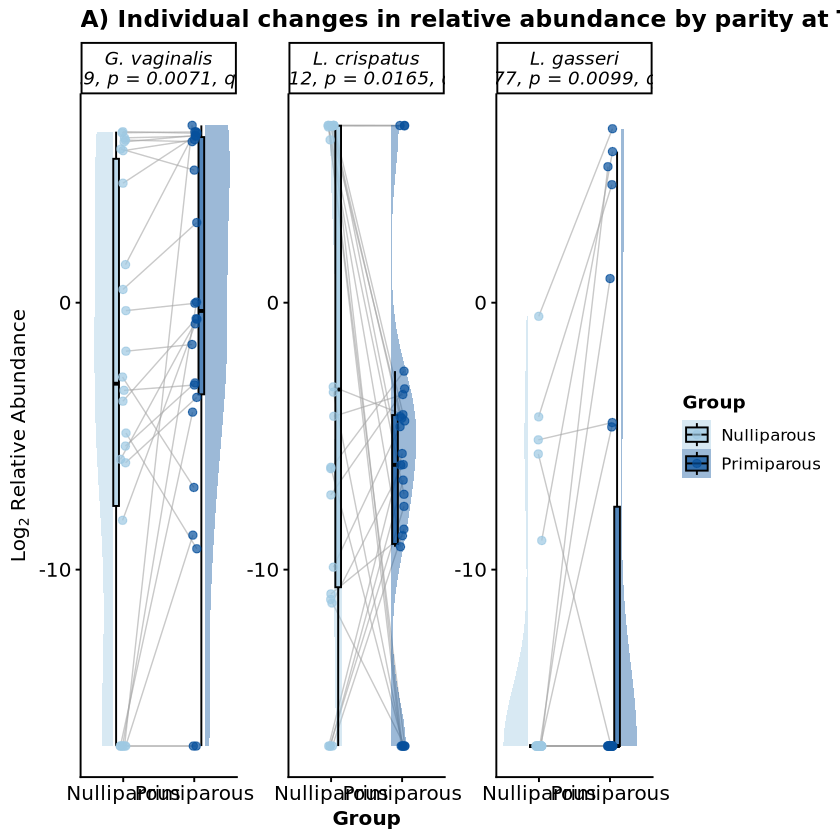

In [65]:

p_raincloud <- ggplot(
  df_raincloud,
  aes(
    x = Group,
    y = Log2_Abundance,
    fill = Group,
    color = Group
  )
) +
  geom_rain(
    id.long.var = "Q1_Personnummer",
    rain.side = "f1x1",
    alpha = 0.5,
    boxplot.args = list(
      color = "black",
      outlier.shape = NA,
      alpha = 0.7
    ),
    violin.args = list(
      color = NA,
      alpha = 0.4
    ),
    point.args = list(
      size = 2,
      alpha = 0.7
    ),
    line.args = list(
      color = "gray65",
      alpha = 0.6,
      linewidth = 0.4
    )
  ) +
  facet_wrap(
    ~ Species,
    scales = "free_y",
    nrow = 1,
    labeller = labeller(Species = species_labels)
  ) +
  scale_fill_manual(
    values = c(
      "Nulliparous" = "#9EC9E2",
      "Primiparous" = "#08519C"
    )
  ) +
  scale_color_manual(
    values = c(
      "Nulliparous" = "#9EC9E2",
      "Primiparous" = "#08519C"
    )
  ) +
  labs(
    x = "Group",
    y = expression(Log[2] ~ Relative ~ Abundance),
    title = "A) Individual changes in relative abundance by parity at TP1"
  ) +
  theme_classic(base_size = 12) +
  theme(
    plot.title    = element_text(face = "bold", size = 14, hjust = 0),
    plot.subtitle = element_text(size = 12, hjust = 0, color = "black"),
    axis.title    = element_text(face = "bold", size = 12),
    axis.text     = element_text(size = 12, color = "black"),
    axis.text.x   = element_text( size = 12, color = "black"),
    axis.text.y   = element_text( size = 12, color = "black"),
    strip.text    = element_text(face = "italic", size = 11, color = "black"),
    legend.title  = element_text(face = "bold", size = 11),
    legend.text   = element_text(size = 10),
    legend.position = "right"
  )
p_raincloud

In [66]:
# PDF
ggsave(
  filename = file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/Raincloud_TP1_sp_maaslin3.pdf"
  ),
  plot = p_raincloud,
  width = 350,
  height = 240,
  units = "mm",
  device = cairo_pdf
)

In [1]:
library(tidyverse)
library(dplyr)
library(ggplot2)
library(ggalluvial)
#(use the conda env R)

── Attaching core tidyverse packages ───────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
packageVersion("ggalluvial")

[1] ‘0.12.5’

In [48]:
head(raincloud_final)

sample_id,Q1_Personnummer,Group,Species,Raw_Abundance,Log2_Abundance,Status
<chr>,<chr>,<fct>,<chr>,<dbl>,<dbl>,<fct>
FF02014263,P159f9c8,Nulliparous,Gardnerella vaginalis,0.01565,-5.996772,Present
FF02014263,P159f9c8,Nulliparous,Lactobacillus crispatus,99.95610,6.643223,Present
FF02014263,P159f9c8,Nulliparous,Lactobacillus gasseri,0.00000,-16.609640,Absent
FF02014263,P159f9c8,Nulliparous,Lactobacillus iners,0.02825,-5.145095,Present
FF00653507,P1f862a6,Nulliparous,Gardnerella vaginalis,82.45861,6.365598,Present
FF00653507,P1f862a6,Nulliparous,Lactobacillus crispatus,0.00000,-16.609640,Absent


In [49]:
#Create individual-level transition table
df_iners_pair <- raincloud_final %>%
  filter(Species == "Lactobacillus iners") %>%
  select(Q1_Personnummer, Group, Status) %>%
  pivot_wider(names_from = Group, values_from = Status) %>%
  drop_na(Nulliparous, Primiparous) %>%
  mutate(
    Transition = case_when(
      Nulliparous == "Absent"  & Primiparous == "Present" ~ "Acquired (Absent -> Present)",
      Nulliparous == "Present" & Primiparous == "Absent"  ~ "Cleared (Present -> Absent)",
      Nulliparous == "Present" & Primiparous == "Present" ~ "Persistent Present (Present -> Present)",
      Nulliparous == "Absent"  & Primiparous == "Absent"  ~ "Persistent Absent (Absent -> Absent)"
    )
  )

# View individual transitions per woman
head(df_iners_pair)

Q1_Personnummer,Nulliparous,Primiparous,Transition
<chr>,<fct>,<fct>,<chr>
P159f9c8,Present,Present,Persistent Present (Present -> Present)
P1f862a6,Present,Present,Persistent Present (Present -> Present)
P1f95844,Present,Present,Persistent Present (Present -> Present)
P3cac7b0,Present,Absent,Cleared (Present -> Absent)
P3db7da6,Present,Present,Persistent Present (Present -> Present)
P424fd61,Present,Absent,Cleared (Present -> Absent)


In [50]:
df_alluvial <- df_iners_pair %>%
  count(Nulliparous, Primiparous, Transition)
df_alluvial 

Nulliparous,Primiparous,Transition,n
<fct>,<fct>,<chr>,<int>
Present,Present,Persistent Present (Present -> Present),16
Present,Absent,Cleared (Present -> Absent),8
Absent,Absent,Persistent Absent (Absent -> Absent),2


In [51]:
iners_stats <- get_maaslin_stats("Lactobacillus iners", "prevalence")

In [53]:
df_women <- df_alluvial |>
  uncount(n) |>
  mutate(
    id = row_number(),
    Transition = factor(Transition, levels = c(
      "Cleared (Present -> Absent)",
      "Acquired (Absent -> Present)",
      "Persistent Present (Present -> Present)",
      "Persistent Absent (Absent -> Absent)"
    ))
  )


Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”


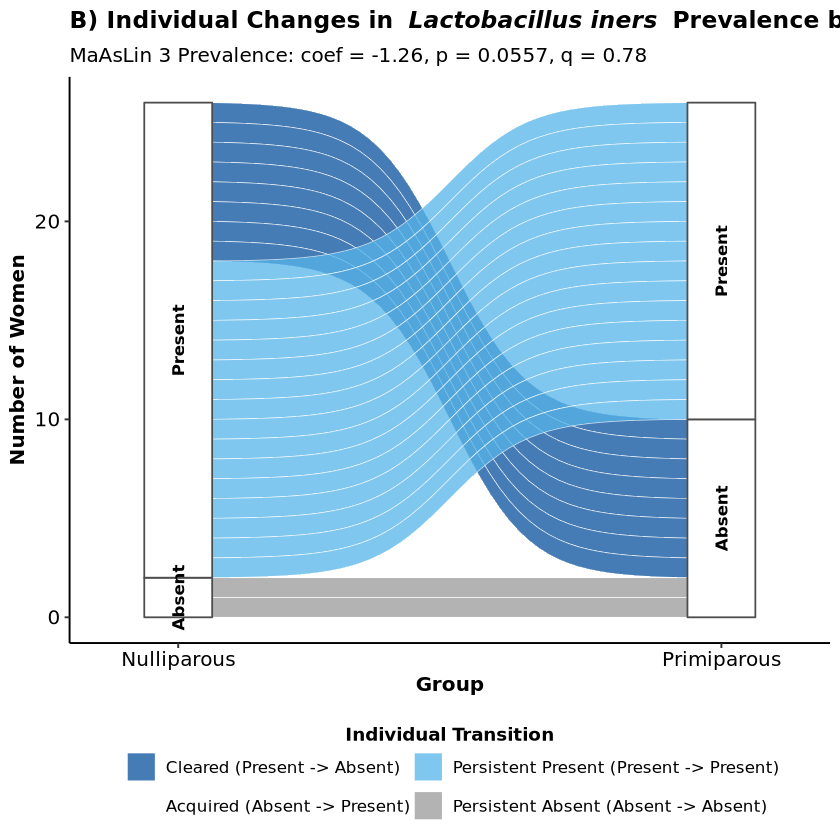

In [55]:
p_alluvial <- ggplot(df_women, aes(axis1 = Nulliparous, axis2 = Primiparous)) +
  geom_alluvium(aes(fill = Transition),
                width = 1/8, alpha = 0.75, curve_type = "sigmoid",
                aes.bind = "alluvia",          # order by colour -> ribbons cross
                color = "white", linewidth = 0.2) +   # thin line between each woman
  geom_stratum(width = 1/8, fill = "white", color = "grey30") +
  geom_text(stat = "stratum", aes(label = after_stat(stratum)),
            angle = 90, fontface = "bold", size = 3.5) +
  scale_x_discrete(limits = c("Nulliparous", "Primiparous"), expand = c(0.1, 0.1)) +
  scale_fill_manual(values = c(
    "Acquired (Absent -> Present)"            = "#9EC9E2",
    "Cleared (Present -> Absent)"             = "#08519C",
    "Persistent Present (Present -> Present)" = "#56B4E9",
    "Persistent Absent (Absent -> Absent)"    = "#999999"
  ), drop = FALSE) +
  labs(
    x = "Group",
    y = "Number of Women",
    title = expression(
    bold("B) Individual Changes in ") ~
      bolditalic("Lactobacillus iners") ~
      bold(" Prevalence by Parity at TP1")
  ),
    subtitle = paste0("MaAsLin 3 Prevalence: ", get_maaslin_stats("Lactobacillus iners", "prevalence")),
    fill = "Individual Transition"
  ) +
  guides(fill = guide_legend(nrow = 2, title.position = "top", title.hjust = 0.5)) +
  theme_classic(base_size = 12) +
  theme(
    plot.title    = element_text(face = "bold", size = 14, hjust = 0),
    plot.subtitle = element_text(size = 12, hjust = 0, color = "black"),
    axis.title    = element_text(face = "bold", size = 12),
    axis.text     = element_text(size = 12, color = "black"),
    axis.text.x   = element_text( size = 12, color = "black"),
    axis.text.y   = element_text( size = 12, color = "black"),
    strip.text    = element_text(face = "italic", size = 11, color = "black"),
    legend.title  = element_text(face = "bold", size = 11),
    legend.text   = element_text(size = 10),
    legend.position = "bottom"
  )

print(p_alluvial)

In [163]:
# PDF
ggsave(
  filename = file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/alluvial_graph_iners.pdf"
  ),
  plot = p_alluvial,
  width = 300,
  height = 240,
  units = "mm",
  device = cairo_pdf
)

ERROR: Error: object 'p_alluvial' not found


In [165]:
# Combine the figures
# Import the first page of each PDF
fig_A <- image_read_pdf(file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/Raincloud_TP1_sp_maaslin3.pdf"
  ), pages = 1, density = 300)
fig_B <- image_read_pdf(file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/alluvial_graph_iners.pdf"), pages = 1, density = 300)



In [166]:
fig_A <- image_scale(fig_A, "x900")
fig_B <- image_scale(fig_B, "x1500")

In [167]:
fig_a <- image_background(fig_A, "white")
fig_b <- image_background(fig_B, "white")

In [168]:
A_B_merged <- image_append(c(fig_a, fig_b), stack = TRUE)


In [169]:
#image_write(A_B_merged, "Fig_5.pdf", format = "pdf", density = 300)

In [170]:
fig_A <- image_annotate(
  fig_A, "A",
  gravity = "northwest",
  location = "+30+30",
  size = 80,
  weight = 700,
  color = "black"
)

fig_B <- image_annotate(
  fig_B, "B",
  gravity = "northwest",
  location = "+30+30",
  size = 80,
  weight = 700,
  color = "black"
)

In [171]:
image_write(
  A_B_merged,
  path = file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/Fig_5.pdf"),
  format = "pdf"
)

In [14]:
image_write(A_B_merged, file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/Fig_5.tiff"),
            format = "tiff", density = 300, compression = "LZW")


In [15]:
image_write(A_B_merged, file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/Fig_5.eps"),
            format = "eps", density = 300)

#### slopegraph

In [80]:
 #try slopegraph
slope_prev <- raincloud_final %>%
  filter(
    Species == "Lactobacillus iners",
    Group %in% c("Nulliparous", "Primiparous")
  ) %>%
  select(Q1_Personnummer, Group, Status) %>%
  distinct() %>%
  pivot_wider(names_from = Group, values_from = Status) %>%
  drop_na(Nulliparous, Primiparous) %>%
  mutate(
    Shift = case_when(
      Nulliparous == "Absent" & Primiparous == "Present" ~ "Acquired",
      Nulliparous == "Present" & Primiparous == "Absent" ~ "Cleared",
      TRUE ~ "Unchanged"
    )
  )
head(slope_prev)

Q1_Personnummer,Nulliparous,Primiparous,Shift
<chr>,<fct>,<fct>,<chr>
P159f9c8,Present,Present,Unchanged
P1f862a6,Present,Present,Unchanged
P1f95844,Present,Present,Unchanged
P3cac7b0,Present,Absent,Cleared
P3db7da6,Present,Present,Unchanged
P424fd61,Present,Absent,Cleared


In [85]:
slope_prev_wide <- slope_prev %>%
  arrange(Q1_Personnummer) %>%
  mutate(
    Women = paste("Woman", row_number())
  )
head(slope_prev_wide)

Q1_Personnummer,Nulliparous,Primiparous,Shift,Women
<chr>,<fct>,<fct>,<chr>,<chr>
P159f9c8,Present,Present,Unchanged,Woman 1
P1f862a6,Present,Present,Unchanged,Woman 2
P1f95844,Present,Present,Unchanged,Woman 3
P3cac7b0,Present,Absent,Cleared,Woman 4
P3db7da6,Present,Present,Unchanged,Woman 5
P424fd61,Present,Absent,Cleared,Woman 6


In [88]:
# Put each woman on a separate row
slope_prev_long <- slope_prev_wide%>%
  mutate(
    Women = factor(Women, levels = rev(Women))
  ) %>%
  pivot_longer(
    cols = c(Nulliparous, Primiparous),
    names_to = "Group",
    values_to = "Status"
  ) %>%
  mutate(
    Group = factor(Group, levels = c("Nulliparous", "Primiparous"))
  )
head(slope_prev_long )

Q1_Personnummer,Shift,Women,Group,Status
<chr>,<chr>,<fct>,<fct>,<fct>
P159f9c8,Unchanged,Woman 1,Nulliparous,Present
P159f9c8,Unchanged,Woman 1,Primiparous,Present
P1f862a6,Unchanged,Woman 2,Nulliparous,Present
P1f862a6,Unchanged,Woman 2,Primiparous,Present
P1f95844,Unchanged,Woman 3,Nulliparous,Present
P1f95844,Unchanged,Woman 3,Primiparous,Present


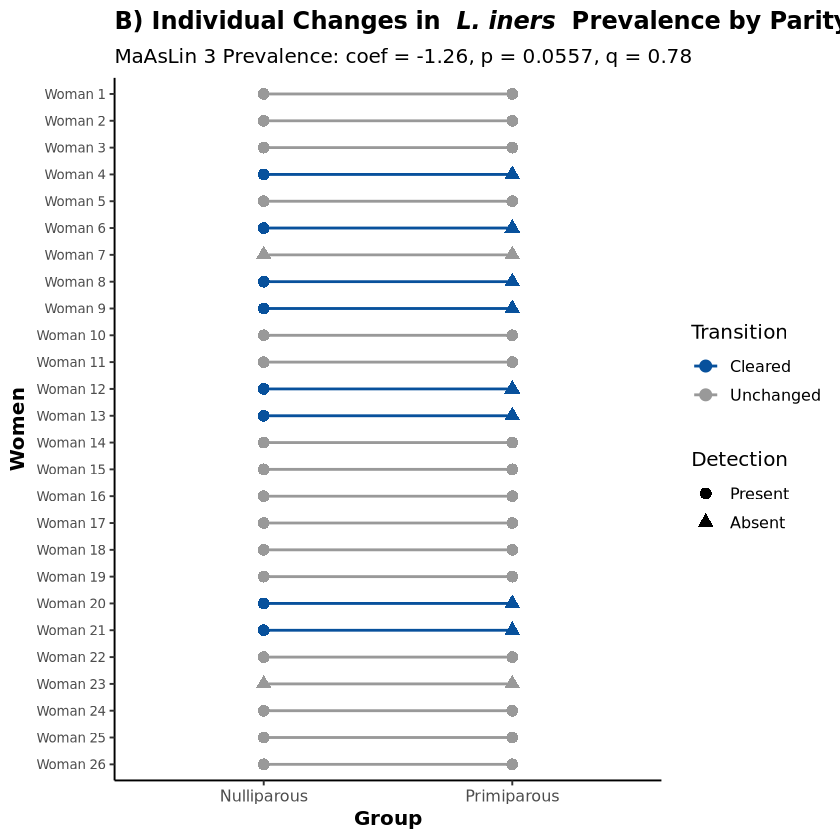

In [106]:
# Individual paired plot
slope_iners <- ggplot(
  slope_prev_long ,
  aes(
    x = Group,
    y = Women,
    group = Women,
    color = Shift
  )
) +
  geom_line(linewidth = 0.8) +
  geom_point(aes(shape = Status), size = 3) +
  scale_color_manual(values = c(
    "Acquired" = "#009E73",
    "Cleared" = "#08519C",
    "Unchanged" = "#999999"
  )) +
  labs(
  title = expression(
    bold("B) Individual Changes in ") ~
      bolditalic("L. iners") ~
      bold(" Prevalence by Parity at TP1")
  ),
    subtitle = paste0("MaAsLin 3 Prevalence: ", get_maaslin_stats("Lactobacillus iners", "prevalence")),
    x = "Group",
    y = "Women",
    color = "Transition",
    shape = "Detection"
  ) +
  theme_classic(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold"),
    strip.text = element_text(
      face = "bold.italic",
      size = 11,
      color = "black"),
    axis.title = element_text(face = "bold"),
    axis.text.y = element_text(size = 8),
    legend.position = "right"
  )
slope_iners

In [107]:
# PDF
ggsave(
  filename = file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/slope_graph_iners.pdf"
  ),
  plot = slope_iners,
  width = 300,
  height = 240,
  units = "mm",
  device = cairo_pdf
)

### 9.2 Supplementary figures/Data

In [ ]:
# S1 alpha diversity at TP1 and within-subject turnover

In [92]:
# Reshape wide to long
alpha_long <- alpha_delta %>%
  select(Q1_Personnummer, Group, Shannon_TP1, Shannon_TP2,
        Species_richness_TP1, Species_richness_TP2,
        Evenness_TP1, Evenness_TP2) %>%
  pivot_longer(
    cols = -c(Q1_Personnummer	, Group),
    names_to = c(".value", "Time_point"),
    names_pattern = "(.*)_(TP1|TP2)"
  ) %>%
  mutate(pair_id = paste(Q1_Personnummer	, Group, sep = "_"))
head(alpha_long)

Q1_Personnummer,Group,Time_point,Shannon,Species_richness,Evenness,pair_id
<chr>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
P1f95844,Nulliparous,TP1,0.13195913,29,0.039188457,P1f95844_Nulliparous
P1f95844,Nulliparous,TP2,0.06640487,22,0.021483002,P1f95844_Nulliparous
P3db7da6,Nulliparous,TP1,1.29491833,24,0.407456387,P3db7da6_Nulliparous
P3db7da6,Nulliparous,TP2,1.34955333,21,0.443272585,P3db7da6_Nulliparous
P159f9c8,Nulliparous,TP1,0.00411877,3,0.003749066,P159f9c8_Nulliparous
P159f9c8,Nulliparous,TP2,0.02133239,9,0.009708788,P159f9c8_Nulliparous


Warning message:
“Using the `size` aesthetic with geom_polygon was deprecated in ggplot2 3.4.0.
ℹ Please use the `linewidth` aesthetic instead.”


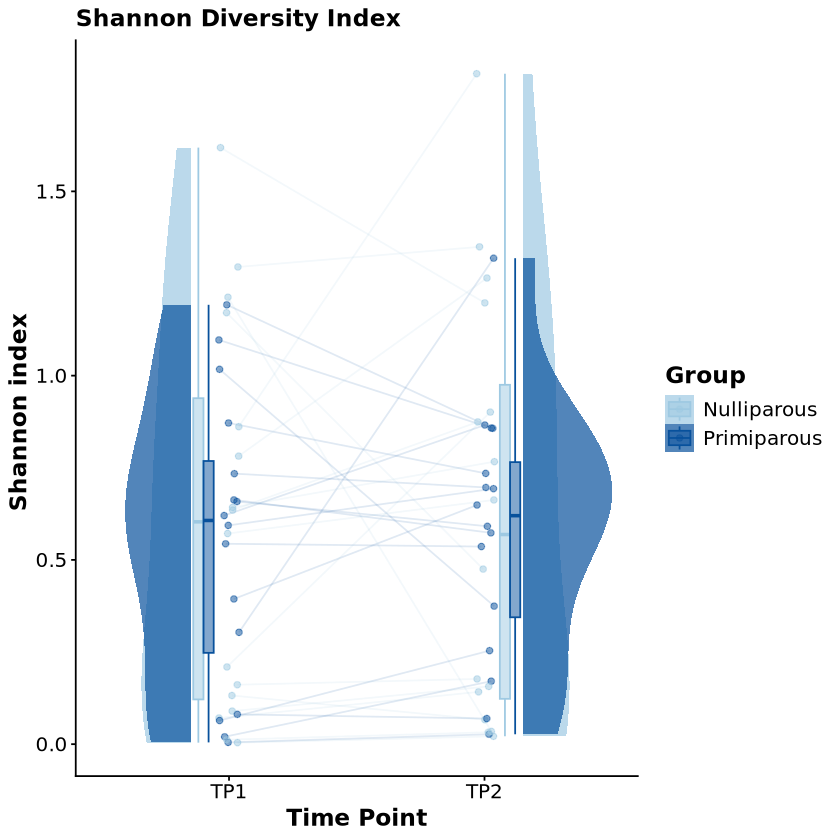

In [95]:
plot_shan <- ggplot(
  alpha_long,
  aes(x = Time_point, y = Shannon, fill = Group, color = Group)) +
  geom_rain(
    alpha = 0.5,
    rain.side = 'f2x2',
    id.long.var = "pair_id",
    violin.args = list(color = NA, alpha = 0.7),
    line.args = list(alpha = 0.12)
  ) +
  theme_classic() +
  scale_fill_manual(values = c("Nulliparous" = "#9EC9E2", "Primiparous" = "#08519C")) +
  scale_color_manual(values = c("Nulliparous" = "#9EC9E2", "Primiparous" = "#08519C"), name = "Group") +
  labs(x = "Time Point", y = "Shannon index ", title = "Shannon Diversity Index") +
  shared_theme

plot_shan

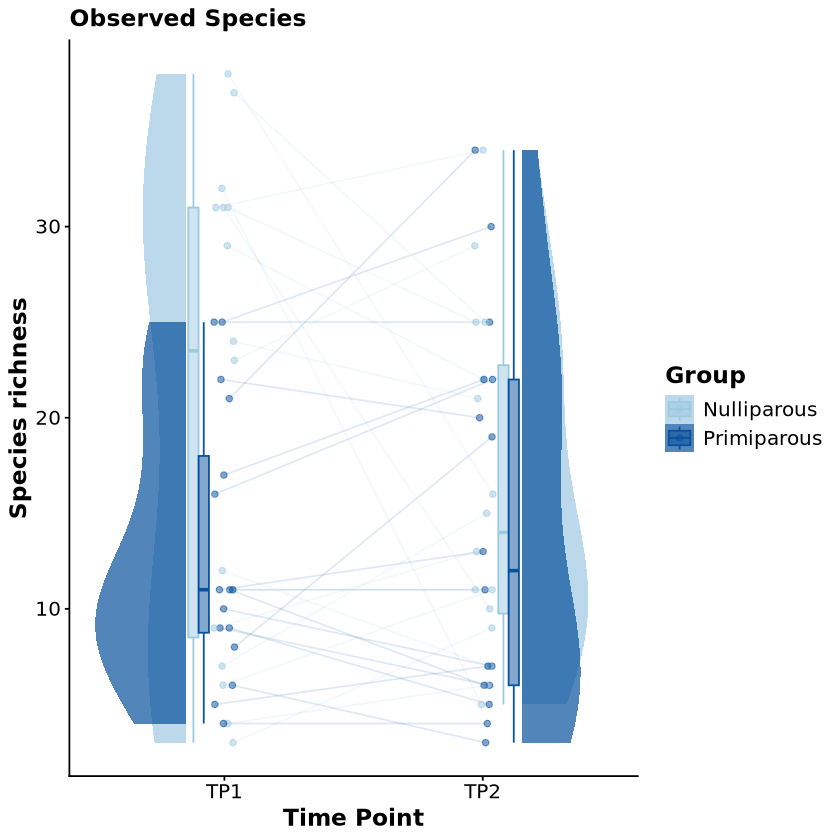

In [96]:
plot_rich <- ggplot(
  alpha_long,
  aes(x = Time_point, y = Species_richness, fill = Group, color = Group)) +
  geom_rain(
    alpha = 0.5,
    rain.side = 'f2x2',
    id.long.var = "pair_id",
    violin.args = list(color = NA, alpha = 0.7),
    line.args = list(alpha = 0.12)
  ) +
  theme_classic() +
  scale_fill_manual(values = c("Nulliparous" = "#9EC9E2", "Primiparous" = "#08519C")) +
  scale_color_manual(values = c("Nulliparous" = "#9EC9E2", "Primiparous" = "#08519C"), name = "Group") +
  labs(x = "Time Point", y = "Species richness", title = "Observed Species") +
  shared_theme

plot_rich

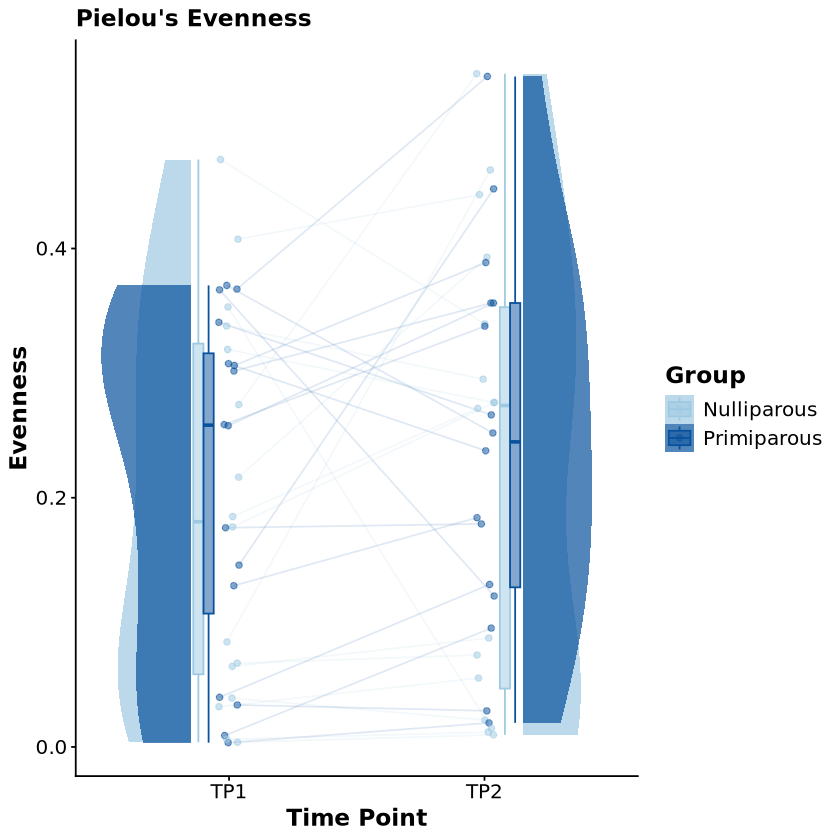

In [97]:
plot_even <- ggplot(
  alpha_long,
  aes(x = Time_point, y = Evenness, fill = Group, color = Group)) +
  geom_rain(
    alpha = 0.5,
    rain.side = 'f2x2',
    id.long.var = "pair_id",
    violin.args = list(color = NA, alpha = 0.7),
    line.args = list(alpha = 0.12)
  ) +
  theme_classic() +
  scale_fill_manual(values = c("Nulliparous" = "#9EC9E2", "Primiparous" = "#08519C")) +
  scale_color_manual(values = c("Nulliparous" = "#9EC9E2", "Primiparous" = "#08519C"), name = "Group") +
  labs(x = "Time Point", y = "Evenness", title = "Pielou's Evenness") +
  shared_theme

plot_even

In [98]:
add_pvalue_top <- function(plot, p_value, data_col) {
  
  y_top <- max(plot$data[[data_col]], na.rm = TRUE)
  y_range <- diff(range(plot$data[[data_col]], na.rm = TRUE))
  
  plot +
    annotate("segment", x = 1, xend = 2,
             y = y_top + 0.05 * y_range, yend = y_top + 0.05 * y_range,
             color = "black") +
    annotate("text", x = 1.5, y = y_top + 0.09 * y_range,
             label = paste("p =", round(p_value, 3)),
             size = 4.5) +
    coord_cartesian(clip = "off") +
    scale_y_continuous(expand = expansion(mult = c(0.05, 0.15)))
}

plot_shan <- add_pvalue_top(plot_shan, delta_shan_p, "Shannon")
plot_rich <- add_pvalue_top(plot_rich, delta_rich_p, "Species_richness")
plot_even <- add_pvalue_top(plot_even, delta_even_p, "Evenness")

In [99]:
plot_shan_nl <- plot_shan + theme(legend.position = "none")
plot_rich_nl <- plot_rich + theme(legend.position = "none")
plot_even_nl <- plot_even + theme(legend.position = "none")



In [100]:
Figure_rain_S2 <- (plot_shan_nl | plot_rich_nl | plot_even_nl) +
plot_layout(ncol = 3, guides = "collect") +
  plot_annotation(
    title = "Within-subject change in vaginal alpha diversity, by parity group",
    theme = theme(plot.title = element_text(size = 16, face = "bold"))
  ) 
heading <- function(label) {
  ggplot() +
    theme_void() +
    labs(title = label) +
    theme(
      plot.title = element_text(size = 18, face = "bold", hjust = 0),
      plot.margin = margin(5, 0, 5, 5)
    )
}

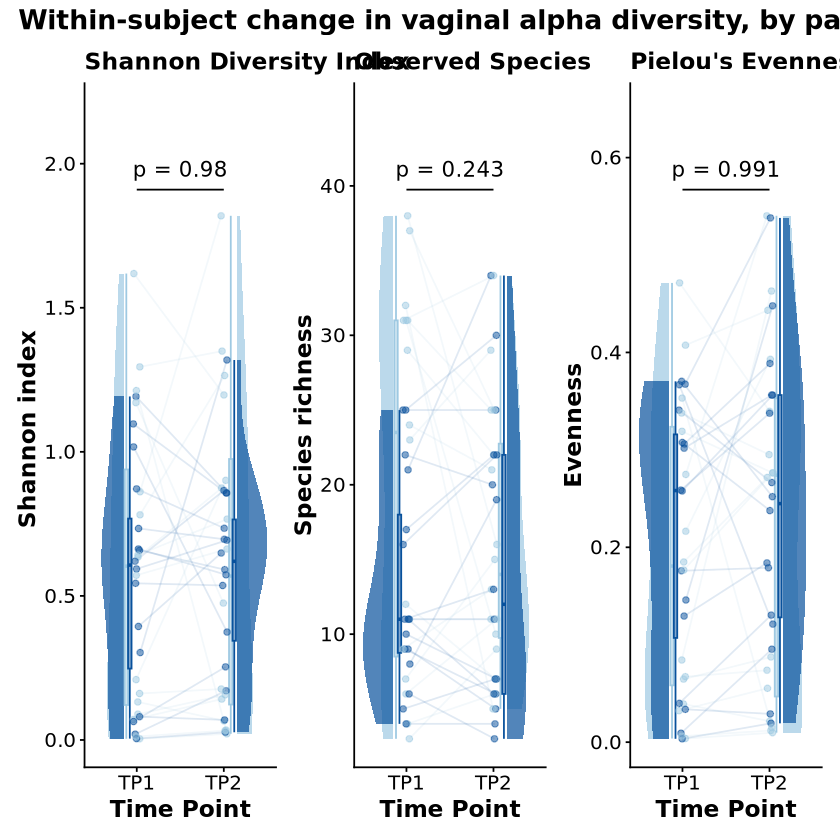

In [101]:
Figure_rain_S2

In [102]:
ggsave(file.path(base_path,"Consecutive_preg/Github_version/Vagina/data/Figure_S2_delta_alpha.pdf"),
       Figure_rain_S2,
       width  = 350,
       height = 240,
       units  = "mm",
       device = cairo_pdf)

Warning message in device(filename = "/proj/h-mel-phylo/h-mel-phylo/private/anusha/Consecutive_preg/Github_version/Vagina/data/Figure_S2_delta_alpha.pdf", :
“cairo error 'error while writing to output stream'”


ERROR: Error in device(filename = "/proj/h-mel-phylo/h-mel-phylo/private/anusha/Consecutive_preg/Github_version/Vagina/data/Figure_S2_delta_alpha.pdf", : unable to start device 'cairo_pdf'


In [278]:
# TIFF 
ggsave(file.path(base_path,"Consecutive_preg/Github_version/Vagina/data/Figure_S2_delta_alpha.tiff"),
        Figure_rain_S2,
       width       = 350,
       height      = 240,
       units       = "mm",
       limitsize   = FALSE,
       device      = "tiff",
       dpi         = 300,
       compression = "lzw")

# EPS
ggsave(file.path(base_path,"Consecutive_preg/Github_version/Vagina/data/Figure_S2_delta_alpha.eps"),
        Figure_rain_S2,
       width     = 350,
       height    = 240,
       units     = "mm",
       limitsize = FALSE,
       device    = cairo_ps)

In [206]:
#Sahred theme for the PCOA plot
shared_theme_1 <- theme(
  axis.title.x = element_text(size = 12, color = "black"),
  axis.text.x  = element_text(size = 11, color = "black"),
  axis.title.y = element_text(size = 12, color = "black"),
  axis.text.y  = element_text(size = 11, color = "black"),
  plot.title   = element_text(size = 12, color = "black", face = "bold"),
  legend.title = element_text(size = 12, color = "black", face = "bold"),
  legend.text  = element_text(size = 12, color = "black")
)

In [207]:
plot_pcoa_tp1_tp2 <- function(dist_obj, meta, title = NULL, r2_val = NULL, p_val = NULL) {
  
  pcoa <- cmdscale(dist_obj, k = 2, eig = TRUE)
  var_exp <- round(100 * pcoa$eig[1:2] / sum(pcoa$eig[pcoa$eig > 0]), 1)
  
  plot_df <- data.frame(
    PC1 = pcoa$points[, 1],
    PC2 = pcoa$points[, 2],
    Group = meta$Group,
    Time_point = meta$Time_point,
    woman = meta$Q1_Personnummer
  )
  
  p <- ggplot(plot_df, aes(PC1, PC2)) +
    geom_path(aes(group = interaction(woman, Group)),
              colour = "black",
              arrow = arrow(length = unit(0.15, "cm")),
              alpha = 0.4) +
    geom_point(aes(colour = Group, shape = Time_point), size = 2) +
    scale_colour_manual(values = c(
      Nulliparous = "#9EC9E2",
      Primiparous = "#08519C"
    )) +
    labs(title = title,
        x = paste0("PCoA1 [", var_exp[1], "%]"),
        y = paste0("PCoA2 [", var_exp[2], "%]")) +
    theme_minimal() +
    shared_theme_1
  
  # Place stats label top-right, positioned relative to this plot's own data range
  if (!is.null(r2_val) & !is.null(p_val)) {
    x_pos <- max(plot_df$PC1, na.rm = TRUE)
    y_pos <- max(plot_df$PC2, na.rm = TRUE)
    
    label_text <- paste0("R\u00B2 = ", sprintf("%.3f", r2_val), "\np = ", sprintf("%.3f", p_val))
    
    p <- p + annotate("text", x = x_pos, y = y_pos,
                      label = label_text,
                      hjust = 1, vjust = 1,
                      size = 3.5, fontface = "bold", color = "black")
  }
  
  p
}

In [208]:
plot_bc_tp1_tp2  <- plot_pcoa_tp1_tp2(delta_dist_bc,  delta_meta, "Bray-Curtis dissimilarity",       r2_bc, p_bc)
plot_jac_tp1_tp2 <- plot_pcoa_tp1_tp2(delta_dist_jac, delta_meta, "Jaccard dissimilarity",           r2_J,  p_J)
plot_ait_tp1_tp2 <- plot_pcoa_tp1_tp2(delta_dist_ait, delta_meta, "Robust Aitchison distance",  r2_AT, p_AT)

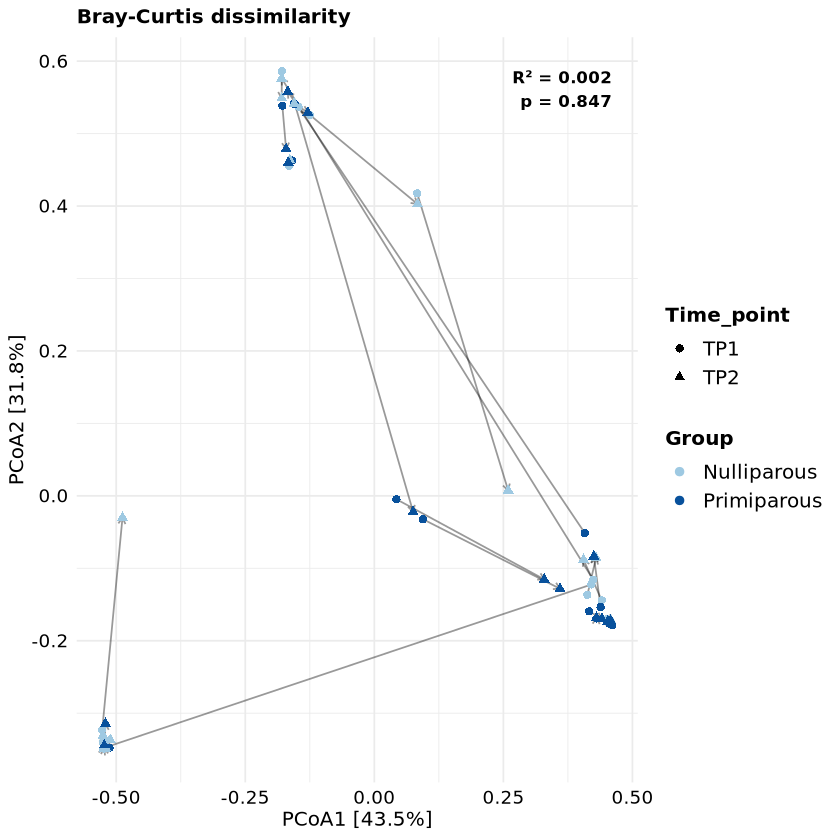

In [209]:
plot_bc_tp1_tp2

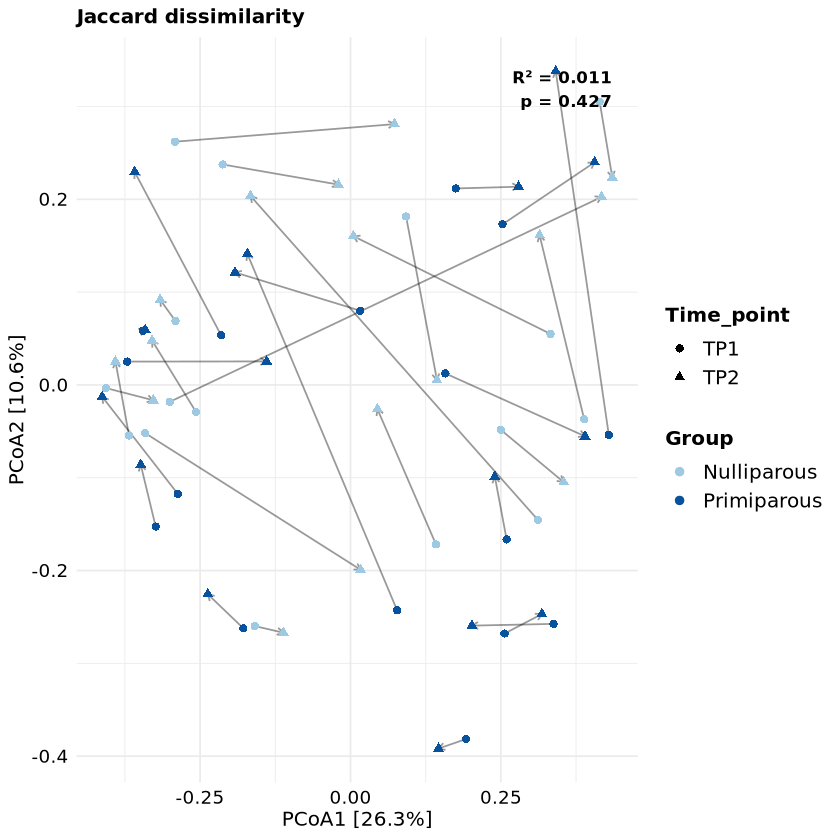

In [210]:
plot_jac_tp1_tp2

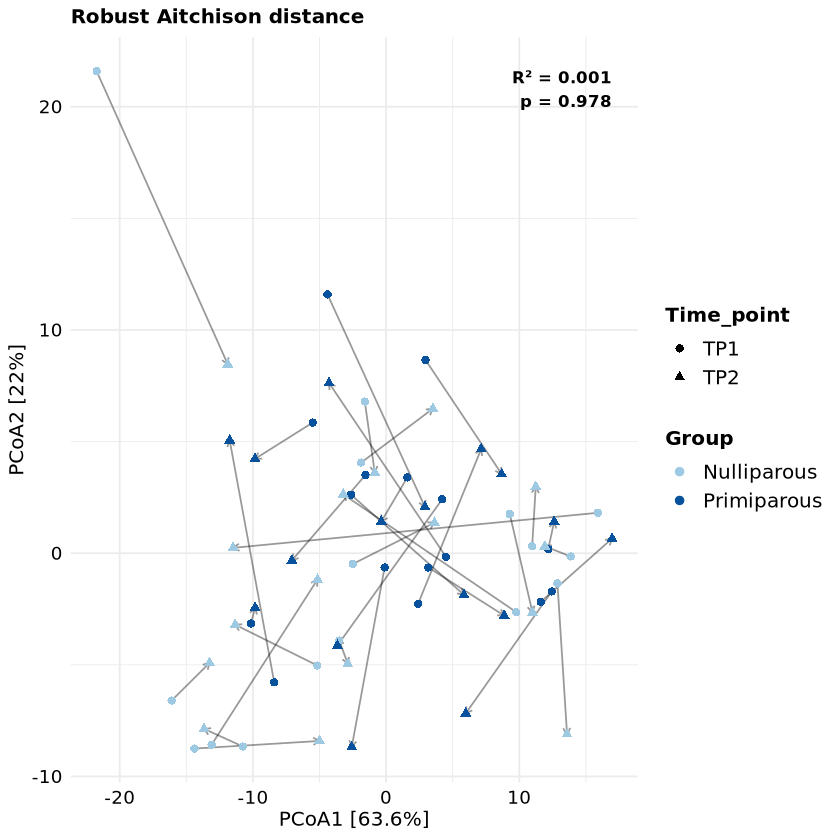

In [211]:
plot_ait_tp1_tp2

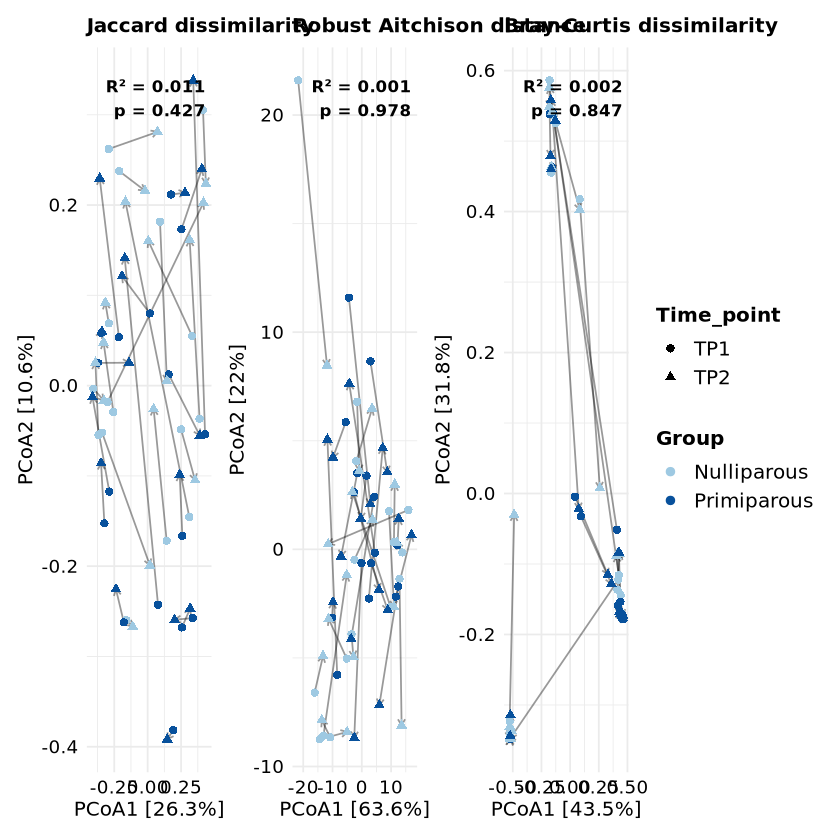

In [212]:
Figure_pcoa_combined <- (plot_jac_tp1_tp2| plot_ait_tp1_tp2 | plot_bc_tp1_tp2) +
  plot_layout(guides = "collect") &
  theme(legend.position = "right")

Figure_pcoa_combined

In [213]:
heading <- function(text, size = 14, face = "bold", hjust = 0) {
  ggplot() +
    annotate("text", x = hjust, y = 0.5, label = text,
             size = size / .pt, fontface = face, hjust = hjust) +
    scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
    scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
    theme_void()
}

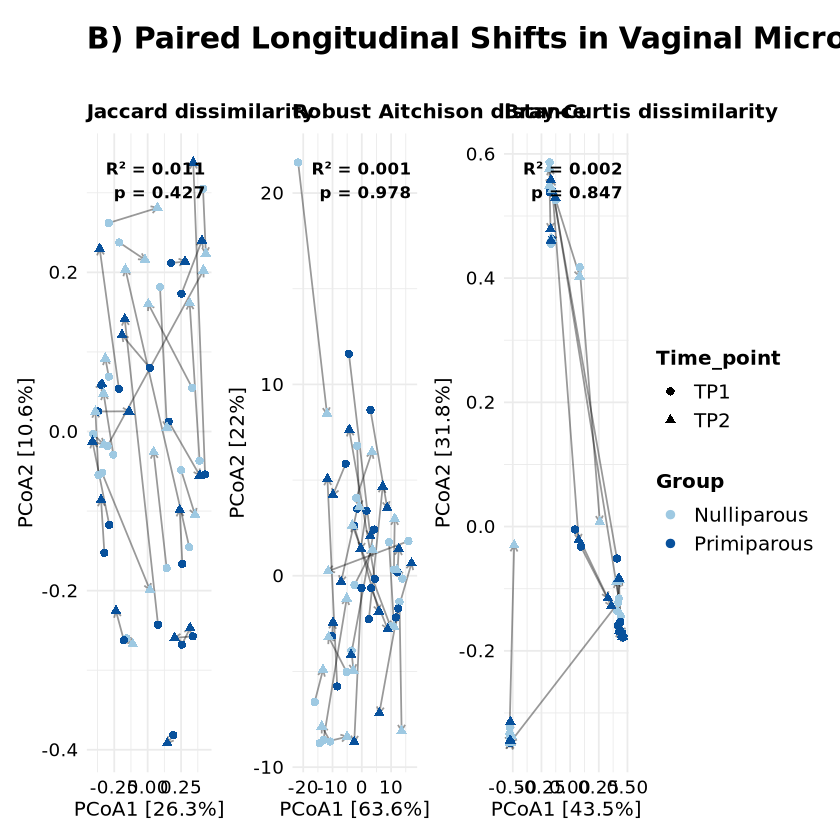

In [279]:
row2_heading_pcoa <- heading("B) Paired Longitudinal Shifts in Vaginal Microbial Community Composition")
Figure_S3_B <- (row2_heading_pcoa /Figure_pcoa_combined ) +
 plot_layout(heights = c(0.05, 1), guides = "collect") &
  theme(legend.position = "right")

Figure_S3_B

In [280]:
ggsave(file.path(base_path,"Consecutive_preg/Github_version/Vagina/data/S3_B_delta_beta.pdf"),
       Figure_S3_B,
       width  = 300,
       height = 150,
       units  = "mm",
       device = cairo_pdf)

In [285]:
# Combine the figures
# Import the first page of each PDF
fig_A <- image_read_pdf(file.path(
    base_path,
    "Consecutive_preg/Github_version/Gut/data/S3_A_delta_beta.pdf"
  ), pages = 1, density = 300)
fig_B <- image_read_pdf(file.path(
    base_path,
    "Consecutive_preg/Github_version/Vagina/data/S3_B_delta_beta.pdf"
  ), pages = 1, density = 300)



In [286]:
fig_a <- image_background(fig_A, "white")
fig_b <- image_background(fig_B, "white")

In [283]:
# a bit of white space between A and B
fig_a <- image_border(fig_a, "white", "0x30")

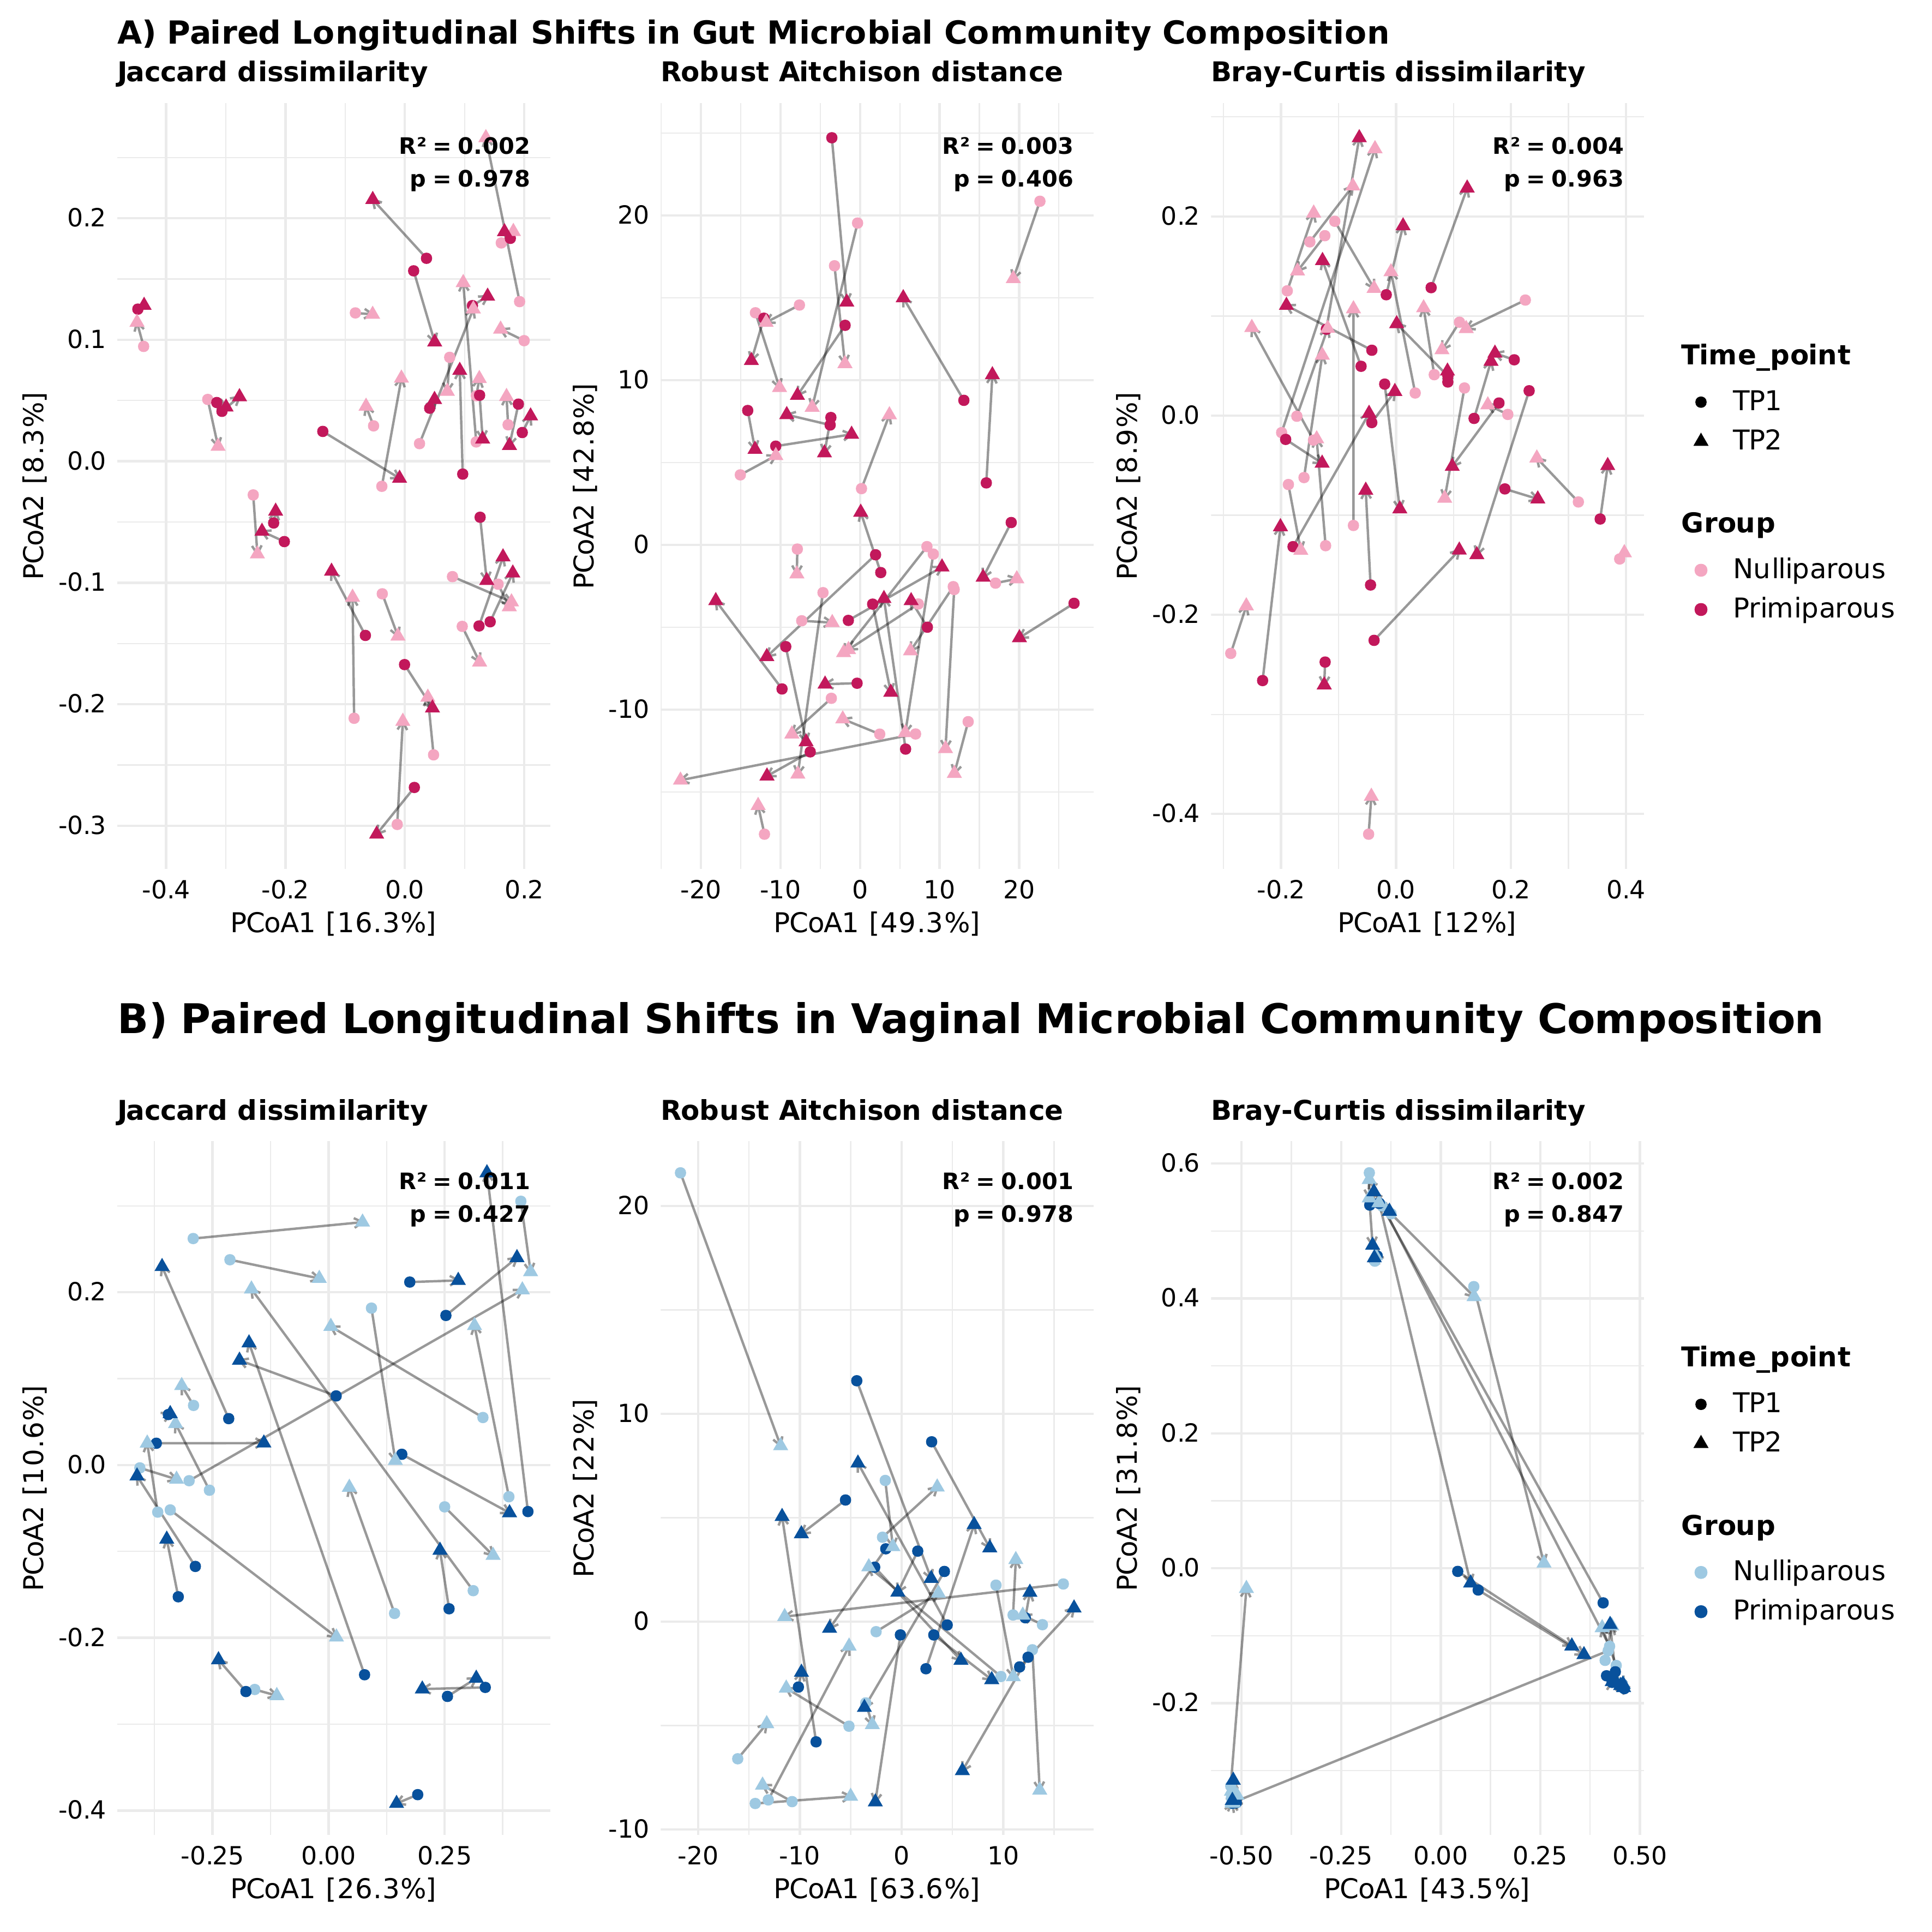

# A tibble: 1 × 7
  format width height colorspace matte filesize density  
  <chr>  <int>  <int> <chr>      <lgl>    <int> <chr>    
1 PNG     3542   3542 sRGB       TRUE         0 +300x+300

In [287]:
A_B_merged <- image_append(c(fig_a, fig_b), stack = TRUE)
A_B_merged

In [288]:
fig_A <- image_annotate(
  fig_A, "A",
  gravity = "northwest",
  location = "+30+30",
  size = 80,
  weight = 700,
  color = "black"
)

fig_B <- image_annotate(
  fig_B, "B",
  gravity = "northwest",
  location = "+30+30",
  size = 80,
  weight = 700,
  color = "black"
)

In [289]:
image_write(
  A_B_merged,
  path = file.path(
    base_path,
    "Consecutive_preg/Github_version/Gut/data/Figure_S3_final.pdf"),
  format = "pdf"
)

In [290]:
image_write(A_B_merged, file.path(
    base_path,
    "Consecutive_preg/Github_version/Gut/data/Figure_S3_final.tiff"),
            format = "tiff", density = 300, compression = "LZW")


In [291]:
image_write(A_B_merged, file.path(
    base_path,
    "Consecutive_preg/Github_version/Gut/data/Figure_S3_final.eps"),
            format = "eps", density = 300)